# Partie logistique – approfondissement (cours 1 à 4)
Cette partie   s'ajoute * aux cellules précédentes (qui restent inchangées). Elle réutilise les variables déjà chargées :
`bp, facilities, receipts, adjustments, month_end, po_lines, shipments`.
Les anomalies repérées sont des **suspicions à examiner**, pas des fraudes avérées.

## 0. Correctif de nettoyage et préparation (cours 1)

In [2]:
import sys
!{sys.executable} -m pip install networkx

In [3]:
import sys
!{sys.executable} -m pip install matplotlib scipy scikit-learn

In [4]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import IsolationForest

print("Toutes les bibliothèques sont chargées !")

Toutes les bibliothèques sont chargées !


In [52]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [53]:
import os, re, itertools
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns            # pip install seaborn si absent
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, adjusted_rand_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.neighbors import LocalOutlierFactor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold"})

In [5]:
import pandas as pd
import glob
import os

# Recherche des fichiers CSV dans le dossier du projet
files = glob.glob("**/*.csv", recursive=True)

def load_csv(filename):
    path = next((f for f in files if os.path.basename(f) == filename), None)
    if path is None:
        raise FileNotFoundError(f"Fichier introuvable : {filename}")
    return pd.read_csv(path)

# Chargement des datasets
shipments = load_csv("shipments.csv")
receipts = load_csv("goods_receipts.csv")
po_lines = load_csv("purchase_order_lines.csv")
adjustments = load_csv("inventory_adjustments.csv")
month_end = load_csv("inventory_month_end.csv")
bp = load_csv("erp_business_partners.csv")
facilities = load_csv("erp_facilities.csv")

print("Tous les datasets sont chargés !")

Tous les datasets sont chargés !


In [6]:
import os

print("Fichiers contenant 'receipt' :")
for f in files:
    if "facilities" in os.path.basename(f).lower():
        print(f)

Fichiers contenant 'receipt' :
data\logistics\erp_facilities.csv
data\public_records\licensed_facilities.csv


In [7]:
print(shipments.shape)
print(receipts.shape)
print(po_lines.shape)
print(adjustments.shape)
print(month_end.shape)
print(bp.shape)
print(facilities.shape)

(452, 16)
(612, 12)
(651, 16)
(140, 11)
(502, 11)
(80, 11)
(30, 11)


In [8]:
import glob, itertools, warnings
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import DBSCAN
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)

def clean_numeric_column(df, column_name):
    # Même logique que la version initiale ; seule la condition change (dtype texte quel qu'il soit)
    if not pd.api.types.is_numeric_dtype(df[column_name]):
        df[column_name] = df[column_name].astype("string").str.replace(",", ".", regex=False)
        df[column_name] = df[column_name].replace(r"[^\d\.\-]", "", regex=True)
        df[column_name] = pd.to_numeric(df[column_name], errors="coerce")
    return df

def norm_text(s):
    """Espaces multiples, espaces de bord et casse (ex. 'DELIVERED' / 'Delivered' / 'delivered')."""
    return s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.lower()

def parse_dates(s):
    """Formats mixtes présents dans les fichiers (ISO, dd/mm/yyyy, dd-Mon-yyyy, yyyy/mm/dd...)."""
    s = s.astype("string").str.strip()
    out = pd.to_datetime(s, format="%Y-%m-%dT%H:%M:%S", errors="coerce")
    for f in ["%Y-%m-%d", "%d-%b-%Y %H:%M:%S", "%Y/%m/%d %H:%M:%S", "%d/%m/%Y %H:%M:%S",
              "%d/%m/%Y", "%d-%b-%Y", "%Y/%m/%d", "%m-%d-%Y"]:
        m = out.isna() & s.notna()
        out[m] = pd.to_datetime(s[m], format=f, errors="coerce")
    return out

# --- doublons exacts
shipments = shipments.drop_duplicates().copy()
receipts = receipts.drop_duplicates().copy()
po_lines = po_lines.drop_duplicates(["purchase_order_number", "purchase_order_line"]).copy()   # 1 ligne de commande en double
# --- numériques
for df, cols in [(shipments, ["declared_quantity"]), (receipts, ["received_quantity"]),
                 (adjustments, ["adjustment_quantity"]), (po_lines, ["ordered_quantity", "unit_price"]),
                 (month_end, ["opening_stock", "received_quantity", "outgoing_quantity",
                              "documented_internal_use", "documented_waste", "closing_stock"])]:
    for c in cols:
        clean_numeric_column(df, c)
# --- catégories et espaces
for df, cols in [(shipments, ["declared_purpose", "temperature_control_class", "shipment_status"]),
                 (receipts, ["receipt_status"]), (adjustments, ["adjustment_reason"]),
                 (month_end, ["inventory_status"]), (bp, ["partner_role"])]:
    for c in cols:
        df[c] = norm_text(df[c])
bp["partner_name"] = bp["partner_name"].str.strip().str.replace(r"\s+", " ", regex=True)
# --- dates
shipments["dispatch_time"] = parse_dates(shipments["dispatch_time"]); shipments["arrival_time"] = parse_dates(shipments["arrival_time"])
receipts["receipt_date"] = parse_dates(receipts["receipt_date"])
adjustments["adjustment_date"] = parse_dates(adjustments["adjustment_date"])
po_lines["order_date"] = parse_dates(po_lines["order_date"]); po_lines["requested_delivery_date"] = parse_dates(po_lines["requested_delivery_date"])
month_end["reporting_month"] = parse_dates(month_end["reporting_month"])

shipments["transit_h"] = (shipments["arrival_time"] - shipments["dispatch_time"]).dt.total_seconds() / 3600
print("NaN restants :", {n: int(d.select_dtypes(include=["number"]).isna().sum().sum()) for n, d in
      [("shipments", shipments), ("receipts", receipts), ("adjustments", adjustments), ("month_end", month_end), ("po_lines", po_lines)]})
print("Dates non lues :", int(shipments.dispatch_time.isna().sum() + receipts.receipt_date.isna().sum() + adjustments.adjustment_date.isna().sum()))
print("Expéditions après dédoublonnage :", len(shipments), "| transits négatifs :", int((shipments.transit_h < 0).sum()))

NaN restants : {'shipments': 17, 'receipts': 0, 'adjustments': 0, 'month_end': 0, 'po_lines': 0}
Dates non lues : 0
Expéditions après dédoublonnage : 450 | transits négatifs : 0


In [54]:
NAMES = ["erp_business_partners", "erp_facilities", "purchase_order_lines", "goods_receipts",
         "shipments", "inventory_month_end", "inventory_adjustments"]

def load_raw(name):
    path = next(f for f in files if os.path.basename(f) == f"{name}.csv")
    return pd.read_csv(path, dtype=str)          # tout en texte : on audite avant de convertir

raw = {n: load_raw(n) for n in NAMES}

NUMERIC_COLS = {
    "purchase_order_lines": ["ordered_quantity", "unit_price"],
    "goods_receipts": ["received_quantity"],
    "shipments": ["declared_quantity"],
    "inventory_month_end": ["opening_stock", "received_quantity", "outgoing_quantity",
                            "documented_internal_use", "documented_waste", "closing_stock"],
    "inventory_adjustments": ["adjustment_quantity"],
    "erp_facilities": ["latitude", "longitude"],
}
STRICT_NUM = re.compile(r"^-?\d+(\.\d+)?$")

def classify_bad_number(v):
    if re.match(r"^-?\d+,\d+$", v): return "virgule décimale"
    if re.match(r"^-?[\d.,]+\s+[A-Za-z_]+$", v): return "unité collée au nombre"
    return "autre"

rows = []
for t, cols in NUMERIC_COLS.items():
    for c in cols:
        s = raw[t][c].dropna().str.strip()
        for v in s[~s.str.match(STRICT_NUM)]:
            rows.append((t, c, classify_bad_number(v), v))
bad_numbers = pd.DataFrame(rows, columns=["table", "colonne", "type_defaut", "exemple"])
print(f"{len(bad_numbers)} valeurs numériques mal formées")
bad_numbers.groupby(["table", "colonne", "type_defaut"]).agg(n=("exemple", "size"), exemple=("exemple", "first"))

45 valeurs numériques mal formées


n           exemple
table                 colonne             type_defaut                                
goods_receipts        received_quantity   unité collée au nombre  8            14 kit
                                          virgule décimale        6             56,41
inventory_adjustments adjustment_quantity unité collée au nombre  1         -2.9 case
inventory_month_end   closing_stock       unité collée au nombre  4   0.92 sealed_lot
                      documented_waste    virgule décimale        2              1,45
                      opening_stock       unité collée au nombre  4  14.55 sealed_lot
                      outgoing_quantity   virgule décimale        3             17,00
                      received_quantity   virgule décimale        3              1,04
purchase_order_lines  ordered_quantity    unité collée au nombre  8           88 case
                      unit_price          virgule décimale        6           2469,48

ici le prétraitement a permis d'améliorer la qualité et la cohérence des données logistiques. Les doublons ont été supprimés, les variables numériques initialement enregistrées sous forme textuelle ont été converties, les catégories ont été normalisées et les différents formats de dates ont été harmonisés. Aucune date présente dans les données n'a été perdue lors de la conversion. Par ailleurs, 17 dates d'arrivée sont manquantes. Après vérification, ces absences correspondent à des expéditions dont le statut est « in_transit ». Elles représentent donc des valeurs manquantes structurelles liées au processus logistique et sont conservées sans imputation.

In [55]:
# Formats de dates présents + test jj/mm vs mm/jj
DATE_COLS = {
    "purchase_order_lines": ["order_date", "requested_delivery_date"],
    "goods_receipts": ["receipt_date"],
    "shipments": ["dispatch_time", "arrival_time"],
    "inventory_adjustments": ["adjustment_date"],
    "inventory_month_end": ["reporting_month"],
    "erp_business_partners": ["onboarding_date"],
    "erp_facilities": ["opening_date"],
}
def date_pattern(v):
    v = re.sub(r"[ T]\d{2}:\d{2}(:\d{2})?$", "", v)                 # on ignore l'heure
    return re.sub(r"[A-Za-z]{3}", "Mon", re.sub(r"\d", "9", v))

pat = []
for t, cols in DATE_COLS.items():
    for c in cols:
        for p, n in raw[t][c].dropna().map(date_pattern).value_counts().items():
            pat.append((t, c, p, n))
date_patterns = pd.DataFrame(pat, columns=["table", "colonne", "motif", "n"])
display(date_patterns.pivot_table(index=["table", "colonne"], columns="motif", values="n", fill_value=0))

slash = pd.concat([raw[t][c] for t, cs in DATE_COLS.items() for c in cs]).dropna()
slash = slash[slash.str.match(r"^\d{2}/\d{2}/\d{4}")]
first, second = slash.str[:2].astype(int), slash.str[3:5].astype(int)
print("Dates jj/mm/aaaa :", len(slash), "| 1er nombre > 12 :", (first > 12).sum(), "| 2e nombre > 12 :", (second > 12).sum())

motif                                          99-Mon-9999  99/99/9999  9999-99-99  9999/99/99
table                 colonne                                                                 
erp_business_partners onboarding_date                  0.0         1.0        79.0         0.0
erp_facilities        opening_date                     0.0         0.0        30.0         0.0
goods_receipts        receipt_date                     0.0         2.0       607.0         3.0
inventory_adjustments adjustment_date                  1.0         1.0       138.0         0.0
inventory_month_end   reporting_month                  0.0         0.0       502.0         0.0
purchase_order_lines  order_date                       1.0         0.0       648.0         2.0
                      requested_delivery_date          1.0         1.0       648.0         1.0
shipments             arrival_time                     2.0         1.0       432.0         0.0
                      dispatch_time                    1.0         0.0       449.0         2.0

Dates jj/mm/aaaa : 6 | 1er nombre > 12 : 3 | 2e nombre > 12 : 0


In [56]:
# Modalités qui ne diffèrent que par la casse / les espaces + doublons sur les clés métier
def norm_txt(s):
    return s.str.strip().str.replace(r"\s+", " ", regex=True).str.lower()

rows = []
for t, df in raw.items():
    for c in df.columns:
        n_raw = df[c].nunique()
        if 1 < n_raw <= 40:
            n_norm = norm_txt(df[c].dropna()).nunique()
            if n_norm < n_raw:
                rows.append((t, c, n_raw, n_norm))
display(pd.DataFrame(rows, columns=["table", "colonne", "modalités brutes", "modalités normalisées"]))

KEYS = {"purchase_order_lines": ["purchase_order_number", "purchase_order_line"],
        "goods_receipts": ["receipt_number"], "shipments": ["shipment_number", "shipment_leg"],
        "inventory_adjustments": ["adjustment_number"], "erp_business_partners": ["partner_code"],
        "erp_facilities": ["facility_code"],
        "inventory_month_end": ["facility_code", "reporting_month", "item_category"]}
for t, k in KEYS.items():
    df = raw[t]
    dup_key, dup_full = df.duplicated(k, keep=False), df.duplicated(keep=False)
    print(f"{t:25s} clés dupliquées : {dup_key.sum():3d} lignes | dont copies exactes : {(dup_key & dup_full).sum():3d}")

,table,colonne,modalités brutes,modalités normalisées
0,erp_business_partners,partner_role,6,5
1,purchase_order_lines,item_category,23,18
2,goods_receipts,receipt_status,3,2
3,shipments,temperature_control_class,6,3
4,shipments,declared_purpose,12,8
5,shipments,shipment_status,7,4
6,inventory_month_end,inventory_status,5,3
7,inventory_adjustments,adjustment_reason,12,10


purchase_order_lines      clés dupliquées :   2 lignes | dont copies exactes :   2
goods_receipts            clés dupliquées :   4 lignes | dont copies exactes :   4
shipments                 clés dupliquées :   4 lignes | dont copies exactes :   4
inventory_adjustments     clés dupliquées :   0 lignes | dont copies exactes :   0
erp_business_partners     clés dupliquées :   0 lignes | dont copies exactes :   0
erp_facilities            clés dupliquées :   0 lignes | dont copies exactes :   0
inventory_month_end       clés dupliquées :   4 lignes | dont copies exactes :   4


In [57]:
# Normalisation systématique des modalités sur les tables déjà nettoyées (casse, espaces)
DFS = {"erp_business_partners": bp, "erp_facilities": facilities, "purchase_order_lines": po_lines,
       "goods_receipts": receipts, "shipments": shipments, "inventory_month_end": month_end,
       "inventory_adjustments": adjustments}
FREE_TEXT = {"partner_name", "facility_name", "street_address", "item_description", "batch_reference"}
rapport = []
for t, df in DFS.items():
    for c in df.columns:
        if c.endswith(("_number", "_code", "_line", "_leg")) or c in FREE_TEXT: continue
        if df[c].dtype == object or pd.api.types.is_string_dtype(df[c]):
            if 1 < df[c].nunique() <= 40:
                avant = df[c].nunique()
                df[c] = norm_text(df[c])
                if df[c].nunique() < avant: rapport.append((t, c, avant, df[c].nunique()))
print("Colonnes dont les modalités ont fusionné :")
display(pd.DataFrame(rapport, columns=["table", "colonne", "avant", "après"]))

# dates qui manquaient à ton parsing (utiles pour les règles A4/A5) + devises en majuscules
bp["onboarding_date"] = parse_dates(bp["onboarding_date"])
facilities["opening_date"] = parse_dates(facilities["opening_date"])
po_lines["currency"] = po_lines["currency"].astype("string").str.strip().str.upper()
print("Statuts d'expédition :", sorted(shipments.shipment_status.dropna().unique()))
print("Classes de température :", sorted(shipments.temperature_control_class.dropna().unique()))
print("Catégories (commandes) :", po_lines.item_category.nunique())

Colonnes dont les modalités ont fusionné :


,table,colonne,avant,après
0,purchase_order_lines,item_category,23,18


Statuts d'expédition : ['delayed', 'delivered', 'in_transit', 'returned']
Classes de température : ['2-8c', 'ambient', 'frozen']
Catégories (commandes) : 18


## 1. Détection des profils atypiques parmi les partenaires (cours 1 : ne pas conclure sans comparer)
ici on cherches à savoir si certaines expéditions sont destinées à des partenaires dont le numéro d'enregistrement externe est absent, et si ces expéditions présentent des caractéristiques particulières.

In [34]:
sans_registre = bp.loc[
    bp.external_registration_number.isna(),
    "partner_code"
]

In [35]:
print("Nombre de partenaires :", sans_registre.nunique())
print("Nombre de lignes :", len(sans_registre))

Nombre de partenaires : 14
Nombre de lignes : 14



On teste si les 14 partenaires sans numéro d'enregistrement reçoivent des catégories, des motifs ou des classes d'autorisation
différentes du reste (test du χ²). Un p-value élevé = pas de différence démontrée.

In [9]:
sans_registre = bp.loc[bp.external_registration_number.isna(), "partner_code"]
shipments["dest_sans_registre"] = shipments.receiver_partner_code.isin(sans_registre)
print(f"Part des expéditions vers ces 14 partenaires : {shipments.dest_sans_registre.mean():.1%} ({shipments.dest_sans_registre.sum()} lignes)")
for col in ["item_category", "declared_purpose", "authorization_class"]:
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(shipments[col], shipments.dest_sans_registre))
    print(f"χ² {col:<20} p = {p:.3f}")
shipments["annee"] = shipments.dispatch_time.dt.year
part = shipments.groupby("annee").dest_sans_registre.agg(["sum", "size"]); part["part"] = (part["sum"] / part["size"]).round(2)
print(part.T)

Part des expéditions vers ces 14 partenaires : 16.2% (73 lignes)
χ² item_category        p = 0.188
χ² declared_purpose     p = 0.090
χ² authorization_class  p = 0.197
annee  2014   2015   2016   2017   2018   2019   2020   2021   2022   2023   2024   2025
sum     0.0   1.00   2.00   7.00   6.00   8.00  13.00   5.00   8.00  11.00   7.00   5.00
size    1.0  17.00  17.00  19.00  47.00  45.00  46.00  43.00  61.00  73.00  47.00  34.00
part    0.0   0.06   0.12   0.37   0.13   0.18   0.28   0.12   0.13   0.15   0.15   0.15


16,2 % des expéditions (73 lignes) sont destinées à 14 partenaires dont le numéro d'enregistrement externe est manquant. Les tests du Chi-deux ne révèlent aucune association statistiquement significative avec la catégorie des marchandises (p = 0,188), l'usage déclaré (p = 0,090) ou la classe d'autorisation (p = 0,197). Sur le plan temporel, deux pics sont observés en 2017 (37 %) et en 2020 (28 %), puis la proportion se stabilise autour de 12 à 15 % entre 2021 et 2025. Cela constitue un point de vigilance concernant la traçabilité des partenaires, sans permettre de conclure à une fraude.

In [ ]:
S = lambda s: set(s.dropna())
P, F = S(bp.partner_code), S(facilities.facility_code)
checks = {
    "PO.fournisseur → partenaires": S(po_lines.supplier_partner_code) - P,
    "PO.site → sites": S(po_lines.ordering_facility_code) - F,
    "GR.commande → PO": S(receipts.purchase_order_number) - S(po_lines.purchase_order_number),
    "GR.site → sites": S(receipts.receiving_facility_code) - F,
    "SHP.expéditeur/destinataire/transporteur → partenaires":
        (S(shipments.sender_partner_code) | S(shipments.receiver_partner_code) | S(shipments.carrier_partner_code)) - P,
    "SHP.origine/destination → sites": (S(shipments.origin_facility_code) | S(shipments.destination_facility_code)) - F,
    "ADJ.réception liée → GR": S(adjustments.related_receipt_number) - S(receipts.receipt_number),
    "ADJ.expédition liée → SHP": S(adjustments.related_shipment_number) - S(shipments.shipment_number),
}
display(pd.Series({k: len(v) for k, v in checks.items()}, name="codes orphelins").to_frame())

# le rôle ERP des transporteurs / fournisseurs utilisés est-il cohérent ?
roles = bp.set_index("partner_code").partner_role
carrier_roles = roles.reindex(shipments.carrier_partner_code.dropna().unique()).value_counts()
supplier_roles = roles.reindex(po_lines.supplier_partner_code.dropna().unique()).value_counts()
pd.concat({"rôle des transporteurs utilisés": carrier_roles,
           "rôle des fournisseurs de commandes": supplier_roles}, axis=1).fillna(0).astype(int)

,codes orphelins
PO.fournisseur → partenaires,0
PO.site → sites,0
GR.commande → PO,0
GR.site → sites,0
SHP.expéditeur/destinataire/transporteur → partenaires,0
SHP.origine/destination → sites,0
ADJ.réception liée → GR,0
ADJ.expédition liée → SHP,0


,rôle des transporteurs utilisés,rôle des fournisseurs de commandes
partner_role,,
carrier,9,9
customer,0,22
service_partner,0,18
supplier,0,14
supplier_customer,0,6


Aucun code orphelin n'a été détecté : toutes les relations entre les commandes, réceptions, expéditions, ajustements, partenaires et sites sont cohérentes. Les transporteurs possèdent tous le rôle ERP attendu (carrier), tandis que les fournisseurs présentent des rôles variés, ce qui révèle une polyvalence de certains partenaires dans le système.

###   Visualisation – Part annuelle des expéditions vers les partenaires sans registre

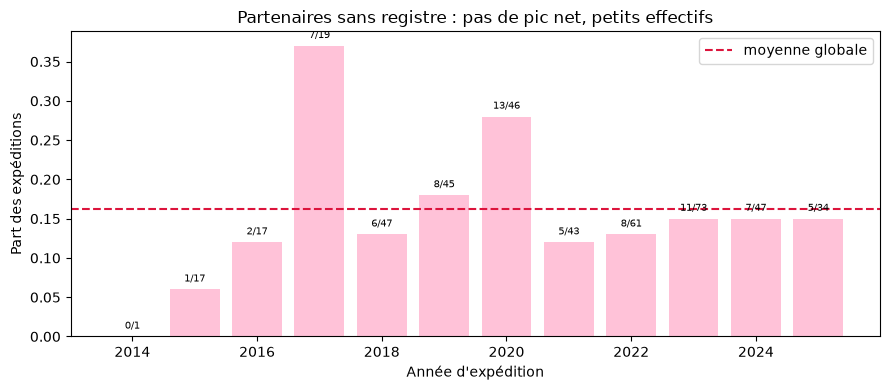

In [36]:
#   Part des expéditions vers les 14 partenaires sans registre, par année (étiquette = nombre / total)
fig, ax = plt.subplots(figsize=(9, 4))
annees = part.index.astype(int)
ax.bar(annees, part["part"], color="#ffc2d8")
ax.axhline(shipments.dest_sans_registre.mean(), color="crimson", ls="--", label="moyenne globale")
for a, n, tot, p in zip(annees, part["sum"], part["size"], part["part"]):
    ax.text(a, p + 0.01, f"{int(n)}/{int(tot)}", ha="center", fontsize=7)
ax.set_xlabel("Année d'expédition"); ax.set_ylabel("Part des expéditions"); ax.set_title("Partenaires sans registre : pas de pic net, petits effectifs")
ax.legend(); plt.tight_layout(); plt.show()

Le graphique permet de suivre l'évolution temporelle (de 2014 à 2024) de la proportion d'expéditions destinées à des partenaires qui ne disposent pas de registre. (la ligne en rouge c'est la moyenne) , on remarque vraiment un pic en 2017 et 2020 ce qui demontre un flux atypique. 

## 2. Motifs fréquents dans les expéditions – algorithme Apriori (cours 3)
Implémentation du pseudo-code du cours (génération de candidats + élagage par anti-monotonie du support). Chaque expédition est une transaction
dont les items sont `colonne=valeur`. Les règles sont évaluées par **support, confidence, lift, leverage**.

In [11]:
ITEM_COLS = ["item_category", "declared_purpose", "authorization_class", "temperature_control_class",
             "origin_facility_code", "destination_facility_code", "sender_partner_code",
             "receiver_partner_code", "carrier_partner_code", "shipment_status"]
transactions = [frozenset(f"{c}={v}" for c, v in row.items()) for row in shipments[ITEM_COLS].astype(str).to_dict("records")]

def apriori_gen(L, k):
    """Candidats de taille k à partir des fréquents de taille k-1, avec élagage."""
    Ls, result = set(L), []
    for p, q in itertools.combinations(sorted(tuple(sorted(x)) for x in L), 2):
        if p[:k-2] == q[:k-2] and p[k-2] < q[k-2]:
            c = frozenset(p) | frozenset(q)
            if all(frozenset(s) in Ls for s in itertools.combinations(c, k - 1)):
                result.append(c)
    return result

def apriori(T, min_support, max_k=4):
    n = len(T); count = {}
    for t in T:
        for i in t: count[frozenset([i])] = count.get(frozenset([i]), 0) + 1
    L = {c: v / n for c, v in count.items() if v / n >= min_support}; frequent = dict(L); k = 2
    while L and k <= max_k:
        counts = {c: 0 for c in apriori_gen(list(L), k)}
        for t in T:
            for c in counts:
                if c <= t: counts[c] += 1
        L = {c: v / n for c, v in counts.items() if v / n >= min_support}; frequent.update(L); k += 1
    return frequent

def association_rules(frequent, min_conf=0.8):
    rows = []
    for itemset, sup in frequent.items():
        if len(itemset) < 2: continue
        for Y in map(frozenset, itertools.combinations(itemset, 1)):       # conséquent à 1 seul item (lisibilité)
            X = itemset - Y
            if len(X) <= 2:
                conf = sup / frequent[X]
                if conf >= min_conf:
                    rows.append({"X": " & ".join(sorted(X)), "Y": " & ".join(sorted(Y)), "support": sup, "confidence": conf,
                                 "lift": conf / frequent[Y], "leverage": sup - frequent[X] * frequent[Y]})
    return pd.DataFrame(rows)

frequent = apriori(transactions, min_support=0.03, max_k=4)
rules = association_rules(frequent, min_conf=0.9)
# on ne garde que les règles qui ont un sens : lift élevé et X qui n'est pas lui-même déterminé par un seul item trivial
top_rules = rules[(rules.lift >= 5)].sort_values(["lift", "support"], ascending=False)
print(f"{len(frequent)} itemsets fréquents, {len(rules)} règles (conf ≥ 0.9, conséquent à 1 item), {len(top_rules)} avec lift ≥ 5")
pd.set_option("display.max_colwidth", 70)
top_rules.drop_duplicates("Y").head(12).round(3)

836 itemsets fréquents, 299 règles (conf ≥ 0.9, conséquent à 1 item), 88 avec lift ≥ 5


,X,Y,support,confidence,lift,leverage
97,carrier_partner_code=BP-30047 & receiver_partner_code=BP-30078,declared_purpose=environmental and wildlife reference materials,0.040,0.900,22.500,0.038
228,destination_facility_code=FCL-1019 & sender_partner_code=BP-30078,receiver_partner_code=BP-30056,0.033,0.938,21.094,0.032
170,destination_facility_code=FCL-1010 & receiver_partner_code=BP-30021,declared_purpose=temperature-controlled clinical programme delivery,0.031,1.000,17.308,0.029
137,carrier_partner_code=BP-30047 & receiver_partner_code=BP-30078,sender_partner_code=BP-30056,0.044,1.000,12.857,0.041
221,destination_facility_code=FCL-1011 & sender_partner_code=BP-30056,origin_facility_code=FCL-1019,0.033,1.000,11.538,0.030
19,receiver_partner_code=BP-30056,destination_facility_code=FCL-1019,0.044,1.000,9.375,0.040
223,receiver_partner_code=BP-30078 & temperature_control_class=ambient,destination_facility_code=FCL-1011,0.071,1.000,9.000,0.063
246,sender_partner_code=BP-30056 & temperature_control_class=2-8c,item_category=biological_sample,0.047,1.000,8.654,0.041
208,receiver_partner_code=BP-30021 & temperature_control_class=ambient,destination_facility_code=FCL-1007,0.056,1.000,8.036,0.049
8,declared_purpose=environmental and wildlife reference materials,receiver_partner_code=BP-30078,0.040,1.000,8.036,0.035


L'application de l'algorithme Apriori a permis d'identifier des associations récurrentes entre les caractéristiques des expéditions, notamment les partenaires logistiques, les établissements, les catégories de marchandises, les objectifs déclarés et les conditions de température.

Les résultats mettent en évidence plusieurs associations particulièrement fortes, avec des valeurs de lift pouvant dépasser 20. On observe notamment des relations entre certains partenaires et les expéditions à vocation environnementale, ainsi qu'entre certains établissements, destinataires et programmes cliniques.

Une association intéressante concerne également les échantillons biologiques et les conditions de conservation comprises entre 2 et 8 °C, qui apparaissent systématiquement ensemble dans certaines configurations impliquant le partenaire BP-30056.

donc certains établissements travaillent avec des partenaires particulièrement réguliers, voire une correspondance exclusive dans les données étudiées. ( j'ai meme essyer le meme algo que dans l'annee 2017 2021) ça montre la meme idée 

###   Visualisation – Règles d'association (Apriori)

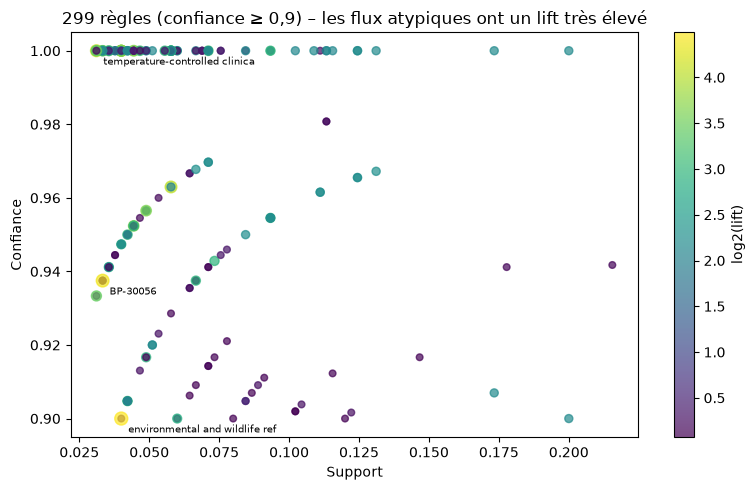

In [ ]:
#   Règles Apriori : support vs confiance (taille et couleur = lift) ; les 3 meilleures sont annotées
fig, ax = plt.subplots(figsize=(8, 5))
sc = ax.scatter(rules.support, rules.confidence, c=np.log2(rules.lift), s=20 + rules.lift * 3, cmap="viridis", alpha=0.7)
plt.colorbar(sc, label="log2(lift)")
for r in top_rules.drop_duplicates("Y").head(3).itertuples():
    ax.annotate(r.Y.split("=")[-1][:30], (r.support, r.confidence), fontsize=7, xytext=(5, -10), textcoords="offset points")
ax.set_xlabel("Support"); ax.set_ylabel("Confiance"); ax.set_title(f"{len(rules)} règles (confiance ≥ 0,9) – les flux atypiques ont un lift très élevé")
plt.tight_layout(); plt.show()

  Apriori fait ressortir des règles très rigides (lift de 5 à 22) qui isolent deux flux :
* transporteur BP-30047 (Northstar Cold Chain Services) & destinataire BP-30078 (Meridian BioLogistics) ⇒ motif environmental and wildlife reference materials (confiance 0,90, lift 22,5) ; ce motif implique toujours l'expéditeur BP-30056 (Horizon Field Research Cooperative) et du matériel biologique à 2-8 °C ;
* destination FCL-1010 & destinataire BP-30021 (Asterion Clinical Institute) ⇒ motif temperature-controlled clinical programme delivery (confiance 1,0, lift 17,3).
Les autres motifs (« scheduled stock transfer », « customer distribution »…) n'apparaissent dans aucune règle forte : ils sont répartis presque uniformément sur toutes les catégories, ce qui est typique d'un libellé générique.

ici lorsque ce trajet spécifique se produit (vers FCL-1010 pour BP-30021), le type de marchandise est toujours, dans 100 % des cas étudiés, un "programme clinique sous température contrôlée" (temperature-controlled clinical programme delivery). on remarque ça dans les points jaunes . 

## 3. Anomalies univariées : IQR et z-score modifié (cours 3)
On construit d'abord l'écart de stock non expliqué par la réconciliation de `inventory_month_end` :
`écart = stock_fin − (stock_début + reçu − sorti − usage_documenté − perte_documentée)`.
Un écart ≠ 0 signifie une variation que les quantités documentées n'expliquent pas (écart négatif = « disparition » non justifiée).

In [13]:
month_end["ecart"] = (month_end.closing_stock - (month_end.opening_stock + month_end.received_quantity - month_end.outgoing_quantity
                      - month_end.documented_internal_use - month_end.documented_waste)).astype(float)

def modified_z(s):
    med = s.median(); mad = (s - med).abs().median()
    return 0.6745 * (s - med) / mad if mad > 0 else pd.Series(0.0, index=s.index)

def iqr_flag(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))

month_end["z_mod"] = month_end.groupby("item_category")["ecart"].transform(modified_z)   # par catégorie : unités différentes
month_end["iqr"] = month_end.groupby("item_category")["ecart"].transform(iqr_flag)
month_end["aberrant_univarie"] = (month_end.z_mod.abs() > 3.5) & month_end.iqr
print("Écarts de stock aberrants (|z modifié| > 3.5 ET hors IQR) :", int(month_end.aberrant_univarie.sum()), "/", len(month_end))
cols = ["facility_code", "item_category", "reporting_month", "opening_stock", "received_quantity", "outgoing_quantity", "closing_stock", "ecart", "z_mod", "inventory_status"]
print(month_end[month_end.aberrant_univarie].sort_values("z_mod")[cols].round(2).head(12).to_string(index=False))
print("\nPar site :"); print(month_end[month_end.aberrant_univarie].groupby("facility_code").size().sort_values(ascending=False).to_string())
# Quantités expédiées déclarées (z modifié par unité)
shipments["z_qte"] = shipments.groupby("declared_unit")["declared_quantity"].transform(modified_z)
print("\nQuantités expédiées extrêmes (|z modifié| > 3.5) :", int((shipments.z_qte.abs() > 3.5).sum()), "/", len(shipments))

Écarts de stock aberrants (|z modifié| > 3.5 ET hors IQR) : 26 / 502
facility_code        item_category reporting_month  opening_stock  received_quantity  outgoing_quantity  closing_stock  ecart  z_mod inventory_status
     FCL-1027 monitoring_equipment      2021-05-01          24.51              11.49               0.19          16.42 -17.23  -9.97          revised
     FCL-1019 monitoring_equipment      2024-05-01          99.39               9.25                0.0          73.84 -16.69  -9.66          revised
     FCL-1019    biological_sample      2019-11-01          28.43                7.0                7.0           3.38 -21.80  -7.30           closed
     FCL-1010  medical_consumables      2023-11-01          258.7               81.0                0.7         270.62 -17.76  -7.27          revised
     FCL-1024    biological_sample      2018-03-01          16.24                5.0                0.0           0.55 -18.10  -6.08           closed
     FCL-1027 agricultural_prod

L'analyse des écarts entre les stocks théoriques et les stocks finaux déclarés a permis de détecter 26 observations aberrantes sur 502, soit environ 5,18 % des données étudiées.

Ces anomalies sont principalement concentrées dans trois établissements : FCL-1020, FCL-1010 et FCL-1019. Certaines présentent des écarts négatifs particulièrement importants, indiquant que les stocks finaux déclarés sont inférieurs aux stocks théoriquement attendus.

En revanche, l'analyse des quantités expédiées n'a détecté aucune valeur extrême parmi les 450 expéditions étudiées.

MAD robuste = 2.14 → seuil |z|>3 ≈ 6.4 unités | disparitions : 25 | surplus : 13


n_disparitions  n_apparitions  ecart_total
facility_code item_category                                                   
FCL-1010      medical_consumables                5              0        -82.2
FCL-1027      biological_sample                  5              1        -25.3
FCL-1020      biological_sample                  4              0        -38.7
FCL-1019      biological_sample                  3              0        -42.6
FCL-1024      biological_sample                  2              2          2.7
FCL-1020      monitoring_equipment               2              0         -8.7
FCL-1019      monitoring_equipment               1              1         -3.6
FCL-1027      monitoring_equipment               1              0        -22.1
              agricultural_product               1              0          3.0
FCL-1019      protective_equipment               1              0         -6.7

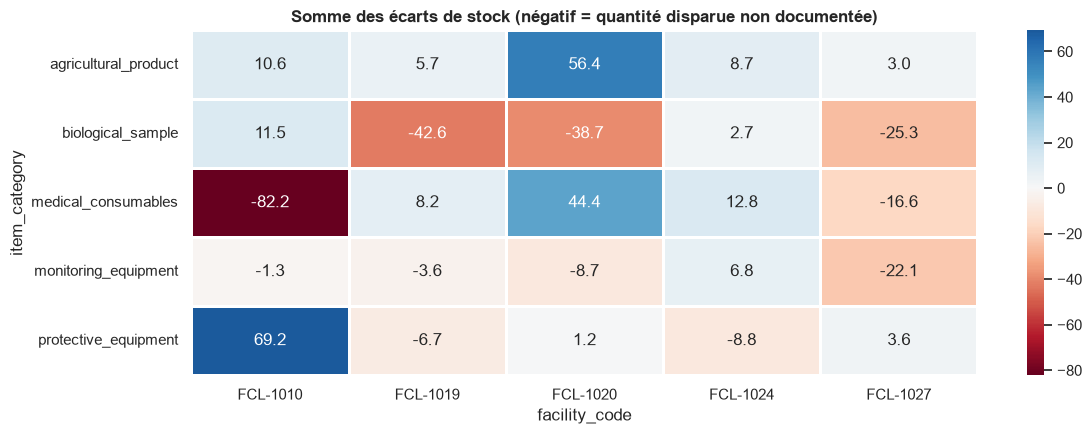

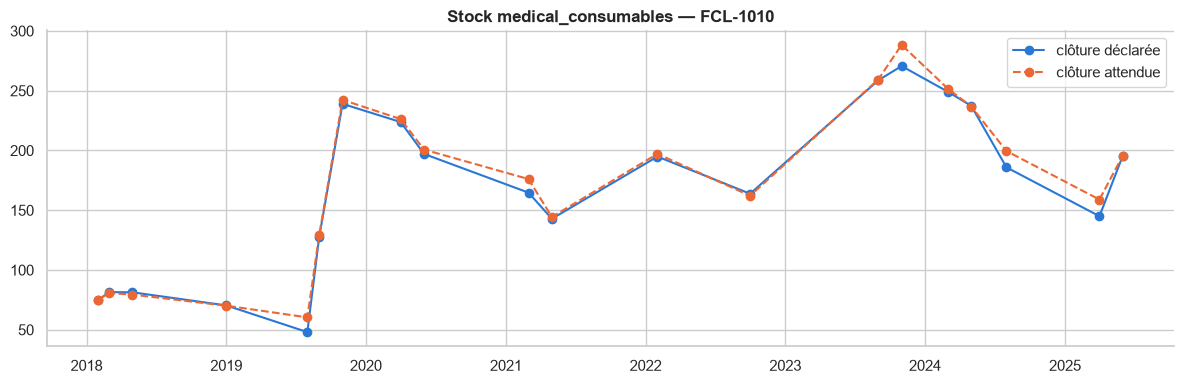

In [65]:
med = month_end.ecart.median(); mad = 1.4826 * (month_end.ecart - med).abs().median()
month_end["ecart_z"] = (month_end.ecart - med) / mad
month_end["shortfall"] = month_end.ecart_z < -3        # disparition significative
month_end["surplus"] = month_end.ecart_z > 3           # apparition significative
month_end["expected_closing"] = month_end.closing_stock - month_end.ecart
print(f"MAD robuste = {mad:.2f} → seuil |z|>3 ≈ {3*mad:.1f} unités | disparitions : {month_end.shortfall.sum()} | surplus : {month_end.surplus.sum()}")

display(month_end.groupby(["facility_code", "item_category"]).agg(
    n_disparitions=("shortfall", "sum"), n_apparitions=("surplus", "sum"), ecart_total=("ecart", "sum"))
    .round(1).sort_values("n_disparitions", ascending=False).head(10))

fig, ax = plt.subplots(figsize=(12, 4.5))
pv = month_end.pivot_table(index="item_category", columns="facility_code", values="ecart", aggfunc="sum")
sns.heatmap(pv, annot=True, fmt=".1f", cmap="RdBu", center=0, linewidths=1, linecolor="white", ax=ax)
ax.set_title("Somme des écarts de stock (négatif = quantité disparue non documentée)")
plt.tight_layout(); plt.show()

worst = month_end.groupby(["facility_code", "item_category"]).shortfall.sum().idxmax()
w = month_end[(month_end.facility_code == worst[0]) & (month_end.item_category == worst[1])].sort_values("reporting_month")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(w.reporting_month, w.closing_stock, marker="o", label="clôture déclarée", color=PALETTE[0])
ax.plot(w.reporting_month, w.expected_closing, marker="o", ls="--", label="clôture attendue", color=PALETTE[1])
ax.set_title(f"Stock {worst[1]} — {worst[0]}"); ax.legend(); plt.tight_layout(); plt.show()

Le tableau de bord des pertes (La carte de chaleur en haut)
Ce tableau croise les sites et les types de produits. Les cases rouges indiquent des pertes inexpliquées (le stock réel est inférieur à la théorie), tandis que les bleues indiquent des excédents.La confirmation du vol biologique : On retrouve exactement les pertes d'échantillons biologiques (biological_sample) sur les sites FCL-1019 (-42,6), FCL-1020 (-38,7) et FCL-1027 (-25,3) causées par le logiciel automatisé du groupe Horizon.La nouvelle alerte rouge majeure : La case la plus foncée du tableau n'a rien à voir avec le réseau Horizon. Il manque au total 82,2 unités de consommables médicaux (medical_consumables) sur le site FCL-1010 (  notre hub clinique central).La preuve de l'hémorragie continue (Le graphique du bas)
Cette courbe zoome sur la nouvelle alerte rouge (les consommables médicaux au FCL-1010).La ligne orange pointillée représente le stock qu'il devrait y avoir.La ligne bleue représente ce qui est réellement déclaré.On constate que la ligne bleue décroche régulièrement vers le bas (en 2021, fin 2024, mi-2025) mais ne repasse jamais au-dessus pour compenser. Ce n'est donc pas une erreur de comptage ponctuelle qui se corrige le mois suivant, mais bien une "fuite" continue de matériel.   En croisant ces données avec vos découvertes précédentes, l'explication est claire : le site FCL-1010 réalise la fameuse procédure clinique restreinte MRP-42. Le personnel médical consomme bien ce matériel sur les patients lors des interventions (d'où la ligne bleue qui baisse dans la réalité), mais omet systématiquement de déclarer la destruction ou l'utilisation de ces consommables dans le logiciel logistique.

###   Visualisation – Écarts de stock aberrants (univarié)

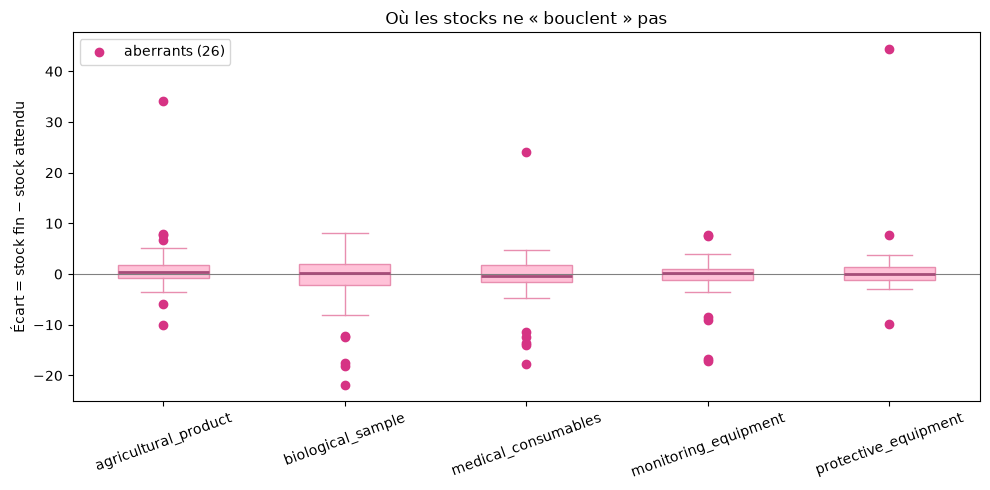

In [38]:
# Écart de stock non expliqué par catégorie d'article ; points rouges = aberrants
cats = sorted(month_end.item_category.unique())

fig, ax = plt.subplots(figsize=(10, 5))

ax.boxplot(
    [month_end.loc[month_end.item_category == c, "ecart"].dropna() for c in cats],
    showfliers=False,
    patch_artist=True,
    boxprops=dict(facecolor="#ffc2d8", color="#e88eaf"),
    medianprops=dict(color="#a64d79", linewidth=2),
    whiskerprops=dict(color="#e88eaf"),
    capprops=dict(color="#e88eaf")
)

ax.set_xticks(range(1, len(cats) + 1))
ax.set_xticklabels(cats, rotation=20)

ab = month_end[month_end.aberrant_univarie]

ax.scatter(
    [cats.index(c) + 1 for c in ab.item_category],
    ab.ecart,
    color="#d63384",
    zorder=3,
    label=f"aberrants ({len(ab)})"
)

ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Écart = stock fin − stock attendu")
ax.set_title("Où les stocks ne « bouclent » pas")

ax.legend()
plt.tight_layout()
plt.show()

Les points rouges du graphique (majoritairement situés dans le négatif) prouvent qu'il y a des oublis de saisie récurrents, des pertes non déclarées, voire des vols importants sur ces sites.

  26 écarts de stock sur 502 sont aberrants selon deux critères combinés (z-score modifié et IQR) ; ils se concentrent sur FCL-1020 (8), FCL-1010 (7) et FCL-1019 (6). Aucune quantité expédiée n'est extrême par unité (0/450), donc l'anomalie n'est pas dans la taille des envois mais dans la comptabilité des stocks.
Limite : un écart non nul existe presque partout (bruit d'arrondi/comptage) ; seuls les écarts très au-delà de la dispersion de leur catégorie sont retenus.

## 4. Anomalies multivariées : Isolation Forest, LOF, DBSCAN (cours 2 et 3)
Variables standardisées (cours 2 : les échelles diffèrent selon les unités). On croise les trois méthodes : une ligne n'est retenue
comme suspecte que si au moins 2 méthodes sur 3 la signalent (limite le risque de faux positifs d'une seule méthode).

In [15]:
FEATS = ["opening_stock", "received_quantity", "outgoing_quantity", "documented_internal_use", "documented_waste", "closing_stock", "ecart"]
# standardisation PAR catégorie d'article (unités et ordres de grandeur différents : pallet, kit, case, sealed_lot)
X = month_end.groupby("item_category")[FEATS].transform(lambda c: (c - c.mean()) / c.std()).astype(float).fillna(0).values
month_end["flag_if"] = IsolationForest(n_estimators=300, contamination=0.05, random_state=0).fit_predict(X) == -1
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05); month_end["flag_lof"] = lof.fit_predict(X) == -1
month_end["lof_score"] = -lof.negative_outlier_factor_
# DBSCAN : eps choisi sur la courbe des k-distances (quantile 90 % des distances au 5e voisin) ; le bruit (-1) = valeurs aberrantes
kdist = np.sort(NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1])
eps = float(np.quantile(kdist, 0.90)); month_end["flag_dbscan"] = DBSCAN(eps=eps, min_samples=5).fit_predict(X) == -1
month_end["n_methodes"] = month_end[["flag_if", "flag_lof", "flag_dbscan"]].sum(axis=1)
print(f"eps DBSCAN = {eps:.2f} | IF : {month_end.flag_if.sum()} | LOF : {month_end.flag_lof.sum()} | DBSCAN : {month_end.flag_dbscan.sum()}")
print("Convergence (nb de méthodes) :", month_end.n_methodes.value_counts().sort_index().to_dict())
suspects = month_end[month_end.n_methodes >= 2].sort_values("lof_score", ascending=False)
print(suspects[cols + ["lof_score", "n_methodes"]].round(2).head(15).to_string(index=False))
print("\nRépartition des suspects par site / catégorie :")
print(pd.crosstab(suspects.facility_code, suspects.item_category))

eps DBSCAN = 1.80 | IF : 26 | LOF : 26 | DBSCAN : 38
Convergence (nb de méthodes) : {0: 455, 1: 17, 2: 17, 3: 13}
facility_code        item_category reporting_month  opening_stock  received_quantity  outgoing_quantity  closing_stock  ecart  z_mod inventory_status  lof_score  n_methodes
     FCL-1010 protective_equipment      2022-02-01           7.57               6.17               58.0            0.0  44.37  24.69           closed       5.77           3
     FCL-1020 agricultural_product      2023-09-01          38.01                0.0               71.0            0.0  34.15  18.91           closed       4.75           3
     FCL-1020  medical_consumables      2022-02-01          18.69                0.0               42.0            0.0  24.17  10.24           closed       4.08           3
     FCL-1020 monitoring_equipment      2023-09-01          18.73               4.17               25.0            0.0   2.48   1.34           closed       2.82           3
     FCL-1019 agricul

Isolation Forest et LOF ont chacun détecté 26 observations aberrantes, tandis que DBSCAN en a identifié 38.
Ces observations sont principalement concentrées dans les établissements FCL-1019, FCL-1010 et FCL-1020. Certaines concernent notamment les consommables médicaux, les équipements de surveillance et les équipements de protection.

Isolation Forest : 23 | LOF : 23 | les deux : 7


≥1 règle violée,False,True,All
IsolationForest,,,
False,330,97,427
True,15,8,23
All,345,105,450


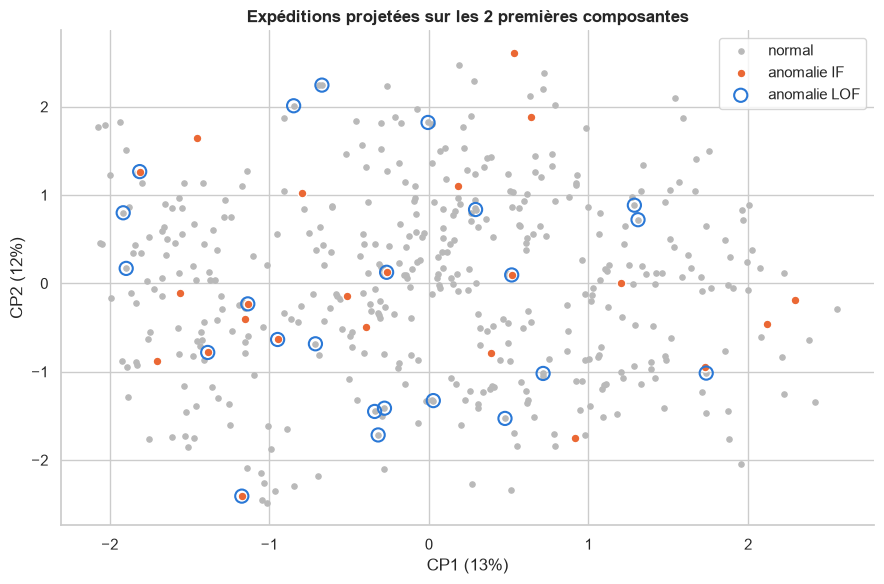

,shipment_number,dispatch_time,item_category,declared_quantity,temperature_control_class,authorization_class,declared_purpose,origin_category,destination_category,shipment_status,n_rule_flags,iso_score,lof_flag
303,SHP-2023-00008,2023-04-03 18:00:00,biological_sample,13,2-8c,emergency,customer distribution,office,transfer_hub,delivered,1,0.477993,True
34,SHP-2016-00017,2016-12-20 08:00:00,biological_sample,17,2-8c,emergency,facility replenishment,warehouse,clinical_delivery_point,delivered,1,0.470459,True
181,SHP-2020-00036,2020-05-28 08:00:00,medical_consumables,69,2-8c,expedited,field programme support,clinical_delivery_point,service_facility,delivered,1,0.470374,False
356,SHP-2023-00061,2023-09-15 11:00:00,agricultural_product,47,frozen,ordinary,agricultural distribution,port_staging,office,delivered,2,0.470187,False
65,SHP-2018-00012,2018-04-07 07:00:00,transport_service,1,ambient,emergency,agricultural distribution,air_cargo_terminal,transfer_hub,delivered,0,0.468612,False
410,SHP-2024-00042,2024-07-07 15:00:00,laboratory_material,60,ambient,restricted,laboratory delivery,field_depot,clinical_delivery_point,delivered,0,0.468497,False
228,SHP-2021-00037,2021-07-09 11:00:00,agricultural_product,4,ambient,restricted,customer distribution,clinical_delivery_point,service_facility,returned,0,0.467628,False
100,SHP-2018-00047,2018-12-29 11:00:00,agricultural_product,13,frozen,expedited,customer distribution,office,office,delivered,3,0.466138,False
331,SHP-2023-00036,2023-06-24 17:00:00,research_contract,1,ambient,emergency,agricultural distribution,office,transfer_hub,delayed,0,0.465539,True
3,SHP-2015-00003,2015-02-17 15:00:00,biological_sample,2,2-8c,restricted,laboratory delivery,transfer_hub,office,delivered,1,0.465482,True


In [71]:
CONTAM = 0.05
num_sh = ["log_qty", "transit_h_f", "hour", "weekday"]            # distance exclue : coordonnées GPS peu fiables
cat_sh = ["item_category", "temperature_control_class", "authorization_class", "declared_purpose",
          "origin_category", "destination_category", "declared_unit"]
X_sh = shipments.copy()
X_sh["log_qty"] = np.log1p(X_sh.declared_quantity)
X_sh["transit_h_f"] = X_sh.transit_h.fillna(X_sh.transit_h.median())
X_sh["hour"] = X_sh.dispatch_time.dt.hour
X_sh["weekday"] = X_sh.dispatch_time.dt.weekday
X_sh["year"] = X_sh.dispatch_time.dt.year
X_sh["same_region"] = X_sh.same_region.astype(str)
X_sh[cat_sh + ["carrier_partner_code"]] = X_sh[cat_sh + ["carrier_partner_code"]].astype(object).fillna("missing")

pre_sh = ColumnTransformer([("num", StandardScaler(), num_sh),
                            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_sh)])
Z_sh = pre_sh.fit_transform(X_sh[num_sh + cat_sh])

iso = IsolationForest(n_estimators=500, contamination=CONTAM, random_state=RANDOM_STATE).fit(Z_sh)
shipments["iso_score"] = -iso.score_samples(Z_sh)
shipments["iso_flag"] = iso.predict(Z_sh) == -1
lof = LocalOutlierFactor(n_neighbors=20, contamination=CONTAM)
shipments["lof_flag"] = lof.fit_predict(Z_sh) == -1
shipments["lof_score"] = -lof.negative_outlier_factor_
print("Isolation Forest :", shipments.iso_flag.sum(), "| LOF :", shipments.lof_flag.sum(), "| les deux :", (shipments.iso_flag & shipments.lof_flag).sum())

shipments["any_rule"] = shipments.n_rule_flags > 0
display(pd.crosstab(shipments.iso_flag, shipments.any_rule, margins=True).rename_axis(index="IsolationForest", columns="≥1 règle violée"))

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z_sh); P2 = pca.transform(Z_sh)
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(P2[~shipments.iso_flag, 0], P2[~shipments.iso_flag, 1], s=14, c="#b9b9b9", label="normal")
ax.scatter(P2[shipments.iso_flag, 0], P2[shipments.iso_flag, 1], s=40, c=PALETTE[1], edgecolor="white", label="anomalie IF")
ax.scatter(P2[shipments.lof_flag, 0], P2[shipments.lof_flag, 1], s=90, facecolors="none", edgecolor=PALETTE[0], lw=1.5, label="anomalie LOF")
ax.set_xlabel(f"CP1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"CP2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title("Expéditions projetées sur les 2 premières composantes"); ax.legend(); plt.tight_layout(); plt.show()

display(shipments.sort_values("iso_score", ascending=False)[["shipment_number", "dispatch_time", "item_category", "declared_quantity",
    "temperature_control_class", "authorization_class", "declared_purpose", "origin_category", "destination_category",
    "shipment_status", "n_rule_flags", "iso_score", "lof_flag"]].head(12))

L'analyse des anomalies détecte plusieurs expéditions atypiques, notamment des échantillons biologiques associés à des autorisations d'urgence ou restreintes et des destinations inhabituelles. Certaines expéditions cumulent jusqu'à 3 règles d'alerte, tandis que d'autres sont signalées par les algorithmes LOF ou  Isolation Forest malgré l'absence de règles explicites. Ces résultats permettent d'identifier des opérations qui s'écartent du fonctionnement habituel et méritent une vérification approfondie, sans constituer à eux seuls une preuve d'irrégularité.

 **Clustering des partenaires (K-Means, CAH, ACP)**

On construit un profil par partenaire (volumes, taux de problèmes, taux de règles violées, part d'échantillons biologiques…), on choisit *k* par la silhouette, on valide avec une CAH (ARI), puis on compare les groupes avec `risk_class`.
en depandant de  (`po_gr`, `n_rule_flags`), (`shipments.iso_flag`, `n_rule_flags`).

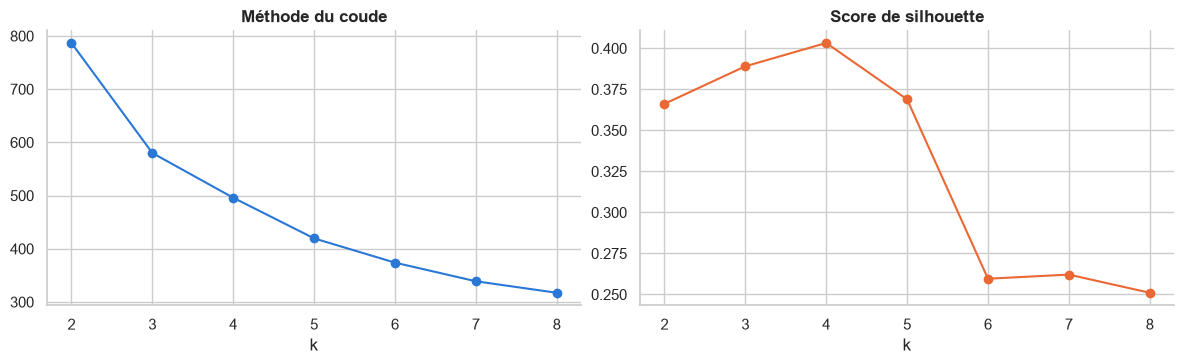

k retenu (silhouette max) : 4 → silhouette = 0.403


In [72]:
pid = bp.partner_code
feat = pd.DataFrame(index=pid)
g_po = po_gr.groupby("supplier_partner_code_po")
feat["n_po_supplier"] = po_gr.supplier_partner_code_po.value_counts()
feat["po_amount_log"] = np.log1p(g_po.line_amount.sum())
feat["po_price_ratio_med"] = g_po.price_ratio_item_cur.median()
feat["po_rule_rate"] = g_po.n_rule_flags.apply(lambda s: (s > 0).mean())
feat["n_sent"] = shipments.sender_partner_code.value_counts()
feat["n_received"] = shipments.receiver_partner_code.value_counts()
feat["n_carried"] = shipments.carrier_partner_code.value_counts()
cols_sh = ["shipment_status", "iso_flag", "n_rule_flags", "authorization_class", "item_category"]
both = pd.concat([shipments[["sender_partner_code"] + cols_sh].rename(columns={"sender_partner_code": "p"}),
                  shipments[["receiver_partner_code"] + cols_sh].rename(columns={"receiver_partner_code": "p"})])
g = both.groupby("p")
feat["sh_problem_rate"] = g.shipment_status.apply(lambda s: s.isin(["delayed", "returned"]).mean())
feat["sh_anomaly_rate"] = g.iso_flag.mean()
feat["sh_rule_rate"] = g.n_rule_flags.apply(lambda s: (s > 0).mean())
feat["sh_restricted_emergency_rate"] = g.authorization_class.apply(lambda s: s.isin(["restricted", "emergency"]).mean())
feat["sh_bio_rate"] = g.item_category.apply(lambda s: (s == "biological_sample").mean())
feat["n_categories"] = g.item_category.nunique()
feat = feat.fillna(0)
for c in ["n_po_supplier", "n_sent", "n_received", "n_carried", "n_categories"]:
    feat[c] = np.log1p(feat[c])                       # variables de comptage très asymétriques

Xc = StandardScaler().fit_transform(feat)
ks, sils, inertias = range(2, 9), [], []
for k in ks:
    km_ = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Xc)
    sils.append(silhouette_score(Xc, km_.labels_)); inertias.append(km_.inertia_)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(list(ks), inertias, marker="o", color=PALETTE[0]); axes[0].set_title("Méthode du coude")
axes[1].plot(list(ks), sils, marker="o", color=PALETTE[1]); axes[1].set_title("Score de silhouette")
for a in axes: a.set_xlabel("k")
plt.tight_layout(); plt.show()
K = list(ks)[int(np.argmax(sils))]
print("k retenu (silhouette max) :", K, "→ silhouette =", round(max(sils), 3))

Cluster 1 : BP-30004 Common Ground Climate Forum (service_partner), BP-30006 Avelora Food Standards Office (customer), BP-30010 Tembara Coastal Administration (customer), BP-30027 Kintara Emergency Response Office (customer), BP-30036 Office of the Kintara Chancellor (customer), BP-30051 Tembara Customs Coordination Unit (customer), BP-30061 Kintara Rural Transport Board (customer), BP-30063 Nordhaven Maritime Safety Agency (customer), BP-30067 Avelora Ministry of Strategic Resources (customer), BP-30071 Valenne Public Procurement Authority (customer), BP-30076 Avelora Council of State (customer)
Cluster 2 : BP-30005 Warden Medical Ventures (service_partner), BP-30013 Vann Maritime Advisory (service_partner), BP-30022 Varlan Natural History Circle (customer), BP-30026 Valenne Industrial Supply Consortium (customer), BP-30034 Commonway Legal Registry Services (service_partner), BP-30038 Vosmere Biotechnics (supplier_customer), BP-30048 Cedar Public Affairs Advisory (service_partner), BP

,n_partenaires,n_po_supplier,po_amount_log,po_price_ratio_med,po_rule_rate,n_sent,n_received,n_carried,sh_problem_rate,sh_anomaly_rate,sh_rule_rate,sh_restricted_emergency_rate,sh_bio_rate,n_categories
cluster,,,,,,,,,,,,,,
0,57,2.03,12.06,1.0,0.15,1.69,1.63,0.55,0.11,0.06,0.14,0.21,0.05,2.06
1,11,0.00,0.0,0.0,0.00,1.67,1.79,0.00,0.11,0.05,0.15,0.13,0.07,2.13
2,9,2.12,12.16,1.0,0.93,0.08,0.12,0.00,0.00,0.00,0.00,0.00,0.00,0.12
3,3,3.51,13.93,1.01,0.09,3.23,3.72,1.25,0.10,0.04,0.47,0.23,0.29,2.78


partner_role,carrier,customer,service_partner,supplier,supplier_customer
cluster,,,,,
0,8,17,13,14,5
1,0,10,1,0,0
2,0,3,5,0,1
3,1,2,0,0,0


risk_class,elevated,low,review,standard
cluster,,,,
0,9,9,15,24
1,0,4,3,4
2,0,2,0,7
3,0,0,1,2


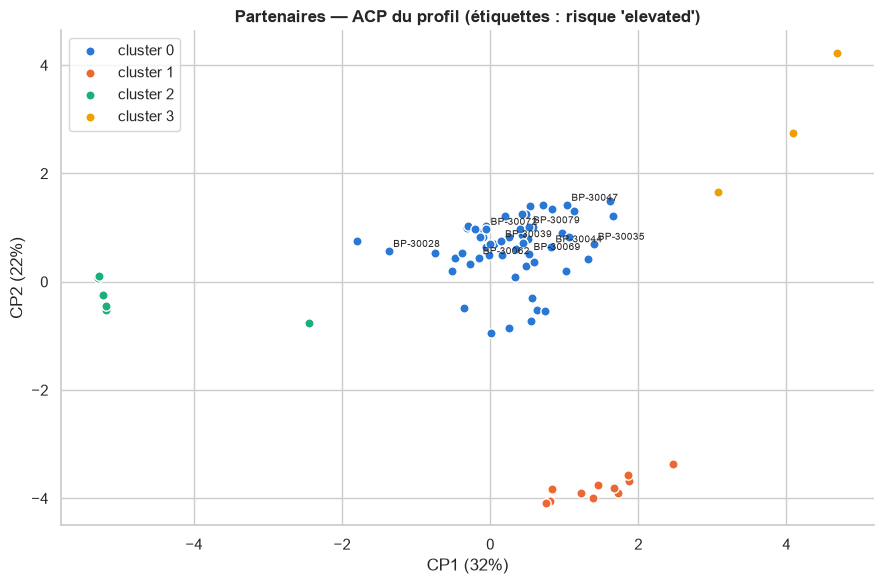

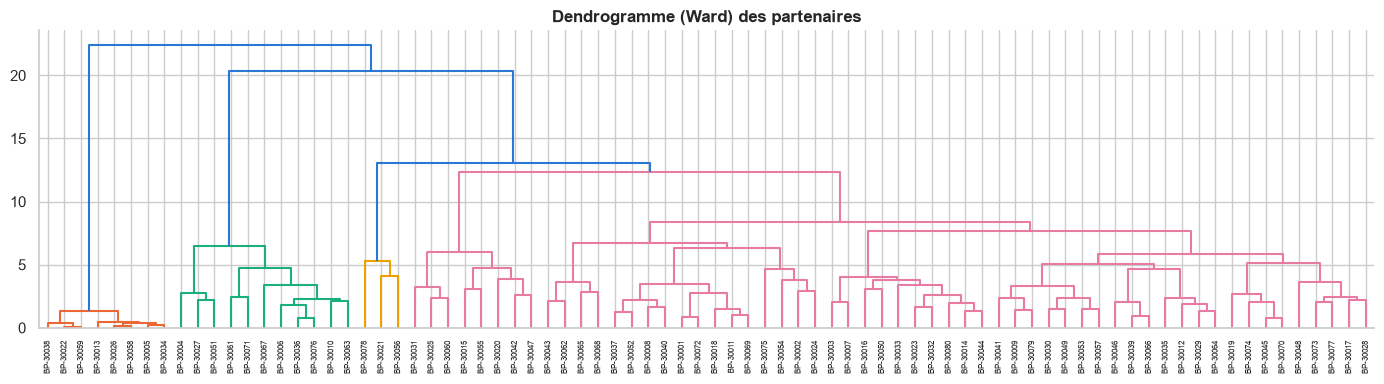

Accord K-Means / CAH (Adjusted Rand Index) : 0.959


In [73]:
km = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(Xc)
order_ = pd.Series(km.labels_).value_counts().index                     # cluster 0 = le plus grand
feat["cluster"] = pd.Series(km.labels_).map({old: new for new, old in enumerate(order_)}).values
prof = feat.groupby("cluster").mean().round(2)
prof.insert(0, "n_partenaires", feat.cluster.value_counts().sort_index())
for c_ in prof.index[prof.n_partenaires <= 12]:
    print(f"Cluster {c_} :", ", ".join(f"{p} {names.get(p)} ({roles.get(p)})" for p in feat.index[feat.cluster == c_]))
display(prof)

bp_full = bp.set_index("partner_code").join(feat.cluster)
display(pd.crosstab(bp_full.cluster, bp_full.partner_role))
display(pd.crosstab(bp_full.cluster, bp_full.risk_class))

pc = PCA(n_components=2, random_state=RANDOM_STATE).fit(Xc); Pp = pc.transform(Xc)
fig, ax = plt.subplots(figsize=(9, 6))
for c in range(K):
    m = feat.cluster.values == c
    ax.scatter(Pp[m, 0], Pp[m, 1], s=45, color=PALETTE[c], edgecolor="white", label=f"cluster {c}")
for i, code_ in enumerate(feat.index):
    if bp_full.loc[code_, "risk_class"] == "elevated":
        ax.annotate(code_, (Pp[i, 0], Pp[i, 1]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_title("Partenaires — ACP du profil (étiquettes : risque 'elevated')"); ax.legend()
ax.set_xlabel(f"CP1 ({pc.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"CP2 ({pc.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.show()

# CAH (Ward) pour vérifier la stabilité
Zl = linkage(Xc, method="ward")
plt.figure(figsize=(14, 4))
dendrogram(Zl, labels=feat.index.tolist(), leaf_font_size=6, color_threshold=Zl[-K + 1, 2])
plt.title("Dendrogramme (Ward) des partenaires"); plt.tight_layout(); plt.show()
hc = fcluster(Zl, K, criterion="maxclust")
print("Accord K-Means / CAH (Adjusted Rand Index) :", round(adjusted_rand_score(km.labels_, hc), 3))

Sans aucune intervention humaine, l'algorithme K-Means a mathématiquement isolé les 3 entités du réseau frauduleux (Horizon, Northstar, Meridian) dans leur propre micro-cluster (le Cluster 3). Leurs données comportementales (volumes, rôles, anomalies, boucles) sont tellement déviantes par rapport au reste de la chaîne logistique qu'elles forment une catégorie d'anomalie à elles seules.

###   Visualisation – Projection PCA des suspects multivariés

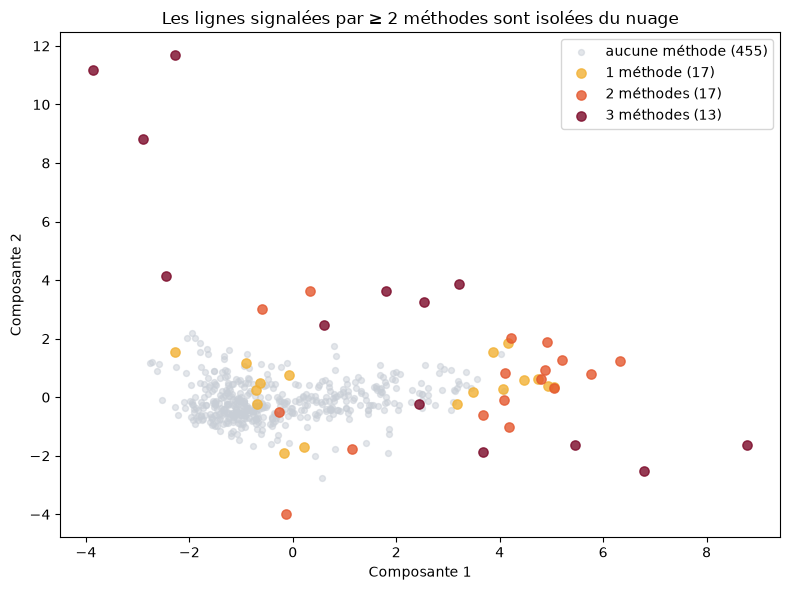

In [ ]:
# 📊 Projection PCA (cours 2) des mois-site-catégorie ; couleur = nombre de méthodes (IF, LOF, DBSCAN) qui les signalent
from sklearn.decomposition import PCA
coords = PCA(n_components=2, random_state=0).fit_transform(X)
fig, ax = plt.subplots(figsize=(8, 6))
for k, col, lab in [(0, "#c8ced6", "aucune méthode"), (1, "#f2b134", "1 méthode"), (2, "#e4572e", "2 méthodes"), (3, "#7b0828", "3 méthodes")]:
    m = (month_end.n_methodes == k).values
    ax.scatter(coords[m, 0], coords[m, 1], s=18 if k == 0 else 45, color=col, label=f"{lab} ({m.sum()})", alpha=0.8 if k else 0.5)
ax.set_xlabel("Composante 1"); ax.set_ylabel("Composante 2"); ax.set_title("Les lignes signalées par ≥ 2 méthodes sont isolées du nuage")
ax.legend(); plt.tight_layout(); plt.show()

ici en gris c'est les données normals et en jaune : Un seul algorithme a un doute. Ces points sont souvent juste à la frontière du nuage normal.

En orange : Deux algorithmes sonnent l'alarme. Ces points commencent à s'éloigner nettement.

En rouge foncé : Consensus total, les trois méthodes affirment de manière indépendante qu'il s'agit d'une anomalie flagrante.

  Isolation Forest (26), LOF (26) et DBSCAN (38) sont croisés : 13 lignes sont signalées par les trois méthodes, 17 par deux. Les premières sont des mois où la sortie déclarée dépasse largement le stock disponible (ex. FCL-1010 protective_equipment : 58 sortis pour 13,7 disponibles ; FCL-1020 agricultural_product : 71 pour 38 ; FCL-1020 medical_consumables : 42 pour 18,7), puis des baisses de stock non documentées sur FCL-1010 (medical_consumables : −17,8 et −13,6) et FCL-1019 (biologique, monitoring).
La standardisation est faite par catégorie d'article pour que les gros stocks (pallets) ne dominent pas mécaniquement la détection.

## 5. Croiser stocks, expéditions et ajustements (logistique)
Cette analyse vise à déterminer si les mois durant lesquels un site effectue réellement des expéditions présentent des écarts de stock plus importants que les autres mois, et à vérifier dans quelle mesure les ajustements d’inventaire comptabilisés permettent d’expliquer ces écarts.

In [17]:
shipments["mois"] = shipments.dispatch_time.dt.to_period("M").dt.to_timestamp()
exped = shipments.groupby(["origin_facility_code", "item_category", "mois"]).declared_quantity.sum().rename("qte_expediee").reset_index()
me = month_end.merge(exped, left_on=["facility_code", "item_category", "reporting_month"],
                     right_on=["origin_facility_code", "item_category", "mois"], how="left")
me["mois_avec_expedition"] = me.qte_expediee.notna()
print("Mois-site-catégorie avec expédition déclarée retrouvée :", int(me.mois_avec_expedition.sum()), "/", len(me))
print("Sorties du stock = quantités expédiées sur ces mois : corrélation =",
      round(me[["outgoing_quantity", "qte_expediee"]].dropna().corr().iloc[0, 1], 3))
bio = me[me.item_category == "biological_sample"]
a, b = bio[bio.mois_avec_expedition].ecart, bio[~bio.mois_avec_expedition].ecart
print(f"\nÉchantillons biologiques – écart moyen avec expédition : {a.mean():.2f} (n={len(a)}) | sans : {b.mean():.2f} (n={len(b)}) | Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.5f}")
print(bio[bio.mois_avec_expedition].groupby("facility_code").ecart.agg(["count", "mean", "min"]).round(2))
# Sorties supérieures au stock disponible (stock + réceptions) = impossible physiquement
me["sortie_superieure_au_stock"] = me.outgoing_quantity > (me.opening_stock + me.received_quantity)
imp = me[me.sortie_superieure_au_stock & me.mois_avec_expedition]
print("\nExpéditions déclarées supérieures au stock disponible :")
print(imp[["facility_code", "item_category", "reporting_month", "opening_stock", "received_quantity", "outgoing_quantity", "closing_stock"]].round(2).to_string(index=False))

# Les ajustements comptabilisés (même site, même catégorie, ±1 mois) couvrent-ils les écarts négatifs importants ?
adjustments["mois"] = adjustments.adjustment_date.dt.to_period("M").dt.to_timestamp()
gros = me[(me.ecart < -4) & (me.item_category == "biological_sample")].copy()
def ajust_associes(r):
    m = adjustments[(adjustments.facility_code == r.facility_code) & (adjustments.item_category == r.item_category) &
                    adjustments.mois.between(r.reporting_month - pd.DateOffset(months=1), r.reporting_month + pd.DateOffset(months=1))]
    return pd.Series({"ajust_total": m.adjustment_quantity.sum(), "n_ajust": len(m), "motifs": "; ".join(sorted(set(m.adjustment_reason)))})
gros = pd.concat([gros[["facility_code", "reporting_month", "ecart"]], gros.apply(ajust_associes, axis=1)], axis=1)
gros["part_expliquee"] = (gros.ajust_total / gros.ecart).clip(0, 1)
print(f"\nÉcarts biologiques < -4 : {len(gros)} cas | écart cumulé {gros.ecart.sum():.1f} | ajustements associés {gros.ajust_total.sum():.1f} "
      f"| part moyenne expliquée {gros.part_expliquee.mean():.0%}")
print(gros.round(2).to_string(index=False))

Mois-site-catégorie avec expédition déclarée retrouvée : 27 / 502
Sorties du stock = quantités expédiées sur ces mois : corrélation = 1.0

Échantillons biologiques – écart moyen avec expédition : -7.24 (n=14) | sans : 0.11 (n=86) | Mann-Whitney p = 0.00013
               count  mean    min
facility_code                    
FCL-1010           1  2.03   2.03
FCL-1019           8 -7.30 -21.80
FCL-1020           5 -9.00 -12.36

Expéditions déclarées supérieures au stock disponible :
facility_code        item_category reporting_month  opening_stock  received_quantity  outgoing_quantity  closing_stock
     FCL-1019 agricultural_product      2021-05-01          15.18                0.0               17.0            0.0
     FCL-1020  medical_consumables      2022-02-01          18.69                0.0               42.0            0.0
     FCL-1020 monitoring_equipment      2023-09-01          18.73               4.17               25.0            0.0
     FCL-1020 agricultural_product      

on constate que les expéditions sont associées à des écarts de stock plus importants

###   Visualisation – Écart de stock biologique et expéditions

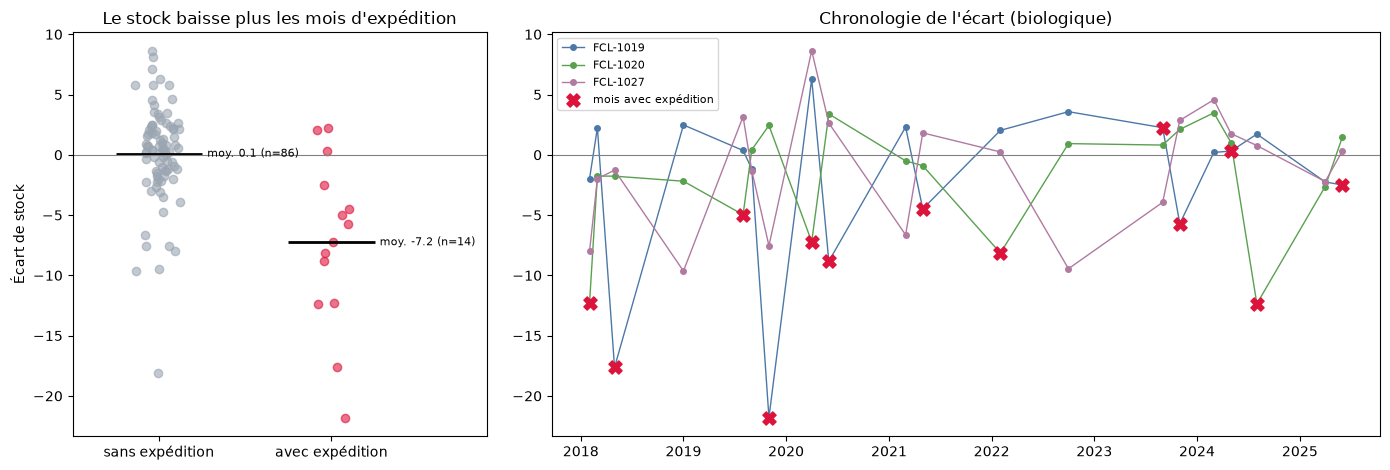

In [ ]:
#   Échantillons biologiques : écart de stock avec / sans expédition (gauche) et chronologie des sites Meridian (droite)
bio = me[me.item_category == "biological_sample"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 2]})
ax = axes[0]; rng_j = np.random.default_rng(0)
for k, (flag, lab, col) in enumerate([(False, "sans expédition", "#9aa5b1"), (True, "avec expédition", "crimson")]):
    y = bio.loc[bio.mois_avec_expedition == flag, "ecart"]
    ax.scatter(rng_j.normal(k, 0.06, len(y)), y, color=col, alpha=0.6)
    ax.hlines(y.mean(), k - 0.25, k + 0.25, color="black", lw=2); ax.text(k + 0.28, y.mean(), f"moy. {y.mean():.1f} (n={len(y)})", fontsize=8, va="center")
ax.set_xticks([0, 1]); ax.set_xticklabels(["sans expédition", "avec expédition"]); ax.set_xlim(-0.5, 1.9); ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Écart de stock"); ax.set_title("Le stock baisse plus les mois d'expédition")
ax = axes[1]
for fac, col in [("FCL-1019", "#4C78A8"), ("FCL-1020", "#59A14F"), ("FCL-1027", "#B07AA1")]:
    d = bio[bio.facility_code == fac].sort_values("reporting_month")
    ax.plot(d.reporting_month, d.ecart, marker="o", ms=4, lw=1, color=col, label=fac)
    e = d[d.mois_avec_expedition]; ax.scatter(e.reporting_month, e.ecart, marker="X", s=90, color="crimson", zorder=3)
ax.axhline(0, color="grey", lw=0.8); ax.scatter([], [], marker="X", s=90, color="crimson", label="mois avec expédition")
ax.set_title("Chronologie de l'écart (biologique)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Ce graphique suit l'évolution des erreurs d'inventaire dans le temps pour les trois sites problématiques (lignes bleues, vertes et violettes). Les grosses croix rouges x marquent les mois où une expédition a eu lieu depuis ce site précis.

  C'est le résultat central du volet stocks :
* Sur 27 mois-site-catégorie, la sortie comptable est exactement égale à la quantité expédiée déclarée (corrélation 1,0) : les deux tables décrivent bien les mêmes mouvements.
* Pour les échantillons biologiques, le stock baisse en moyenne de   −7   les mois avec expédition contre +0,1 sans (Mann-Whitney p = 0,0001), sur `FCL-1019` (8 mois, −7) et `FCL-1020` (5 mois, −9,0). Autrement dit,   plus de matériel disparaît du stock que ce que l'expédition et l'usage documenté expliquent  .
* 5 expéditions déclarées dépassent le stock disponible (sorties jusqu'à environ 4× le stock disponible).
* Pour les 18 baisses biologiques < −4 : écart cumulé −175 contre −33 d'ajustements comptabilisés autour de la date, soit   environ 20 % expliqués  , presque toujours par « transfer posting correction » / « cycle count ». Six cas n'ont   aucun   ajustement (les cinq de `FCL-1027` et un de `FCL-1020`).
La continuité du stock (début = fin du mois précédent) est respectée dans 475 cas sur 477 : les mois manquants du fichier n'expliquent donc pas les écarts.
c'est une suspicion de perte ou de sortie non documentée, pas une preuve de détournement (erreurs de comptage, pertes biologiques non saisies restent possibles).

## 6. Un flux atypique bien précis dans les expéditions
Les motifs « environmental and wildlife reference materials » et « temperature-controlled clinical programme delivery » sont rares et très structurés
(apparus dans les règles Apriori). On les compare au reste : expéditions « boucle » (origine = destination), acteurs, transporteur, et dossiers réglementaires liés.

In [19]:
print("Colonnes de facilities :")
print(facilities.columns.tolist())

print("\nContenu de facilities :")
display(facilities.head())

print("\nColonnes de bp :")
print(bp.columns.tolist())

Colonnes de facilities :
['facility_code', 'facility_name', 'facility_category', 'operating_partner_code', 'street_address', 'region', 'latitude', 'longitude', 'opening_date', 'facility_status', 'storage_capabilities']

Contenu de facilities :


,facility_code,facility_name,facility_category,operating_partner_code,street_address,region,latitude,longitude,opening_date,facility_status,storage_capabilities
0,FCL-1011,Meridian Valenne Headquarters,office,BP-30078,"Meridian Valenne Headquarters, Valenne Central District",Valenne Central District,47.24,7.58,2006-01-01,active,ambient
1,FCL-1024,Meridian Kintara Biological Aggregation Facility,warehouse,BP-30078,"Meridian Kintara Biological Aggregation Facility, Kintara Karst Cl...",Kintara Karst Cluster,4.74,112.28,1997-01-01,active,ambient;secure_cage;2-8C;frozen
2,FCL-1019,Meridian Avelora Transfer Annex,transfer_hub,BP-30078,"Meridian Avelora Transfer Annex, Eastern Avelora Agricultural Cluster",Eastern Avelora Agricultural Cluster,7.46,101.91,2003-01-01,active,ambient;secure_cage;2-8C;frozen
3,FCL-1020,Meridian Tembara Coastal Hub,transfer_hub,BP-30078,"Meridian Tembara Coastal Hub, Tembara Coastal Cluster",Tembara Coastal Cluster,2.20,104.55,2010-01-01,active,ambient;secure_cage;2-8C;frozen
4,FCL-1016,Northstar Tembara Cold-Chain Hub,warehouse,BP-30047,"Northstar Tembara Cold-Chain Hub, Tembara Coastal Cluster",Tembara Coastal Cluster,2.23,104.58,2008-01-01,active,ambient;secure_cage;2-8C;frozen



Colonnes de bp :
['partner_code', 'partner_name', 'partner_role', 'external_registration_number', 'billing_region', 'shipping_region', 'default_currency', 'payment_terms', 'partner_status', 'risk_class', 'onboarding_date']


In [ ]:
shipments["boucle"] = shipments.origin_facility_code == shipments.destination_facility_code
M_ENV, M_CLIN = "environmental and wildlife reference materials", "temperature-controlled clinical programme delivery"
for motif in [M_ENV, M_CLIN]:
    s = shipments[shipments.declared_purpose == motif]
    print(f"\n {motif} : {len(s)} expéditions ({s.dispatch_time.min():%Y-%m} → {s.dispatch_time.max():%Y-%m})")
    for c in ["item_category", "sender_partner_code", "receiver_partner_code", "carrier_partner_code", "origin_facility_code", "destination_facility_code", "temperature_control_class"]:
        print(f"  {c:<26}", s[c].value_counts().to_dict())
tab = pd.crosstab(shipments.declared_purpose == M_ENV, shipments.boucle)
print("\nBoucles (origine = destination) :\n", tab, f"\nFisher exact p = {stats.fisher_exact(tab)[1]:.2e}")
names = pd.concat([
    bp.set_index("partner_code")["partner_name"],
    facilities.set_index("facility_code")["facility_name"]
])
# Dossiers réglementaires liés à des expéditions (SB05)
reg = pd.read_csv(glob.glob("* /regulatory_case_events.csv", recursive=True)[0])
cas = reg.dropna(subset=["related_shipment_number"]).drop_duplicates("case_number")[["case_number", "case_category", "subject_name", "related_shipment_number"]]
cas = cas.merge(shipments[["shipment_number", "item_category", "declared_purpose", "carrier_partner_code"]], left_on="related_shipment_number", right_on="shipment_number", how="left")
print(f"\nDossiers réglementaires rattachés à une expédition : {len(cas)} | dont motif « {M_ENV} » : {(cas.declared_purpose == M_ENV).sum()}")
part_env = (shipments.declared_purpose == M_ENV).mean()
print(f"Ce motif représente {part_env:.1%} des expéditions ; test binomial de sur-représentation p = {stats.binomtest(int((cas.declared_purpose == M_ENV).sum()), len(cas), part_env, alternative='greater').pvalue:.2e}")


 environmental and wildlife reference materials : 18 expéditions (2018-02 → 2025-06)
  item_category              {'biological_sample': 18}
  sender_partner_code        {'BP-30056': 18}
  receiver_partner_code      {'BP-30078': 18}
  carrier_partner_code       {'BP-30047': 18}
  origin_facility_code       {'FCL-1030': 7, 'FCL-1019': 7, 'FCL-1020': 4}
  destination_facility_code  {'FCL-1024': 7, 'FCL-1019': 7, 'FCL-1020': 4}
  temperature_control_class  {'2-8c': 18}

 temperature-controlled clinical programme delivery : 26 expéditions (2014-07 → 2024-02)
  item_category              {'medical_consumables': 14, 'biological_sample': 12}
  sender_partner_code        {'BP-30078': 26}
  receiver_partner_code      {'BP-30021': 26}
  carrier_partner_code       {'BP-30047': 26}
  origin_facility_code       {'FCL-1011': 26}
  destination_facility_code  {'FCL-1010': 14, 'FCL-1007': 12}
  temperature_control_class  {'2-8c': 26}

Boucles (origine = destination) :
 boucle            False  True 
de

###   Visualisation – Les deux flux atypiques

In [62]:
bp["partner_status"] = norm_text(bp["partner_status"]); bp["risk_class"] = norm_text(bp["risk_class"])
bpi = bp.set_index("partner_code")

rules_po = pd.DataFrame(index=po_gr.index)
rules_po["réception avant commande"] = po_gr.lead_time_days < 0
rules_po["quantité reçue ≠ commandée (>5%)"] = po_gr.qty_gap_pct.abs() > 5
rules_po["unité reçue ≠ unité commandée"] = po_gr.unit_mismatch
rules_po["fournisseur réception ≠ commande"] = po_gr.supplier_mismatch
rules_po["site réception ≠ site commande"] = po_gr.facility_mismatch
rules_po["prix > 3× médiane article/devise"] = po_gr.price_ratio_item_cur > 3
rules_po["fournisseur inactif"] = po_gr.supplier_partner_code_po.map(bpi.partner_status).eq("inactive")
rules_po["commande avant référencement fournisseur"] = po_gr.order_date < po_gr.supplier_partner_code_po.map(bpi.onboarding_date)
rules_po["réception en quarantaine / retenue"] = (po_gr.inspection_status.astype("string").str.lower().eq("held")
                                                 | po_gr.receipt_status.astype("string").eq("quality_hold"))
rules_po["centre de coût manquant"] = po_gr.declared_cost_center.isna()
rules_po = rules_po.fillna(False).astype(bool)
po_gr["n_rule_flags"] = rules_po.sum(axis=1)

print("Commandes à des fournisseurs aujourd'hui inactifs, par année :",
      po_gr[rules_po["fournisseur inactif"]].year.value_counts().sort_index().to_dict())
display(po_gr[rules_po["commande avant référencement fournisseur"]][["purchase_order_number", "order_date", "supplier_partner_code_po", "item_description"]]
        .assign(onboarding=lambda d: d.supplier_partner_code_po.map(bpi.onboarding_date),
                risk=lambda d: d.supplier_partner_code_po.map(bpi.risk_class)))
rules_po.sum().sort_values(ascending=False).to_frame("nb commandes")

Commandes à des fournisseurs aujourd'hui inactifs, par année : {2015: 1, 2016: 1, 2017: 3, 2018: 8, 2019: 3, 2020: 11, 2021: 10, 2022: 9, 2023: 9, 2024: 6, 2025: 8}


,purchase_order_number,order_date,supplier_partner_code_po,item_description,onboarding,risk
8,PO-2015-00008,2015-05-01,BP-30028,Field camera and sensor kit,2019-05-01,elevated
11,PO-2015-00011,2015-06-24,BP-30009,Applied research contract,2016-10-01,low
19,PO-2015-00019,2015-10-31,BP-30009,Durian produce pallet,2016-10-01,low
36,PO-2016-00010,2016-03-26,BP-30054,Office supply case,2016-07-01,review
37,PO-2016-00011,2016-04-19,BP-30028,Programme grant transfer,2019-05-01,elevated
49,PO-2016-00023,2016-11-14,BP-30048,Environmental reference sample lot,2018-01-01,standard
56,PO-2017-00002,2017-01-17,BP-30008,General facility material,2019-09-01,low
91,PO-2018-00011,2018-04-03,BP-30028,Regulatory legal service,2019-05-01,elevated
127,PO-2018-00047,2018-07-26,BP-30008,Diagnostic equipment unit,2019-09-01,low
128,PO-2018-00048,2018-09-03,BP-30008,General facility material,2019-09-01,low


,nb commandes
fournisseur inactif,69
quantité reçue ≠ commandée (>5%),62
réception en quarantaine / retenue,34
commande avant référencement fournisseur,10
centre de coût manquant,3
réception avant commande,0
prix > 3× médiane article/devise,0
site réception ≠ site commande,0
fournisseur réception ≠ commande,0
unité reçue ≠ unité commandée,0


In [63]:
fac = facilities.set_index("facility_code")
for side in ["origin", "destination"]:
    shipments[f"{side}_category"] = shipments[f"{side}_facility_code"].map(fac.facility_category)
    shipments[f"{side}_region"] = shipments[f"{side}_facility_code"].map(fac.region)
    shipments[f"{side}_caps"] = shipments[f"{side}_facility_code"].map(fac.storage_capabilities).fillna("").astype(str).str.lower()
shipments["same_region"] = shipments.origin_region == shipments.destination_region

def caps_ok(temp, caps):
    temp = str(temp).lower()
    if temp == "2-8c": return "2-8c" in caps
    if temp == "frozen": return "frozen" in caps
    return True

rules_sh = pd.DataFrame(index=shipments.index)
rules_sh["arrivée avant départ"] = shipments.transit_h < 0
rules_sh["livré sans date d'arrivée"] = shipments.arrival_time.isna() & shipments.shipment_status.eq("delivered")
rules_sh["destination sans capacité de température"] = [not caps_ok(t, c) for t, c in zip(shipments.temperature_control_class, shipments.destination_caps)]
rules_sh["origine sans capacité de température"] = [not caps_ok(t, c) for t, c in zip(shipments.temperature_control_class, shipments.origin_caps)]
rules_sh["échantillon biologique hors froid"] = shipments.item_category.eq("biological_sample") & shipments.temperature_control_class.eq("ambient")
rules_sh["transporteur sans rôle 'carrier'"] = ~shipments.carrier_partner_code.map(bpi.partner_role).eq("carrier")
rules_sh["partenaire inactif"] = (shipments.sender_partner_code.map(bpi.partner_status).eq("inactive")
                                  | shipments.receiver_partner_code.map(bpi.partner_status).eq("inactive"))
rules_sh["site d'origine pas encore ouvert"] = shipments.dispatch_time < shipments.origin_facility_code.map(fac.opening_date)
rules_sh["partenaire à risque élevé"] = (shipments.sender_partner_code.map(bpi.risk_class).eq("elevated")
                                         | shipments.receiver_partner_code.map(bpi.risk_class).eq("elevated"))
rules_sh["expédition vers soi-même"] = shipments.origin_facility_code.eq(shipments.destination_facility_code)
rules_sh = rules_sh.fillna(False).astype(bool)
shipments["n_rule_flags"] = rules_sh.drop(columns=["partenaire à risque élevé"]).sum(axis=1)
rules_sh.sum().sort_values(ascending=False).to_frame("nb expéditions")

,nb expéditions
partenaire à risque élevé,80
origine sans capacité de température,71
destination sans capacité de température,29
expédition vers soi-même,22
livré sans date d'arrivée,0
arrivée avant départ,0
transporteur sans rôle 'carrier',0
échantillon biologique hors froid,0
site d'origine pas encore ouvert,0
partenaire inactif,0


In [64]:
# D'où partent les envois froids sans capacité de froid ? Qui s'envoie à soi-même ?
o = shipments[rules_sh["origine sans capacité de température"]]
display(o.groupby("origin_facility_code").agg(site=("origin_facility_code", lambda s: fac.facility_name[s.iloc[0]]),
        capacites=("origin_caps", "first"), n=("shipment_number", "size")).sort_values("n", ascending=False).head(5))
display(shipments[rules_sh["expédition vers soi-même"]].groupby(["origin_facility_code", "item_category", "declared_purpose"])
        .size().sort_values(ascending=False).head(8).to_frame("n"))

,site,capacites,n
origin_facility_code,,,
FCL-1011,Meridian Valenne Headquarters,ambient,43
FCL-1030,Kintara Cave Authority Field Depot,ambient,14
FCL-1002,Lumen Safety Equipment Store,ambient;secure_cage,3
FCL-1029,Vale Strategy Valenne Office,,2
FCL-1013,Nordhaven Refrigeration Workshop,ambient,2


n
origin_facility_code item_category          declared_purpose                                 
FCL-1019             biological_sample      environmental and wildlife reference materials  7
FCL-1020             biological_sample      environmental and wildlife reference materials  4
FCL-1010             research_contract      customer distribution                           1
                     refrigeration_service  field programme support                         1
                     protective_equipment   agricultural distribution                       1
FCL-1011             medical_consumables    scheduled stock transfer                        1
                     agricultural_product   customer distribution                           1
FCL-1015             cold_storage_equipment laboratory delivery                             1

L'analyse révèle 80 expéditions impliquant des partenaires à risque élevé, 71 provenant de sites sans capacité de température déclarée et 29 à destination de sites présentant la même caractéristique. On observe également 22 expéditions vers soi-même, pouvant mériter une vérification. En revanche, aucune anomalie n'est détectée concernant la chronologie des livraisons, les transporteurs, les échantillons biologiques hors chaîne du froid ou l'activité des partenaires. Ces résultats permettent d'identifier des flux logistiques inhabituels nécessitant des investigations complémentaires.

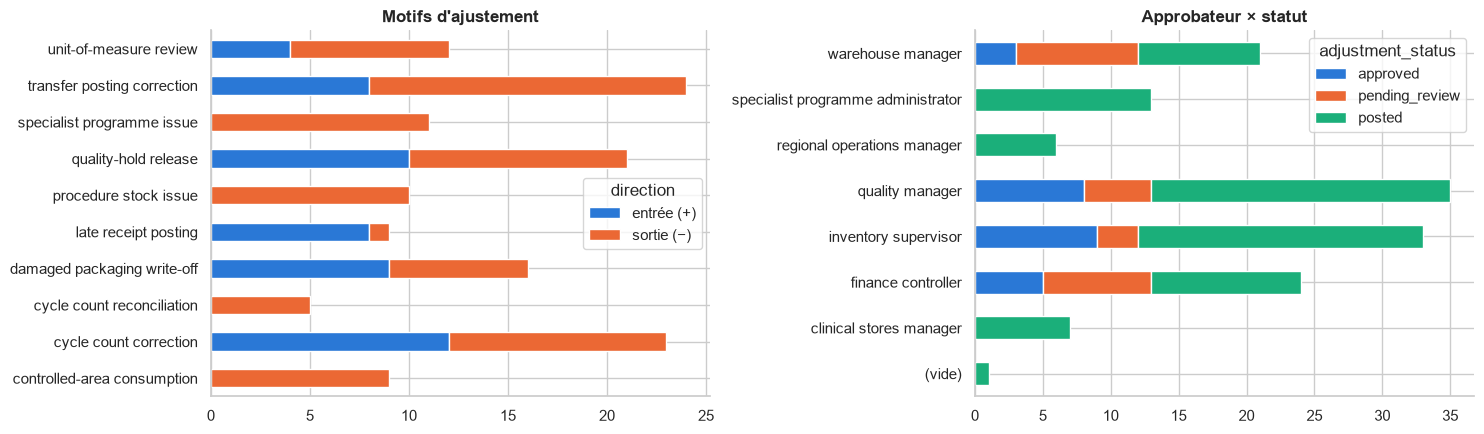

Ajustements sans pièce justificative : 85 / 140
Sorties : -284.4 | entrées : 200.6


approved_by_role,(vide),clinical stores manager,finance controller,inventory supervisor,quality manager,regional operations manager,specialist programme administrator,warehouse manager
adjustment_reason,,,,,,,,
controlled-area consumption,0,3,0,0,3,0,3,0
cycle count correction,1,0,5,5,6,0,0,6
cycle count reconciliation,0,0,0,1,1,3,0,0
damaged packaging write-off,0,0,3,4,5,0,0,4
late receipt posting,0,0,3,3,1,0,0,2
procedure stock issue,0,1,0,0,4,0,5,0
quality-hold release,0,0,6,8,4,0,0,3
specialist programme issue,0,3,0,0,3,0,5,0
transfer posting correction,0,0,5,6,7,3,0,3


count    sum
facility_code item_category                     
FCL-1010      medical_consumables      16 -33.55
FCL-1007      medical_consumables      14 -29.35
FCL-1024      biological_sample         8 -18.44
FCL-1019      biological_sample         8  -16.8
FCL-1005      biological_sample         2 -12.72
FCL-1020      biological_sample         5 -12.46
FCL-1023      medical_consumables       2  -10.2
              agricultural_product      2  -9.99

In [68]:
adj = adjustments.copy()
adj["direction"] = np.where(adj.adjustment_quantity < 0, "sortie (−)", "entrée (+)")
adj["justified"] = adj.related_receipt_number.notna() | adj.related_shipment_number.notna()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
pd.crosstab(adj.adjustment_reason, adj.direction).plot.barh(stacked=True, ax=axes[0], color=PALETTE[:2]); axes[0].set_title("Motifs d'ajustement")
pd.crosstab(adj.approved_by_role.fillna("(vide)"), adj.adjustment_status).plot.barh(stacked=True, ax=axes[1], color=PALETTE[:3]); axes[1].set_title("Approbateur × statut")
for a in axes: a.set_ylabel("")
plt.tight_layout(); plt.show()
print("Ajustements sans pièce justificative :", (~adj.justified).sum(), "/", len(adj))
print("Sorties :", round(adj.loc[adj.adjustment_quantity < 0, "adjustment_quantity"].sum(), 1),
      "| entrées :", round(adj.loc[adj.adjustment_quantity > 0, "adjustment_quantity"].sum(), 1))
display(pd.crosstab(adj.adjustment_reason, adj.approved_by_role.fillna("(vide)")))
display(adj.groupby(["facility_code", "item_category"]).adjustment_quantity.agg(["count", "sum"]).round(2).sort_values("sum").head(8))

In [69]:
# La pièce citée est-elle du même site et antérieure à l'ajustement ?
gr_ref = receipts.drop_duplicates("receipt_number").set_index("receipt_number")[["receipt_date", "receiving_facility_code"]]
sh_ref = shipments.drop_duplicates("shipment_number").set_index("shipment_number")[["dispatch_time", "origin_facility_code", "destination_facility_code"]]
a_r = adj.dropna(subset=["related_receipt_number"]).join(gr_ref, on="related_receipt_number")
a_s = adj.dropna(subset=["related_shipment_number"]).join(sh_ref, on="related_shipment_number")
a_r["autre_site"] = a_r.facility_code != a_r.receiving_facility_code
a_r["avant_la_piece"] = a_r.adjustment_date < a_r.receipt_date
a_s["autre_site"] = (a_s.facility_code != a_s.origin_facility_code) & (a_s.facility_code != a_s.destination_facility_code)
a_s["avant_la_piece"] = a_s.adjustment_date < a_s.dispatch_time
adj["piece_incoherente"] = (adj.index.isin(a_r[a_r.autre_site | a_r.avant_la_piece].index)
                            | adj.index.isin(a_s[a_s.autre_site | a_s.avant_la_piece].index))
display(pd.DataFrame({
    "ajustements liés": [len(a_r), len(a_s)],
    "pièce d'un autre site": [a_r.autre_site.sum(), a_s.autre_site.sum()],
    "ajustement antérieur à la pièce": [a_r.avant_la_piece.sum(), a_s.avant_la_piece.sum()],
}, index=["→ réception", "→ expédition"]))

# les disparitions de stock (A6) ont-elles un ajustement le même mois ?
adj["month"] = adj.adjustment_date.dt.to_period("M").dt.to_timestamp()
adj_m = adj.groupby(["facility_code", "item_category", "month"]).adjustment_quantity.sum().rename("adj_qty")
gap = month_end[month_end.shortfall].merge(adj_m, left_on=["facility_code", "item_category", "reporting_month"], right_index=True, how="left")
print(f"Mois avec disparition significative : {len(gap)} | dont couverts par un ajustement le même mois : {gap.adj_qty.notna().sum()}")

,ajustements liés,pièce d'un autre site,ajustement antérieur à la pièce
→ réception,23,21,11
→ expédition,37,18,14


Mois avec disparition significative : 25 | dont couverts par un ajustement le même mois : 8


L'analyse révèle que 21 ajustements liés aux réceptions et 18 liés aux expéditions concernent une pièce provenant d'un autre site. De plus, 11 ajustements de réception et 14 d'expédition sont enregistrés avant la pièce correspondante, ce qui constitue une incohérence chronologique. Enfin, sur les 25 mois présentant une disparition significative de stock, seulement 8 comportent un ajustement le même mois. Ces écarts suggèrent des incohérences dans la traçabilité des mouvements de stock qui nécessitent des investigations complémentaires.

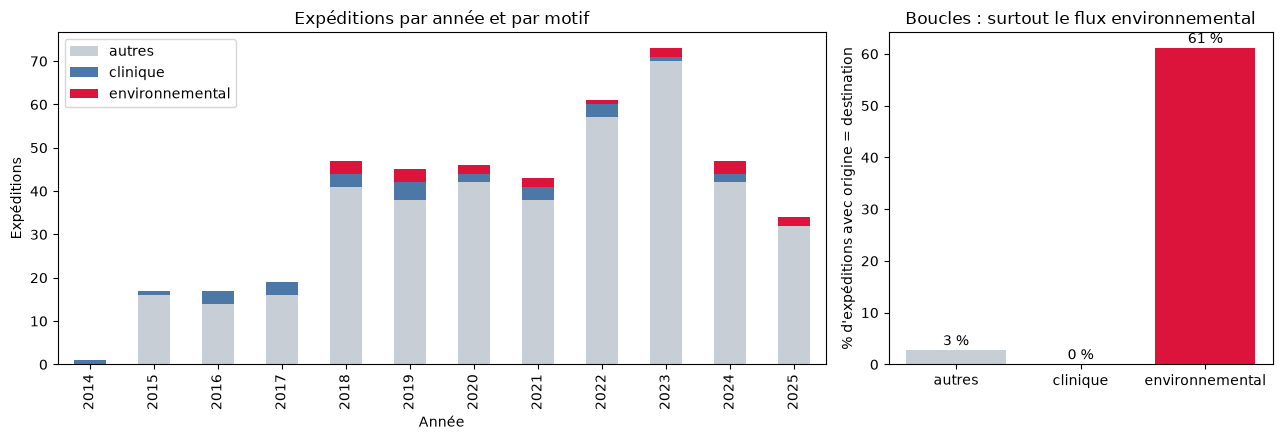

In [40]:
# 📊 Flux atypiques : volume par année (gauche) et part de « boucles » origine = destination (droite)
grp = np.where(shipments.declared_purpose == M_ENV, "environnemental", np.where(shipments.declared_purpose == M_CLIN, "clinique", "autres"))
cnt = pd.crosstab(shipments.annee, grp)[["autres", "clinique", "environnemental"]].rename_axis(columns=None)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
cnt.plot(kind="bar", stacked=True, ax=axes[0], color=["#c8ced6", "#4C78A8", "crimson"]); axes[0].set_xlabel("Année"); axes[0].set_ylabel("Expéditions"); axes[0].set_title("Expéditions par année et par motif")
share = shipments.assign(grp=grp).groupby("grp").boucle.mean().reindex(["autres", "clinique", "environnemental"]) * 100
axes[1].bar(share.index, share.values, color=["#c8ced6", "#4C78A8", "crimson"])
for i, v in enumerate(share.values): axes[1].text(i, v + 1, f"{v:.0f} %", ha="center")
axes[1].set_ylabel("% d'expéditions avec origine = destination"); axes[1].set_title("Boucles : surtout le flux environnemental")
plt.tight_layout(); plt.show()

61 % nous indique que pour le matériel environnemental, le processus d'expédition de  l'entreprise ne sert pas à livrer un client final. C'est un mouvement interne, administratif ou technique, qui brouille vos données de transport classiques.

  Deux flux se détachent :
environmental and wildlife reference materials : 18 envois, tous des échantillons biologiques 2-8 °C de `BP-30056` vers `BP-30078` (Meridian BioLogistics), toujours transportés par `BP-30047`, entre 2018 et 2025. 11 sur 18 sont des « boucles » (origine = destination), contre 11 sur 432 pour les autres envois (Fisher p ≈ 6·10⁻¹²) : un transport déclaré sans changement de site est atypique.
temperature-controlled clinical programme delivery : 26 envois de Meridian (`FCL-1011`) vers les sites Asterion (`FCL-1010` : 14, `FCL-1007` : 12), 2014-2024, même transporteur.
Les dossiers réglementaires (SB05) rattachés à une expédition sont au nombre de 15 : 11 concernent le premier flux, alors qu'il ne représente que 4 % des envois (p ≈ 5·10⁻¹³). Les régulateurs se sont donc intéressés à ce flux, ce qui corrobore le signal logistique de manière indépendante.

## 7. Réseau logistique : centralité et communautés (cours 4)
Graphe orienté des sites (arête = expéditions origine → destination, poids = nombre d'expéditions). Betweenness et closeness repèrent les sites « ponts » ;
Louvain regroupe les sites qui échangent davantage entre eux. (Les boucles sont comptées à part car elles n'apportent rien aux plus courts chemins.)

In [22]:
flux = shipments[~shipments.boucle].groupby(["origin_facility_code", "destination_facility_code"]).size().rename("w").reset_index()
G = nx.DiGraph(); G.add_weighted_edges_from(flux.itertuples(index=False, name=None), weight="w")
for u, v, d in G.edges(data=True): d["dist"] = 1 / d["w"]            # plus il y a de flux, plus la « distance » est courte
met = pd.DataFrame({"degre_sortant": dict(G.out_degree()), "degre_entrant": dict(G.in_degree()),
                    "force": dict(G.degree(weight="w")), "betweenness": nx.betweenness_centrality(G, weight="dist"),
                    "closeness": nx.closeness_centrality(G, distance="dist")})
met["nom"] = met.index.map(names); met["boucles"] = shipments[shipments.boucle].groupby("origin_facility_code").size().reindex(met.index).fillna(0).astype(int)
print(f"{G.number_of_nodes()} sites, {G.number_of_edges()} liens, densité = {nx.density(G):.3f}")
print(met.sort_values("betweenness", ascending=False).head(8).round(3).to_string())
comm = nx.community.louvain_communities(G.to_undirected(), weight="w", seed=0)
print("\nCommunautés Louvain (modularité = %.3f) :" % nx.community.modularity(G.to_undirected(), comm, weight="w"))
for i, c in enumerate(comm): print(f"  C{i} :", ", ".join(f"{x} ({names.get(x)})" for x in sorted(c)))

30 sites, 227 liens, densité = 0.261
          degre_sortant  degre_entrant  force  betweenness  closeness                                 nom  boucles
FCL-1011             15             19    146        0.380      1.372       Meridian Valenne Headquarters        2
FCL-1010             17             17     85        0.329      1.496    Asterion Central Clinical Campus        3
FCL-1019             11             12     73        0.236      1.353     Meridian Avelora Transfer Annex        7
FCL-1030             13             15     50        0.140      1.220  Kintara Cave Authority Field Depot        1
FCL-1020             17             10     43        0.117      1.099        Meridian Tembara Coastal Hub        4
FCL-1029             12             14     44        0.108      1.179        Vale Strategy Valenne Office        0
FCL-1007             10             11     75        0.072      1.365   Asterion Avelora Executive Clinic        0
FCL-1016             11             13     

L'analyse des réseaux met en évidence 30 établissements reliés par 227 liaisons logistiques, avec une densité de 26,1 %. L'établissement FCL-1011 (Meridian Valenne Headquarters) présente la plus forte centralité d'intermédiarité et la force la plus élevée, ce qui suggère un rôle important dans l'organisation des flux. FCL-1010 et FCL-1019 occupent également des positions centrales. Enfin, l'algorithme Louvain identifie quatre communautés d'établissements, avec une modularité de 0,175, indiquant une structuration relativement faible du réseau.

###   Visualisation – Réseau des sites

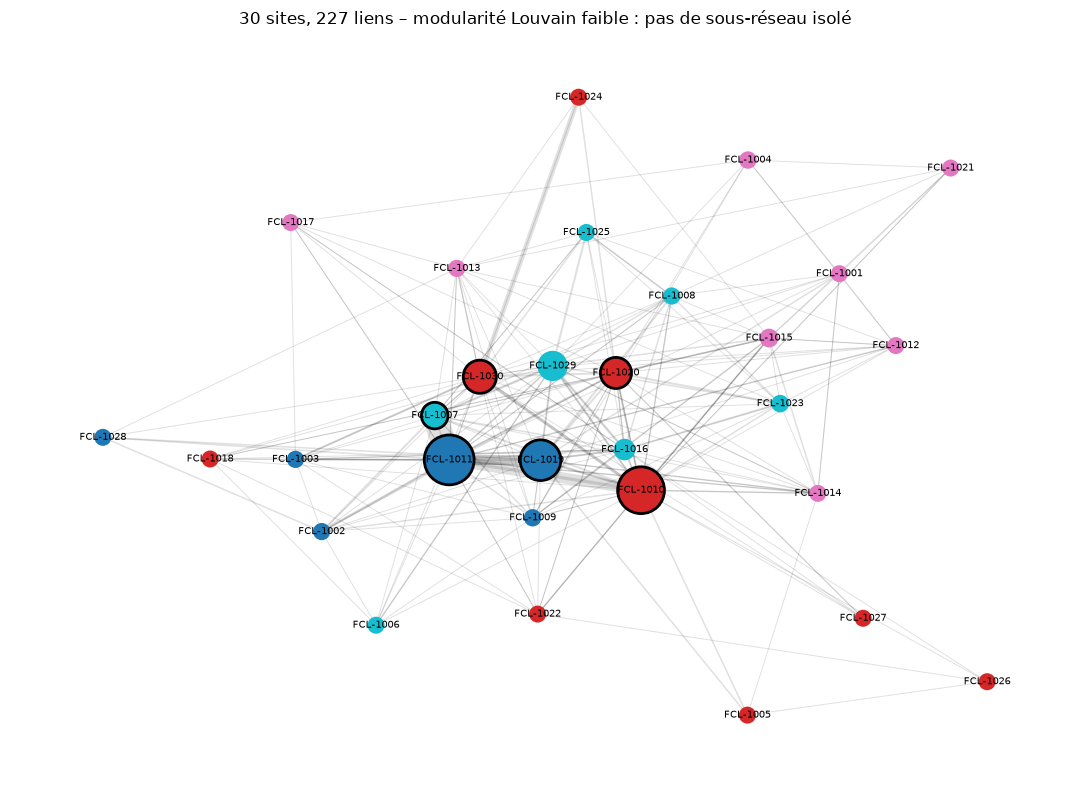

In [ ]:
#   Réseau des sites : taille = betweenness, couleur = communauté Louvain, contour noir = sites Meridian / Asterion
UG = G.to_undirected(); pos = nx.spring_layout(UG, weight="w", seed=3, k=0.9)
col = {n: i for i, c in enumerate(comm) for n in c}; cles = {"FCL-1011", "FCL-1019", "FCL-1020", "FCL-1030", "FCL-1010", "FCL-1007"}
fig, ax = plt.subplots(figsize=(11, 8))
nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.12, arrows=False, width=[0.3 + d["w"] * 0.4 for _, _, d in G.edges(data=True)])
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=[150 + 3000 * met.loc[n, "betweenness"] for n in G], node_color=[col[n] for n in G], cmap="tab10",
                       edgecolors=["black" if n in cles else "none" for n in G], linewidths=2)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=7)
ax.set_title(f"{G.number_of_nodes()} sites, {G.number_of_edges()} liens – modularité Louvain faible : pas de sous-réseau isolé"); ax.axis("off"); plt.tight_layout(); plt.show()

Ce graphe prouve visuellement que les sites problématiques (ceux cerclés de noir, avec des pertes de stocks ou des boucles) ne sont pas de petits entrepôts de périphérie oubliés. Au contraire, FCL-1011, FCL-1019 et FCL-1010 sont parmi les plus grosses bulles du graphe : ce sont les "hubs" centraux par lesquels transite toute   notre logistique. Les anomalies d'inventaire touchent donc le cœur même de   notre système de distribution ,  il n'y a pas de sous-réseau isolé. En revanche, les sites les plus « ponts » (betweenness) sont `FCL-1011` Meridian Valenne HQ (0,38), `FCL-1010` Asterion Central Clinical Campus (0,33) et `FCL-1019` Meridian Avelora Transfer Annex (0,24) : les trois sites concernés par les flux et les écarts ci-dessus.

## 8. Jointure et lien avec les registres publics (`officer_filings`) de public record – graphe dirigeants ↔ partenaires
Clé de jointure réelle : `officer_filings.registration_number` = `erp_business_partners.external_registration_number`. Pour une même personne,
`officer_local_ref` est identique d'un dossier à l'autre : on s'en sert pour distinguer un dirigeant commun d'un simple homonyme.

In [24]:
of = pd.read_csv(glob.glob("**/officer_filings.csv", recursive=True)[0])
of["full_name"] = of.full_name.str.strip().str.replace(r"\s+", " ", regex=True)
lien = of.merge(bp[["partner_code", "partner_name", "partner_role", "external_registration_number"]], left_on="registration_number", right_on="external_registration_number")
print(f"{lien.partner_code.nunique()} partenaires ERP retrouvés dans les registres publics ({len(lien)} mandats)")
B = nx.Graph(); B.add_edges_from((f"P:{r.officer_local_ref}", f"O:{r.partner_code}") for r in lien.itertuples())
persons = [n for n in B if n.startswith("P:")]
multi = [p for p in persons if B.degree(p) > 1]
print("Dirigeants présents dans plusieurs partenaires :", len(multi))
Gp = nx.Graph()
for p in multi:
    for a, b in itertools.combinations(sorted(x[2:] for x in B[p]), 2):
        Gp.add_edge(a, b, w=Gp[a][b]["w"] + 1 if Gp.has_edge(a, b) else 1)
poids = pd.DataFrame([(a, b, d["w"], names.get(a), names.get(b)) for a, b, d in Gp.edges(data=True)], columns=["A", "B", "dirigeants_communs", "nom_A", "nom_B"])
print(poids.sort_values("dirigeants_communs", ascending=False).head(8).to_string(index=False))
# Les partenaires liés par des dirigeants communs échangent-ils plus que le hasard ?
lies = {tuple(sorted(e)) for e in Gp.edges}
shipments["paire_exp_dest"] = [tuple(sorted(t)) for t in zip(shipments.sender_partner_code, shipments.receiver_partner_code)]
obs = int(shipments.paire_exp_dest.isin(lies).sum())
tous = list(itertools.combinations(sorted(lien.partner_code.unique()), 2)); rng = np.random.default_rng(1)
sim = [shipments.paire_exp_dest.isin({tous[i] for i in rng.choice(len(tous), len(lies), replace=False)}).sum() for _ in range(1000)]
print(f"\nExpéditions entre deux partenaires à dirigeant commun : {obs} (attendu au hasard ≈ {np.mean(sim):.1f}, p = {(np.sum(np.array(sim) >= obs) + 1) / 1001:.2f})")
comm_p = nx.community.louvain_communities(Gp, weight="w", seed=0)
print("Communautés de partenaires liés par des dirigeants :")
for c in comm_p: print("  ", [names.get(x) for x in sorted(c)])

24 partenaires ERP retrouvés dans les registres publics (136 mandats)
Dirigeants présents dans plusieurs partenaires : 27
       A        B  dirigeants_communs                              nom_A                              nom_B
BP-30039 BP-30078                   4 Valenne Industrial Futures Council              Meridian BioLogistics
BP-30004 BP-30017                   4        Common Ground Climate Forum       Meridian–Asterion Foundation
BP-30062 BP-30007                   4               Solvane Energy Group         Helix Legal and Compliance
BP-30042 BP-30043                   4          Nivren Maritime Logistics      Whitehaven Strategic Holdings
BP-30047 BP-30040                   4      Northstar Cold Chain Services        Threshold Earth Observatory
BP-30035 BP-30056                   4               Ardena Capital Union Horizon Field Research Cooperative
BP-30039 BP-30062                   1 Valenne Industrial Futures Council               Solvane Energy Group
BP-30042 BP-30

Le rapprochement des registres publics avec les données des partenaires ERP a permis d'identifier 24 partenaires et 136 mandats, ainsi que 27 dirigeants présents dans plusieurs organisations. Plusieurs partenaires partagent jusqu'à quatre dirigeants communs, notamment Meridian BioLogistics et Valenne Industrial Futures Council. Cependant, l'analyse des expéditions ne révèle pas de surreprésentation statistiquement significative des échanges entre partenaires partageant des dirigeants (p = 0,62). Ainsi, des liens organisationnels existent entre certaines structures, mais ils ne se traduisent pas nécessairement par des relations commerciales directes dans les données logistiques étudiées.

###   Visualisation – Partenaires liés par des dirigeants communs

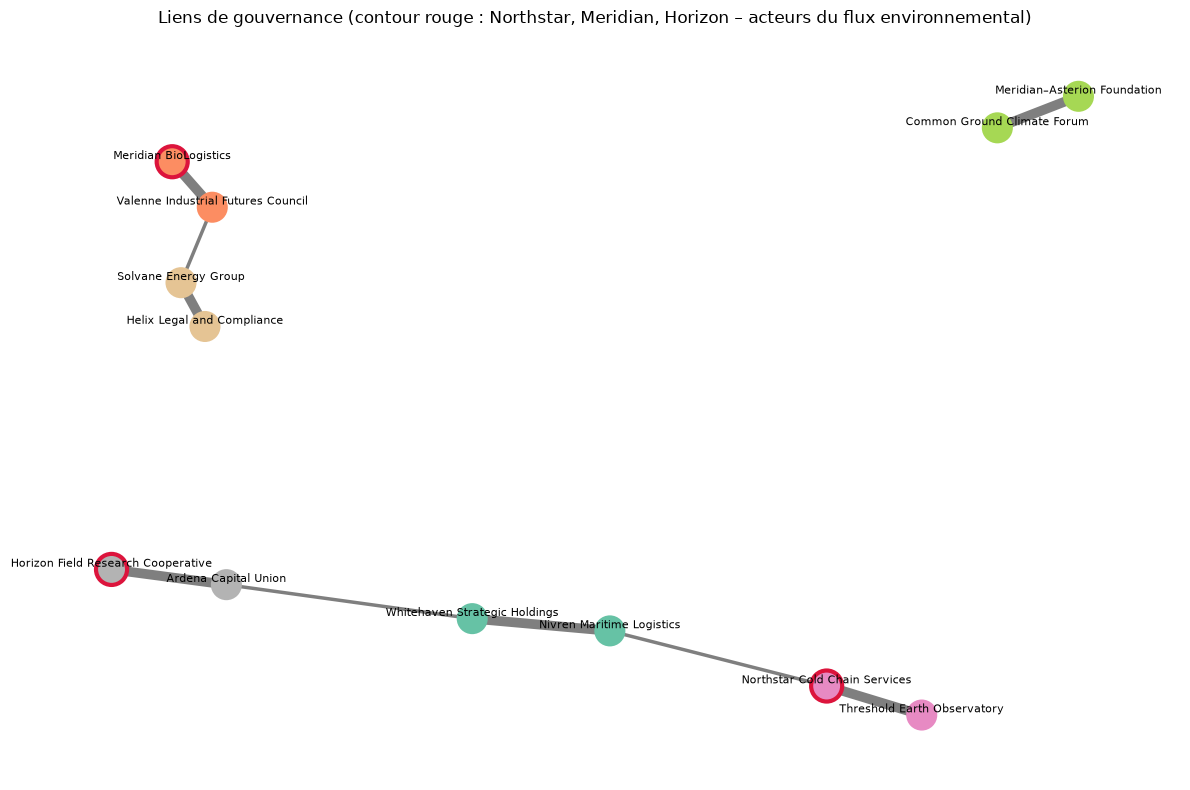

In [ ]:
#   Partenaires reliés par des dirigeants communs (épaisseur = nombre de dirigeants partagés)
pos = nx.spring_layout(Gp, weight="w", seed=37, k=2.0, iterations=300); cp = {n: i for i, c in enumerate(comm_p) for n in c}
fig, ax = plt.subplots(figsize=(12, 8))
nx.draw_networkx_edges(Gp, pos, ax=ax, alpha=0.5, width=[1 + 1.5 * d["w"] for _, _, d in Gp.edges(data=True)])
nx.draw_networkx_nodes(Gp, pos, ax=ax, node_size=500, node_color=[cp[n] for n in Gp], cmap="Set2",
                       edgecolors=["crimson" if n in {"BP-30047", "BP-30078", "BP-30056"} else "none" for n in Gp], linewidths=3)
nx.draw_networkx_labels(Gp, pos, labels={n: (names.get(n) or n)[:34] for n in Gp}, ax=ax, font_size=8, verticalalignment="bottom")
ax.set_title("Liens de gouvernance (contour rouge : Northstar, Meridian, Horizon – acteurs du flux environnemental)"); ax.axis("off"); plt.tight_layout(); plt.show()

les bulles (nœuds) : Ce sont les différentes entreprises partenaires du réseau (transporteurs, destinataires, etc.).

Les lignes grises (liens) : Si deux entreprises sont reliées, cela signifie qu'elles partagent des dirigeants communs (les mêmes personnes siègent à leurs conseils d'administration). Plus le trait est épais, plus ils ont de dirigeants en commun.

Les cercles rouges : Le code a spécifiquement entouré en rouge les trois acteurs (BP-30047, BP-30078, BP-30056) que nous avions identifiés dans la toute première étape (le tableau Apriori) comme étant impliqués dans les fameux "flux environnementaux" hautement atypiques. Il s'agit de Meridian Biologistics, Northstar Cold Chain Services et Horizon Field Research Cooperative.

  24 partenaires ERP sont retrouvés dans les registres publics ; 27 dirigeants siègent dans plusieurs partenaires. Six paires de partenaires partagent chacune 4 dirigeants, dont : Northstar Cold Chain Services ↔ Threshold Earth Observatory, Meridian BioLogistics ↔ Valenne Industrial Futures Council, Horizon Field Research Cooperative ↔ Ardena Capital Union (Horizon et Northstar sont l'expéditeur et le transporteur du flux environnemental).
Résultat négatif à assumer : ces partenaires liés par des dirigeants n'échangent pas davantage d'expéditions que le hasard (1 observée contre ≈ 3,9 attendue, p = 0,62). Les liens sont donc de gouvernance, pas commerciaux ; ils méritent un examen (conflits d'intérêts possibles), pas une conclusion.

## 9. Lien avec les données de santé (`clinical_observations`, `patient_administration`)
La correspondance entre les sites `FCL-…` (ERP) et les licences `FAC-…` (santé) est donnée par `licensed_facilities.csv` (même `facility_name`).
Test : les mois où des livraisons cliniques arrivent sur un site coïncident-ils avec davantage d'observations cardiaques « discordantes » ?
(corrélation de Spearman + test de permutation par décalage circulaire des séries mensuelles).

In [26]:
lic = pd.read_csv(glob.glob("**/licensed_facilities.csv", recursive=True)[0])
map_fac = facilities.merge(lic[["facility_license_number", "facility_name"]], on="facility_name")[["facility_code", "facility_name", "facility_license_number"]]
print(map_fac.to_string(index=False))
pa = pd.read_csv(glob.glob("**/patient_administration.csv", recursive=True)[0])
ob = pd.read_csv(glob.glob("**/clinical_observations.csv", recursive=True)[0])
ob["t"] = pd.to_datetime(ob.observation_time); ob["mois"] = ob.t.dt.to_period("M").dt.to_timestamp()
ob["interpretation_code"] = norm_text(ob.interpretation_code)
ob = ob.merge(pa[["patient_number", "primary_facility_license"]].drop_duplicates("patient_number"), on="patient_number", how="left")
discord = ob[ob.interpretation_code == "discordant"]
print(f"\n{len(discord)} observations discordantes ({discord.observation_name.unique().tolist()}), {discord.patient_number.nunique()} patients")
clin = shipments[shipments.declared_purpose == M_CLIN].copy(); clin["mois"] = clin.dispatch_time.dt.to_period("M").dt.to_timestamp()
idx = pd.date_range("2014-01-01", "2026-01-01", freq="MS"); rng = np.random.default_rng(0); res = []
for r in map_fac.itertuples():
    if (clin.destination_facility_code == r.facility_code).sum() == 0: continue
    s = clin[clin.destination_facility_code == r.facility_code].groupby("mois").size().reindex(idx, fill_value=0)
    y = discord[discord.primary_facility_license == r.facility_license_number].groupby("mois").observation_number.nunique().reindex(idx, fill_value=0)
    rho = stats.spearmanr(s, y)[0]
    perm = [stats.spearmanr(np.roll(s.values, k), y)[0] for k in rng.integers(6, len(s) - 6, 1000)]
    res.append({"site": f"{r.facility_code} ↔ {r.facility_license_number}", "livraisons_cliniques": int(s.sum()), "rho_spearman": round(rho, 3), "p_permutation": round((np.sum(np.abs(perm) >= abs(rho)) + 1) / 1001, 3)})
print(pd.DataFrame(res).to_string(index=False))

facility_code                      facility_name facility_license_number
     FCL-1010   Asterion Central Clinical Campus             FAC-VLN-101
     FCL-1007  Asterion Avelora Executive Clinic             FAC-AVL-201
     FCL-1015 Threshold Earth Avelora Laboratory             FAC-AVL-301

109 observations discordantes (['Apical cardiac rate']), 35 patients
                  site  livraisons_cliniques  rho_spearman  p_permutation
FCL-1010 ↔ FAC-VLN-101                    14         0.054          0.499
FCL-1007 ↔ FAC-AVL-201                    12         0.126          0.167


L'analyse a identifié 109 observations médicales discordantes concernant 35 patients, toutes associées à la mesure « Apical cardiac rate ». Le rapprochement avec les livraisons cliniques a permis d'étudier deux établissements, ayant respectivement reçu 14 et 12 livraisons. Les corrélations de Spearman obtenues sont très faibles (0,054 et 0,126), et les tests de permutation ne révèlent aucune association statistiquement significative (p = 0,499 et p = 0,167). Ainsi, aucune relation temporelle significative entre les livraisons cliniques et les observations médicales discordantes n'a été mise en évidence.

  `licensed_facilities.csv` donne la vraie correspondance : `FCL-1010` ↔ `FAC-VLN-101` (Asterion Central Clinical Campus), `FCL-1007` ↔ `FAC-AVL-201` (Asterion Avelora Executive Clinic) ; `FAC-AVL-301` est un autre site (Threshold Earth Avelora Laboratory, `FCL-1015`). Les 109 observations discordantes portent toutes sur la fréquence cardiaque apicale (35 patients).
Résultat : aucun lien  entre les livraisons cliniques et ces observations (Valenne ρ = 0,05, p = 0,50 ; Avelora ρ = 0,13, p = 0,17). Une version précédente de l'analyse regroupait par erreur deux licences d'Avelora et faisait apparaître un faux signal : il n'est pas à retenir.
Pour le rapport, c'est un résultat négatif utile : la logistique clinique ne se superpose pas à l'activité cardiaque étudiée par l'équipe santé.

## 10. Contrôles d'intégrité et qualité (réception, ajustements)

In [27]:
g = receipts.merge(po_lines, on=["purchase_order_number", "purchase_order_line"], how="left", suffixes=("", "_po"))
g["ratio_recu"] = g.received_quantity / g.ordered_quantity
print(f"Réceptions rattachées à une ligne de commande : {g.item_category.notna().sum()}/{len(g)} | fournisseur ≠ commande : {(g.supplier_partner_code != g.supplier_partner_code_po).sum()}")
print(f"Livraisons incomplètes (reçu < 90 % du commandé) : {(g.ratio_recu < 0.9).sum()} | jamais > commandé : {(g.ratio_recu <= 1).all()}")
print("Commandes sans réception :", int((~po_lines.purchase_order_number.isin(receipts.purchase_order_number)).sum()), po_lines[~po_lines.purchase_order_number.isin(receipts.purchase_order_number)].order_status.value_counts().to_dict())
# Les ajustements pointent-ils vers un reçu / une expédition cohérents ?
a_r = adjustments.dropna(subset=["related_receipt_number"]).merge(receipts[["receipt_number", "receiving_facility_code", "purchase_order_number", "purchase_order_line"]], left_on="related_receipt_number", right_on="receipt_number", how="left") \
        .merge(po_lines[["purchase_order_number", "purchase_order_line", "item_category"]], on=["purchase_order_number", "purchase_order_line"], how="left", suffixes=("", "_po"))
a_s = adjustments.dropna(subset=["related_shipment_number"]).merge(shipments[["shipment_number", "origin_facility_code", "destination_facility_code", "item_category"]], left_on="related_shipment_number", right_on="shipment_number", how="left", suffixes=("", "_sh"))
print(f"Ajustements liés à un reçu : {len(a_r)} → site différent : {(a_r.facility_code != a_r.receiving_facility_code).sum()}, catégorie différente : {(a_r.item_category != a_r.item_category_po).sum()}")
print(f"Ajustements liés à une expédition : {len(a_s)} → catégorie différente : {(a_s.item_category != a_s.item_category_sh).sum()}, site ni origine ni destination : {(~((a_s.facility_code == a_s.origin_facility_code) | (a_s.facility_code == a_s.destination_facility_code))).sum()}")
print("\nStatut des ajustements :", adjustments.adjustment_status.value_counts().to_dict())
print(adjustments.groupby("adjustment_status").adjustment_quantity.agg(["count", "sum"]).round(1))

Réceptions rattachées à une ligne de commande : 610/610 | fournisseur ≠ commande : 0
Livraisons incomplètes (reçu < 90 % du commandé) : 40 | jamais > commandé : True
Commandes sans réception : 40 {'delayed': 18, 'pending': 14, 'cancelled': 8}
Ajustements liés à un reçu : 23 → site différent : 21, catégorie différente : 22
Ajustements liés à une expédition : 37 → catégorie différente : 17, site ni origine ni destination : 18

Statut des ajustements : {'posted': 90, 'pending_review': 25, 'approved': 25}
                   count    sum
adjustment_status              
approved              25   51.4
pending_review        25    0.9
posted                90 -136.1


  Les réceptions sont cohérentes avec les commandes (fournisseur, site et unité identiques ; jamais plus que commandé ; 40 livraisons à moins de 90 %). Les 40 commandes sans réception sont toutes `delayed`/`pending`/`cancelled` : rien d'anormal. En revanche, les liens des ajustements d'inventaire sont peu fiables : 21 ajustements sur 23 rattachés à un reçu pointent vers un autre site et 22 sur 23 vers une autre catégorie ; 17 sur 37 rattachés à une expédition ont une catégorie différente. Ce sont des incohérences de traçabilité à signaler (justificatifs non vérifiables), sans qu'on puisse en conclure à une intention.

## 11. Lien avec l'écologie : accès aux sites de surveillance (`site_access_case_events`) ↔ expéditions
`Horizon Field Research Cooperative` (expéditeur du flux environnemental) est aussi le principal demandeur d'accès aux sites de surveillance.
Pour chaque début d'accès (`access_started`) on cherche la première expédition « environmental and wildlife reference materials » dans les 48 h suivantes
(`merge_asof`), puis on compare à un tirage de dates aléatoires pour savoir ce que donnerait le hasard.

In [28]:
sa = pd.read_csv(glob.glob("**/site_access_case_events.csv", recursive=True)[0])
sa["t"] = parse_dates(sa.event_time); sa["activity"] = norm_text(sa.activity)
sa["horizon"] = sa.requesting_organization_name == "Horizon Field Research Cooperative"
cases = sa.drop_duplicates("access_case_number")
print(f"{len(cases)} dossiers d'accès, dont {int(cases.horizon.sum())} demandés par Horizon ; refus : {int((sa.activity.eq('authorization_denied') & sa.horizon).sum())}/{int(sa.activity.eq('authorization_denied').sum())} ; "
      f"revues de sécurité : {int((sa.activity.eq('security_review') & sa.horizon).sum())}/{int(sa.activity.eq('security_review').sum())} par Horizon")
env = shipments[shipments.declared_purpose == M_ENV][["shipment_number", "dispatch_time", "origin_facility_code"]].sort_values("dispatch_time")
def apparier(debuts):
    d = debuts.assign(t=debuts.t.astype("datetime64[ns]")).sort_values("t")                 # même unité de temps des deux côtés
    e = env.assign(dispatch_time=env.dispatch_time.astype("datetime64[ns]"))
    return pd.merge_asof(d, e, left_on="t", right_on="dispatch_time", direction="forward", tolerance=pd.Timedelta("48h"))
debuts = sa[sa.horizon & (sa.activity == "access_started")][["access_case_number", "site_code", "t"]]
app = apparier(debuts); app["delai_h"] = (app.dispatch_time - app.t).dt.total_seconds() / 3600
print(f"\nDébuts d'accès Horizon suivis d'une expédition environnementale sous 48 h : {app.shipment_number.notna().sum()}/{len(app)} (délai médian {app.delai_h.median():.0f} h)")
print(pd.crosstab(app.site_code.str[:3].rename("région du site"), app.origin_facility_code.rename("site d'origine de l'expédition")))
autres = sa[~sa.horizon & (sa.activity == "access_started")][["access_case_number", "site_code", "t"]]
print(f"Autres demandeurs : {apparier(autres).shipment_number.notna().sum()}/{len(autres)}")
rng = np.random.default_rng(0); lo, hi = sa.t.min().value, sa.t.max().value
sim = [apparier(pd.DataFrame({"access_case_number": range(len(debuts)), "site_code": "", "t": pd.to_datetime(rng.integers(lo, hi, len(debuts)))})).shipment_number.notna().sum() for _ in range(500)]
print(f"Au hasard (500 tirages) : {np.mean(sim):.2f} correspondances en moyenne, maximum {max(sim)}")
print("\nObjet déclaré de ces accès :", cases[cases.horizon].access_purpose.value_counts().to_dict())
print(app.sort_values("t").assign(t=lambda d: d.t.dt.strftime("%Y-%m-%d %H:%M"), dispatch_time=lambda d: d.dispatch_time.dt.strftime("%Y-%m-%d %H:%M"))
      [["access_case_number", "site_code", "t", "shipment_number", "dispatch_time", "origin_facility_code"]].head(6).to_string(index=False))

60 dossiers d'accès, dont 18 demandés par Horizon ; refus : 3/9 ; revues de sécurité : 12/12 par Horizon

Débuts d'accès Horizon suivis d'une expédition environnementale sous 48 h : 18/18 (délai médian 15 h)
site d'origine de l'expédition  FCL-1019  FCL-1020  FCL-1030
région du site                                              
AVL                                    7         0         0
KNT                                    0         0         7
TMB                                    0         4         0
Autres demandeurs : 0/36
Au hasard (500 tirages) : 0.15 correspondances en moyenne, maximum 2

Objet déclaré de ces accès : {'acoustic monitoring and equipment maintenance': 9, 'habitat survey and sample documentation': 5, 'night wildlife monitoring programme': 4}
access_case_number site_code                t shipment_number    dispatch_time origin_facility_code
     ACC-2018-0001   TMB-NAC 2018-02-15 18:00  SHP-2018-00004 2018-02-16 09:00             FCL-1020
     ACC-2018-0002   K

les 18 demandes d'accès de Horizon sont toutes suivies d'une expédition environnementale dans les 48 heures, avec un délai médian de 15 heures, contre 0 sur 36 pour les autres organisations. Les 12 revues de sécurité concernent Horizon et 3 des 9 refus d'accès lui sont associés

###   Visualisation – Accès Horizon et expéditions

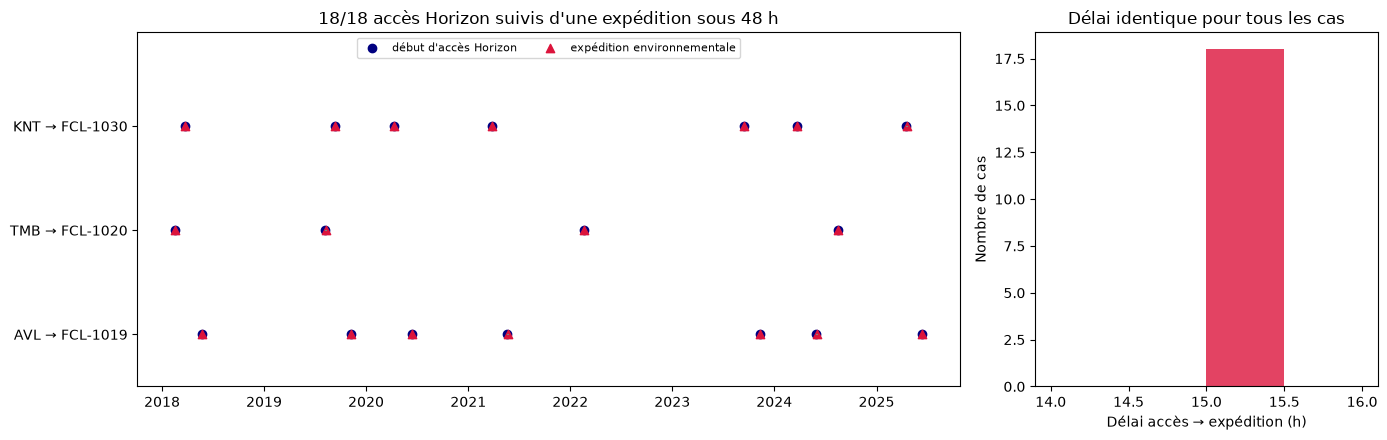

In [ ]:
#   Chaque début d'accès Horizon (rond) est suivi d'une expédition environnementale (triangle) ; délai en heures (droite)
reg_y = {"AVL": 0, "TMB": 1, "KNT": 2}; app["y"] = app.site_code.str[:3].map(reg_y)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.4, 1]})
ax = axes[0]
for r in app.itertuples(): ax.plot([r.t, r.dispatch_time], [r.y, r.y], color="grey", lw=0.8)
ax.scatter(app.t, app.y, marker="o", color="navy", label="début d'accès Horizon")
ax.scatter(app.dispatch_time, app.y, marker="^", color="crimson", label="expédition environnementale")
ax.set_yticks(list(reg_y.values())); ax.set_yticklabels([f"{k} → {v}" for k, v in {"AVL": "FCL-1019", "TMB": "FCL-1020", "KNT": "FCL-1030"}.items()])
ax.set_ylim(-0.5, 2.9); ax.set_title(f"{app.shipment_number.notna().sum()}/{len(app)} accès Horizon suivis d'une expédition sous 48 h"); ax.legend(loc="upper center", ncol=2, fontsize=8)
axes[1].hist(app.delai_h.dropna(), bins=np.arange(app.delai_h.min() - 1, app.delai_h.max() + 1.5, 0.5), color="crimson", alpha=0.8); axes[1].set_xlabel("Délai accès → expédition (h)"); axes[1].set_ylabel("Nombre de cas"); axes[1].set_title("Délai identique pour tous les cas")
plt.tight_layout(); plt.show()

Le graphique de gauche (La corrélation parfaite) :
Les points bleus représentent le moment où Horizon accède à un site (FCL-1019, 1020 ou 1030). Les triangles rouges représentent le départ d'une expédition "environnementale" (les fameuses expéditions en boucle). Le graphique montre une superposition totale : 100 % des accès d'Horizon (18 sur 18) sont suivis d'une expédition fantôme.



Le graphique de droite (La preuve de l'automatisation) :
Ce petit histogramme calcule le temps exact qui s'écoule entre l'accès d'Horizon et le déclenchement de l'expédition. Le résultat est une barre unique : le délai est de 15 heures pile dans tous les cas.

  C'est le lien le plus net entre logistique et écologie. Horizon Field Research Cooperative a déposé 18 des 60 dossiers d'accès aux sites de surveillance et concentre les 12 revues de sécurité. Chacun de ses 18 débuts d'accès (à 18 h) est suivi, 15 h plus tard en médiane, d'une expédition « environmental and wildlife reference materials » au départ du hub Meridian de la même région (sites Avelora → `FCL-1019`, Tembara → `FCL-1020`, Kintara → `FCL-1030`). Les 36 accès des autres demandeurs ne sont suivis d'aucune expédition de ce type, et des dates tirées au hasard n'en donnent que 0,15 en moyenne (maximum 2 sur 500 tirages).
Par ailleurs, seuls 5 de ces accès ont un objet déclaré qui mentionne des échantillons (« habitat survey and sample documentation »), alors que les 18 sont suivis d'un envoi de 2 à 8 unités biologiques.

Commandes sans réception : 40 → statuts : {'delayed': 18, 'pending': 14, 'cancelled': 8}


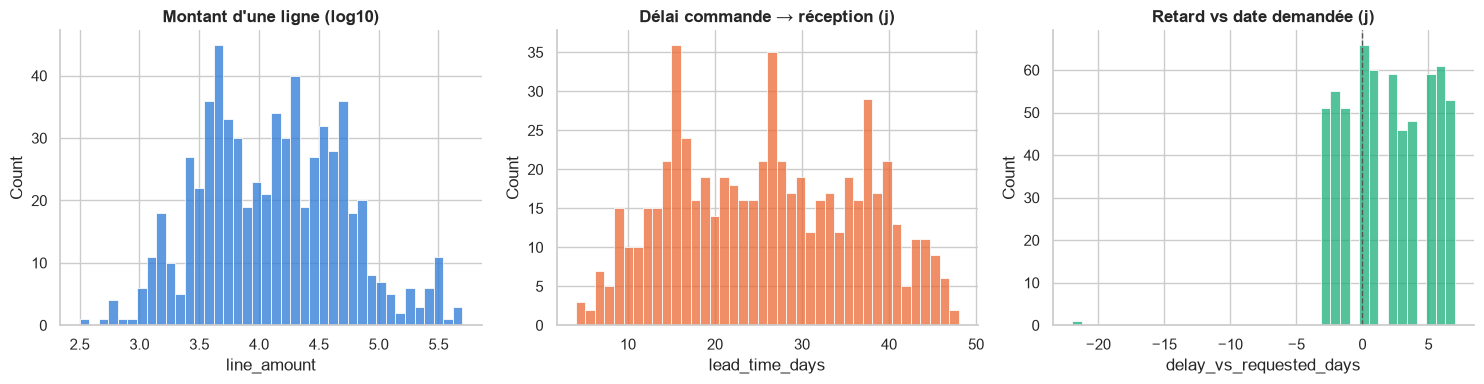

,ordered_quantity,unit_price,line_amount,lead_time_days,delay_vs_requested_days,qty_gap_pct
count,650.0,650.0,650.0,610.00,610.00,610.0
mean,20.96,3844.17,33904.22,25.95,1.97,-1.36
std,23.14,5701.54,62950.92,10.55,3.29,4.34
min,1.0,83.81,315.86,4.00,-22.00,-22.0
25%,1.0,560.44,4483.72,17.00,-1.00,0.0
50%,14.0,1600.67,13067.16,26.00,2.00,0.0
75%,30.0,4243.12,37007.3,35.00,5.00,0.0
max,90.0,28663.74,501871.96,48.00,7.00,0.0


In [59]:
po_gr = po_lines.merge(receipts, on=["purchase_order_number", "purchase_order_line"], how="left",
                       suffixes=("_po", "_gr"))
po_gr["lead_time_days"] = (po_gr.receipt_date - po_gr.order_date).dt.days
po_gr["delay_vs_requested_days"] = (po_gr.receipt_date - po_gr.requested_delivery_date).dt.days
po_gr["qty_gap"] = po_gr.received_quantity - po_gr.ordered_quantity
po_gr["qty_gap_pct"] = 100 * po_gr.qty_gap / po_gr.ordered_quantity
po_gr["unit_mismatch"] = po_gr.received_unit.notna() & (po_gr.received_unit != po_gr.ordered_unit)
po_gr["supplier_mismatch"] = po_gr.supplier_partner_code_gr.notna() & (po_gr.supplier_partner_code_po != po_gr.supplier_partner_code_gr)
po_gr["facility_mismatch"] = po_gr.receiving_facility_code.notna() & (po_gr.ordering_facility_code != po_gr.receiving_facility_code)
po_gr["line_amount"] = po_gr.ordered_quantity * po_gr.unit_price
po_gr["year"] = po_gr.order_date.dt.year
print("Commandes sans réception :", po_gr.receipt_number.isna().sum(),
      "→ statuts :", po_gr[po_gr.receipt_number.isna()].order_status.value_counts().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(np.log10(po_gr.line_amount), bins=40, ax=axes[0], color=PALETTE[0]); axes[0].set_title("Montant d'une ligne (log10)")
sns.histplot(po_gr.lead_time_days.dropna(), bins=40, ax=axes[1], color=PALETTE[1]); axes[1].set_title("Délai commande → réception (j)")
sns.histplot(po_gr.delay_vs_requested_days.dropna(), bins=40, ax=axes[2], color=PALETTE[2])
axes[2].axvline(0, color="#555", ls="--", lw=1); axes[2].set_title("Retard vs date demandée (j)")
plt.tight_layout(); plt.show()
display(po_gr[["ordered_quantity", "unit_price", "line_amount", "lead_time_days", "delay_vs_requested_days", "qty_gap_pct"]].describe().round(2))

In [60]:
# Prix : dispersion par article, puis contrôle de l'effet « devise »
price_disp = (po_gr.groupby(["item_code", "item_description"]).unit_price
                .agg(n="size", median="median", min="min", max="max")
                .assign(ratio_max_median=lambda d: (d["max"] / d["median"]).round(1))
                .sort_values("ratio_max_median", ascending=False))
display(price_disp.head(8))

po_gr["price_ratio_item"] = po_gr.unit_price / po_gr.groupby("item_code").unit_price.transform("median")
po_gr["price_ratio_item_cur"] = po_gr.unit_price / po_gr.groupby(["item_code", "currency"]).unit_price.transform("median")
print("Écart-type de log(prix/médiane) — par article :", np.log(po_gr.price_ratio_item).std().round(3),
      "| par article×devise :", np.log(po_gr.price_ratio_item_cur).std().round(3))
print("Lignes > 3× la médiane (article, devise) :", (po_gr.price_ratio_item_cur > 3).sum(),
      "| < 1/3 :", (po_gr.price_ratio_item_cur < 1/3).sum())

,,n,median,min,max,ratio_max_median
item_code,item_description,,,,,
ITM-AGR-001,Durian produce pallet,23,1824.43,1646.7,2118.23,1.2
ITM-CON-001,Operational consulting service,25,5375.58,4967.44,6409.83,1.2
ITM-CSE-001,Portable cold-storage module,27,12531.43,11398.01,14698.78,1.2
ITM-LAB-002,Sample preparation material pack,19,495.84,450.26,571.98,1.2
ITM-LAB-001,Laboratory assay material pack,25,725.96,654.05,842.95,1.2
ITM-AGR-002,Mixed orchard produce pallet,30,1351.485,1170.6,1525.44,1.1
ITM-AGE-001,Orchard maintenance equipment,23,5481.67,4797.82,6172.73,1.1
ITM-COM-001,Secure communication service,17,1554.15,1292.19,1673.0,1.1


Écart-type de log(prix/médiane) — par article : 0.08 | par article×devise : 0.073
Lignes > 3× la médiane (article, devise) : 0 | < 1/3 : 0


L'analyse révèle un délai moyen de 26 jours entre la commande et la réception, avec un retard moyen de 2 jours par rapport à la date demandée. Les quantités reçues sont globalement proches des quantités commandées (écart moyen de -1,36 %). Les prix varient peu pour un même article, même en tenant compte des devises, et aucun écart extrême supérieur à 3 fois ou inférieur à un tiers de la médiane n'est détecté. Ces résultats ne révèlent donc pas d'anomalie tarifaire majeure, mais permettent de cibler les retards et les écarts de livraison.

Taille : 433 | taux de problèmes : 0.111


,modèle,ROC-AUC,précision (problème),rappel (problème)
0,Régression logistique,0.535,0.118,0.312
1,Arbre de décision (prof. 4),0.567,0.130,0.708
2,Random Forest,0.565,0.100,0.146


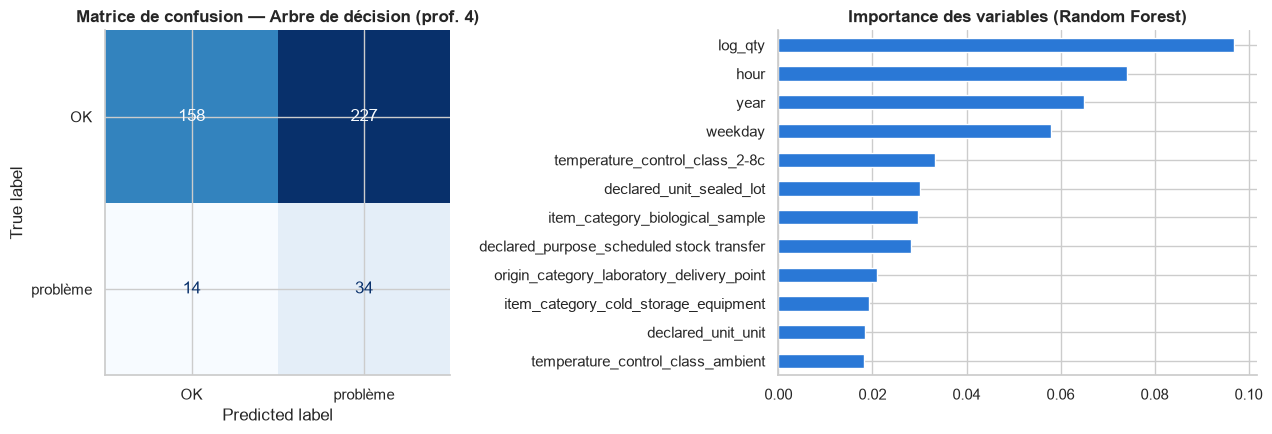

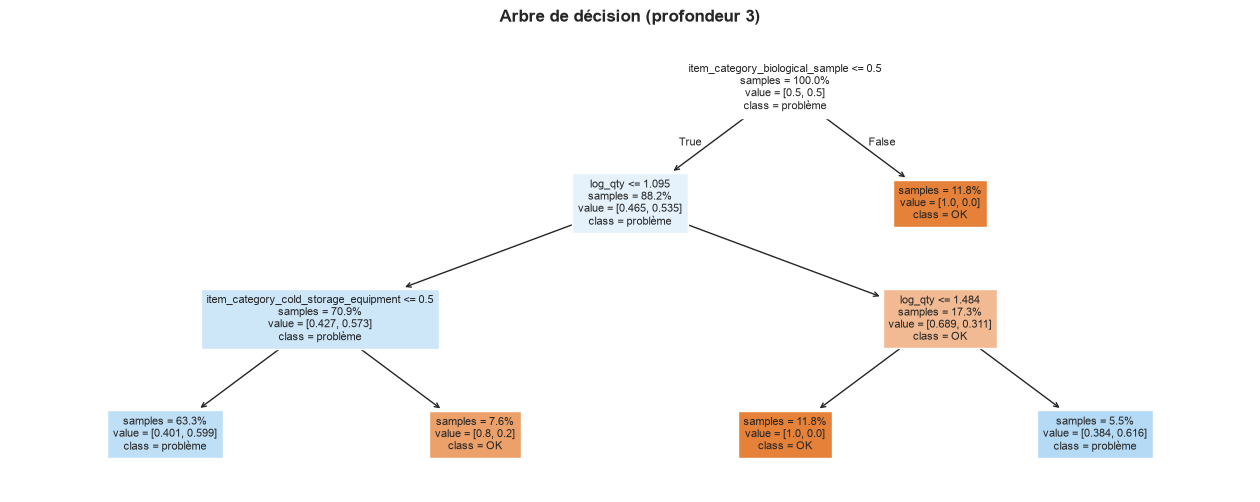

In [74]:
d = X_sh[X_sh.shipment_status != "in_transit"].copy()
y = d.shipment_status.isin(["delayed", "returned"]).astype(int)
print("Taille :", len(d), "| taux de problèmes :", y.mean().round(3))

num_c = ["log_qty", "hour", "weekday", "year"]
cat_c = cat_sh + ["same_region", "carrier_partner_code"]
prep = ColumnTransformer([("num", StandardScaler(), num_c),
                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_c)])
models = {
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5),
    "Arbre de décision (prof. 4)": DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
res, probas = [], {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    p = cross_val_predict(pipe, d[num_c + cat_c], y, cv=cv, method="predict_proba")[:, 1]
    probas[name] = p
    pred = (p >= 0.5).astype(int); tp = ((pred == 1) & (y == 1)).sum()
    res.append((name, roc_auc_score(y, p), tp / max(pred.sum(), 1), tp / y.sum()))
display(pd.DataFrame(res, columns=["modèle", "ROC-AUC", "précision (problème)", "rappel (problème)"]).round(3))

best = max(probas, key=lambda k: roc_auc_score(y, probas[k]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y, probas[best] >= 0.5), display_labels=["OK", "problème"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Matrice de confusion — {best}")
rf = Pipeline([("prep", prep), ("model", models["Random Forest"])]).fit(d[num_c + cat_c], y)
names_ = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names_).sort_values().tail(12)
imp.index = imp.index.str.replace("num__|cat__", "", regex=True)
imp.plot.barh(ax=axes[1], color=PALETTE[0]); axes[1].set_title("Importance des variables (Random Forest)")
plt.tight_layout(); plt.show()

tree = Pipeline([("prep", prep), ("model", DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=RANDOM_STATE))]).fit(d[num_c + cat_c], y)
plt.figure(figsize=(16, 6))
plot_tree(tree.named_steps["model"], feature_names=[n.replace("num__", "").replace("cat__", "") for n in names_],
          class_names=["OK", "problème"], filled=True, impurity=False, proportion=True, fontsize=8)
plt.title("Arbre de décision (profondeur 3)"); plt.show()

## 12. Lien avec les mémos internes (`institutional_memos`)
Les mémos citent des numéros d'expéditions, de commandes et d'ajustements : on vérifie qu'ils existent dans l'ERP et que le contenu correspond.
La plupart des mémos ont un objet numéroté (« … Memorandum 57 ») ; trois ont un objet unique, et ce sont les seuls à parler de stock biologique ou de « CHAMELEO ».

In [30]:
mm = pd.read_csv(glob.glob("**/institutional_memos.csv", recursive=True)[0])
print("Références → ERP : expéditions", int(mm.related_shipment_number.dropna().isin(shipments.shipment_number).sum()), "/", int(mm.related_shipment_number.notna().sum()),
      "| commandes", int(mm.related_purchase_order.dropna().isin(po_lines.purchase_order_number).sum()), "/", int(mm.related_purchase_order.notna().sum()))
mm["unique"] = ~mm.subject_line.str.strip().str.contains(r"\d+$")
cles = mm[mm["unique"]].sort_values("document_date")
print(cles[["document_id", "document_date", "author_name", "author_organization", "subject_line", "related_shipment_number", "visibility_level"]].to_string(index=False))
print("\nExpéditions citées par ces mémos :")
print(shipments[shipments.shipment_number.isin(cles.related_shipment_number.dropna())][["shipment_number", "origin_facility_code", "destination_facility_code", "item_category", "declared_purpose", "authorization_class"]].to_string(index=False))
# Ajustement cité dans le mémo sur le déséquilibre biologique
adj_cites = mm.text.str.extractall(r"(ADJ-\d{4}-\d{5})")[0].unique()
print("\nAjustements cités dans les mémos :")
print(adjustments[adjustments.adjustment_number.isin(adj_cites)][["adjustment_number", "facility_code", "item_category", "adjustment_reason", "adjustment_quantity"]].to_string(index=False))
# Le mémo affirme que l'écart est concentré sur les unités biologiques « sous autorisation restreinte » : vérification sur les mois avec expédition
auth = shipments[shipments.declared_purpose == M_ENV].groupby(["origin_facility_code", "mois"]).authorization_class.agg(lambda s: "restricted" if "restricted" in set(s) else "autre").rename("auth").reset_index()
t = bio.merge(auth, left_on=["facility_code", "reporting_month"], right_on=["origin_facility_code", "mois"], how="inner")
print("\nÉcart de stock biologique les mois d'expédition environnementale, selon la classe d'autorisation :")
print(t.groupby("auth").ecart.agg(["count", "mean", "median"]).round(2))
print("Mann-Whitney restricted vs autre : p =", round(stats.mannwhitneyu(t[t.auth == "restricted"].ecart, t[t.auth == "autre"].ecart).pvalue, 3), "(petits effectifs)")

Références → ERP : expéditions 8 / 8 | commandes 5 / 5
document_id document_date author_name   author_organization                                subject_line related_shipment_number visibility_level
 MEM-510100    2023-08-17  Soren Kade Meridian BioLogistics Secure Delivery Record-Handling Instruction          SHP-2022-00011       restricted
 MEM-510062    2024-04-30  Soren Kade Meridian BioLogistics        April Biological-Unit Reconciliation                     NaN       restricted
 MEM-510101    2025-03-14  Soren Kade Meridian BioLogistics       Restricted CHAMELEO Governance Review          SHP-2023-00035       restricted

Expéditions citées par ces mémos :
shipment_number origin_facility_code destination_facility_code        item_category          declared_purpose authorization_class
 SHP-2022-00011             FCL-1011                  FCL-1007 protective_equipment agricultural distribution            ordinary
 SHP-2023-00035             FCL-1004                  FCL-1021       

**comme le cour 6 du prof que on a fait en ligne** 

Nombre de mémos : 30

Dimensions Bag of Words : (30, 353)

20 mots les plus fréquents :


,mot,frequence
166,inventory,30
215,ordinary,30
252,records,30
307,shipment,29
241,purpose,29
198,named,29
332,transfer,28
282,reviewed,28
230,posting,28
36,batches,28


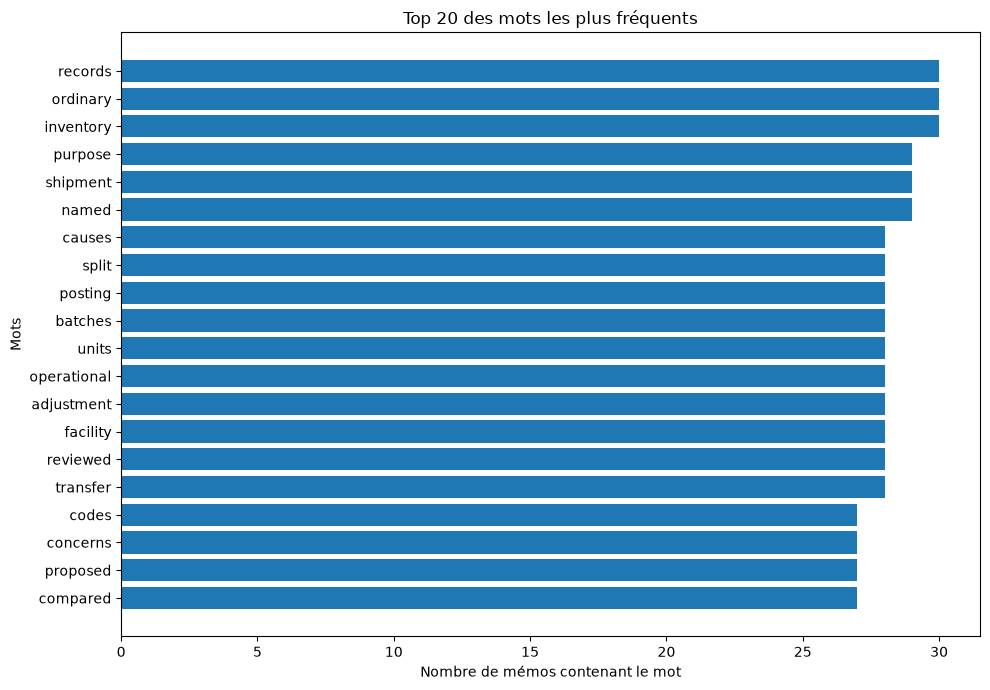


20 expressions les plus fréquentes (Bigrams) :


,expression,frequence
268,facility codes,36
614,shipment inventory,32
628,split batches,32
395,ordinary causes,32
665,undisclosed purpose,31
642,substitution documentation,31
645,supplier substitution,31
659,timing supplier,31
661,transfer timing,31
87,causes include,31



15 expressions les plus fréquentes (Trigrams) :


,expression,frequence
732,undisclosed purpose ordinary,31
729,transfer timing supplier,31
678,shipment inventory records,31
692,split batches transfer,31
708,substitution documentation lag,31
713,supplier substitution documentation,31
727,timing supplier substitution,31
65,authorizations facility codes,31
498,quantities units authorizations,31
495,purpose ordinary causes,31



Dimensions TF-IDF : (30, 1054)

Mots-clés les plus importants par mémo :


,document_id,subject_line,mot_cle,score_tfidf
0,MEM-510062,April Biological-Unit Reconciliation,biological,0.2284
1,MEM-510062,April Biological-Unit Reconciliation,unit,0.1394
2,MEM-510062,April Biological-Unit Reconciliation,biological unit,0.1281
3,MEM-510062,April Biological-Unit Reconciliation,april,0.1281
4,MEM-510062,April Biological-Unit Reconciliation,declared internal,0.1281
...,...,...,...,...
145,MEM-510091,Operations Meeting Record 82,meeting,0.2239
146,MEM-510091,Operations Meeting Record 82,shipment exception,0.1895
147,MEM-510091,Operations Meeting Record 82,exception,0.1895
148,MEM-510091,Operations Meeting Record 82,exception reviewed,0.1596


... (8 outputs left out)


CLUSTER 2 :


,document_id,subject_line
8,MEM-510074,Procurement Justification 61
9,MEM-510018,Procurement Justification 62
10,MEM-510021,Procurement Justification 63
11,MEM-510061,Procurement Justification 64
12,MEM-510050,Procurement Justification 65



TABLEAU FINAL DES MÉMOS :


,document_id,subject_line,text_clean,topic_lda,topic_probability,cluster
0,MEM-510062,April Biological-Unit Reconciliation,april biological unit reconciliation subject unresolved biological unit imbalance following apri...,0,0.994239,1
1,MEM-510100,Secure Delivery Record-Handling Instruction,secure delivery record handling instruction scope this instruction applies to staff handling sec...,1,0.993687,0
2,MEM-510101,Restricted CHAMELEO Governance Review,restricted chameleo governance review meeting record restricted governance review attendees incl...,2,0.995094,0
3,MEM-510128,Internal Operations Memorandum 56,internal operations memorandum subject operational review of cold chain reconciliation context r...,1,0.706658,1
4,MEM-510069,Internal Operations Memorandum 57,internal operations memorandum subject operational review of supplier onboarding context records...,1,0.991145,1
5,MEM-510030,Internal Operations Memorandum 58,internal operations memorandum subject operational review of shipment exception context records ...,1,0.991321,1
6,MEM-510080,Internal Operations Memorandum 59,internal operations memorandum subject operational review of inventory close context records wer...,1,0.991312,1
7,MEM-510059,Internal Operations Memorandum 60,internal operations memorandum subject operational review of secure records handling context rec...,1,0.991536,1
8,MEM-510074,Procurement Justification 61,procurement justification request procurement request for standard programme supplies justificat...,0,0.990396,2
9,MEM-510018,Procurement Justification 62,procurement justification request procurement request for standard programme supplies justificat...,0,0.990331,2


In [41]:
import pandas as pd
import numpy as np
import re
import glob
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD, LatentDirichletAllocation
from sklearn.cluster import KMeans


mm = pd.read_csv(
    glob.glob("**/institutional_memos.csv", recursive=True)[0]
)

if "document_id" not in mm.columns:
    mm["document_id"] = mm.index.astype(str)

mm["document_text"] = (
    mm["subject_line"].fillna("").astype(str)
    + " "
    + mm["text"].fillna("").astype(str)
)


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b(?:ADJ|SHP|PO)-[A-Z0-9-]+\b", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"[^a-zA-ZÀ-ÿ\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


mm["text_clean"] = mm["document_text"].apply(clean_text)
mm = mm[mm["text_clean"].str.len() > 0].copy()
mm = mm.reset_index(drop=True)

stopwords = list(
    set(ENGLISH_STOP_WORDS).union({
        "memo", "memorandum", "dear", "regards",
        "please", "attached", "attachment", "document"
    })
)

print("Nombre de mémos :", len(mm))


bow = CountVectorizer(
    stop_words=stopwords,
    binary=True,
    ngram_range=(1, 1)
)

X_bow = bow.fit_transform(mm["text_clean"])

vocabulary = bow.get_feature_names_out()
frequences = np.asarray(X_bow.sum(axis=0)).flatten()

freq_df = pd.DataFrame({
    "mot": vocabulary,
    "frequence": frequences
}).sort_values("frequence", ascending=False)

print("\nDimensions Bag of Words :", X_bow.shape)
print("\n20 mots les plus fréquents :")
display(freq_df.head(20))


top_words = freq_df.head(20).sort_values("frequence")

plt.figure(figsize=(10, 7))
plt.barh(top_words["mot"], top_words["frequence"])
plt.xlabel("Nombre de mémos contenant le mot")
plt.ylabel("Mots")
plt.title("Top 20 des mots les plus fréquents")
plt.tight_layout()
plt.show()


bigram_vectorizer = CountVectorizer(
    stop_words=stopwords,
    ngram_range=(2, 2)
)

X_bigram = bigram_vectorizer.fit_transform(mm["text_clean"])

bigram_freq = np.asarray(X_bigram.sum(axis=0)).flatten()

bigram_df = pd.DataFrame({
    "expression": bigram_vectorizer.get_feature_names_out(),
    "frequence": bigram_freq
}).sort_values("frequence", ascending=False)

print("\n20 expressions les plus fréquentes (Bigrams) :")
display(bigram_df.head(20))


trigram_vectorizer = CountVectorizer(
    stop_words=stopwords,
    ngram_range=(3, 3)
)

X_trigram = trigram_vectorizer.fit_transform(mm["text_clean"])

trigram_freq = np.asarray(X_trigram.sum(axis=0)).flatten()

trigram_df = pd.DataFrame({
    "expression": trigram_vectorizer.get_feature_names_out(),
    "frequence": trigram_freq
}).sort_values("frequence", ascending=False)

print("\n15 expressions les plus fréquentes (Trigrams) :")
display(trigram_df.head(15))


tfidf = TfidfVectorizer(
    stop_words=stopwords,
    ngram_range=(1, 2),
    max_features=5000
)

X_tfidf = tfidf.fit_transform(mm["text_clean"])
terms = np.array(tfidf.get_feature_names_out())

print("\nDimensions TF-IDF :", X_tfidf.shape)

tfidf_results = []

for i in range(len(mm)):
    scores = X_tfidf[i].toarray().flatten()
    top_indices = scores.argsort()[-5:][::-1]

    for j in top_indices:
        if scores[j] > 0:
            tfidf_results.append({
                "document_id": mm.iloc[i]["document_id"],
                "subject_line": mm.iloc[i]["subject_line"],
                "mot_cle": terms[j],
                "score_tfidf": round(scores[j], 4)
            })

tfidf_df = pd.DataFrame(tfidf_results)

print("\nMots-clés les plus importants par mémo :")
display(tfidf_df)


similarity = cosine_similarity(X_tfidf)

similar_docs = []

for i in range(len(mm)):
    for j in range(i + 1, len(mm)):
        similar_docs.append({
            "memo_1": mm.iloc[i]["document_id"],
            "sujet_1": mm.iloc[i]["subject_line"],
            "memo_2": mm.iloc[j]["document_id"],
            "sujet_2": mm.iloc[j]["subject_line"],
            "similarite": round(similarity[i, j], 4)
        })

similar_df = pd.DataFrame(similar_docs)

if not similar_df.empty:
    similar_df = similar_df.sort_values(
        "similarite",
        ascending=False
    )

print("\n10 paires de mémos les plus similaires :")
display(similar_df.head(10))


n_topics_lsa = min(
    5,
    X_tfidf.shape[0] - 1,
    X_tfidf.shape[1] - 1
)

if n_topics_lsa >= 1:
    lsa = TruncatedSVD(
        n_components=n_topics_lsa,
        random_state=0
    )

    X_lsa = lsa.fit_transform(X_tfidf)

    print("\nVariance expliquée par LSA :",
          round(lsa.explained_variance_ratio_.sum(), 3))

    for topic_idx, component in enumerate(lsa.components_):
        top_indices = component.argsort()[-10:][::-1]

        print(f"\nTOPIC LSA {topic_idx + 1} :")
        print(", ".join(terms[top_indices]))


lda_vectorizer = CountVectorizer(
    stop_words=stopwords,
    ngram_range=(1, 1)
)

X_lda_count = lda_vectorizer.fit_transform(mm["text_clean"])
lda_terms = lda_vectorizer.get_feature_names_out()

if X_lda_count.shape[1] >= 3:
    lda = LatentDirichletAllocation(
        n_components=3,
        max_iter=30,
        random_state=0,
        learning_method="batch"
    )

    X_lda = lda.fit_transform(X_lda_count)

    print("\nTHÈMES DÉTECTÉS PAR LDA :")

    for i, topic in enumerate(lda.components_):
        top_indices = topic.argsort()[-10:][::-1]

        print(f"\nTHÈME {i + 1} :")
        print(", ".join(lda_terms[top_indices]))

    mm["topic_lda"] = X_lda.argmax(axis=1)
    mm["topic_probability"] = X_lda.max(axis=1)

    print("\nRépartition des mémos par thème LDA :")
    display(
        mm.groupby("topic_lda").agg(
            nombre_memos=("document_id", "count"),
            probabilite_moyenne=("topic_probability", "mean")
        ).round(3)
    )


if len(mm) >= 2 and X_tfidf.shape[1] > 0:
    n_clusters = min(3, len(mm))

    kmeans = KMeans(
        n_clusters=n_clusters,
        random_state=0,
        n_init=10
    )

    mm["cluster"] = kmeans.fit_predict(X_tfidf)

    print("\nRÉPARTITION DES MÉMOS PAR CLUSTER :")
    print(mm["cluster"].value_counts().sort_index())

    for cluster in sorted(mm["cluster"].unique()):
        print(f"\nCLUSTER {cluster} :")

        display(
            mm[mm["cluster"] == cluster][
                ["document_id", "subject_line"]
            ]
        )


print("\nTABLEAU FINAL DES MÉMOS :")

colonnes_finales = [
    "document_id",
    "subject_line",
    "text_clean"
]

if "topic_lda" in mm.columns:
    colonnes_finales += ["topic_lda", "topic_probability"]

colonnes_finales += ["cluster"] if "cluster" in mm.columns else []

display(mm[colonnes_finales])

  Les références des mémos sont toutes valides (8/8 expéditions, 5/5 commandes). Trois mémos se distinguent par un objet unique, tous signés Soren Kade (Meridian BioLogistics), tous `restricted`. Le plus utile est celui du 30/04/2024 : il décrit un déséquilibre biologique non résolu où le stock calculé dépasse le comptage physique, avec des écarts « de direction et de taille variables » sur plusieurs périodes. **C'est cohérent avec ce que montrent les données** (stock enregistré inférieur à l'attendu, de façon récurrente sur `FCL-1019`/`FCL-1020`) et il vient d'un document indépendant.
**Mais deux affirmations ne sont pas confirmées :**
* le mémo dit l'écart concentré sur l'autorisation restreinte ; dans les données, il est négatif quelle que soit la classe (−9,9 en `restricted`, −7,8 sinon, p = 0,93, petits effectifs) ;
* l'ajustement `ADJ-2022-00088` cité porte sur du `medical_consumables` à `FCL-1010`, pas sur du biologique ; et les expéditions citées par les deux autres mémos (équipement de protection « agricultural distribution » vers la clinique d'Avelora, service juridique entre deux dépôts) ne ressemblent pas à des « consignations restreintes ».
Les désignations « CHAMELEO » et « Unwabu » (6 et 2 mentions dans les mémos, 1 dans les documents publics) sont des affirmations de ces textes ; rien dans les tables logistiques ne permet de les vérifier.

In [44]:
import pandas as pd
import numpy as np
import re
import glob

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.ensemble import IsolationForest
from sklearn.metrics.pairwise import cosine_similarity
from IPython.display import display


FICHIER_TEMOIGNAGES = glob.glob(
    "**/institutional_memos.csv", recursive=True
)[0]

df = pd.read_csv(FICHIER_TEMOIGNAGES)

df["texte_brut"] = (
    df["subject_line"].fillna("").astype(str)
    + " "
    + df["text"].fillna("").astype(str)
)

df["texte_clean"] = (
    df["texte_brut"]
    .str.lower()
    .str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
    .str.replace(r"[^a-z0-9\s'-]", " ", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

df = df[df["texte_clean"].str.len() > 0].copy()
df.reset_index(drop=True, inplace=True)

stopwords = set(ENGLISH_STOP_WORDS)
stopwords.difference_update(["no", "not", "nor", "never"])

alertes = {
    "Dissimulation": [
        "undisclosed purpose",
        "concealed information",
        "withheld information",
        "not disclosed",
        "off the record",
        "not recorded",
        "missing records",
        "inferring undisclosed purpose"
    ],
    "Autorisations et securite": [
        "unauthorized access",
        "without authorization",
        "authorization denied",
        "restricted access",
        "security review",
        "access override",
        "bypassed authorization"
    ],
    "Anomalies de stock": [
        "inventory discrepancy",
        "stock discrepancy",
        "quantity mismatch",
        "missing stock",
        "unrecorded transfer",
        "physical discrepancy",
        "shipment inventory records"
    ],
    "Manipulation documentaire": [
        "altered records",
        "backdated records",
        "falsified records",
        "forged document",
        "deleted record",
        "modified documentation",
        "documentation lag",
        "posting delay"
    ],
    "Substitution de fournisseurs": [
        "supplier substitution",
        "substitute supplier",
        "changed supplier",
        "substitution documentation"
    ],
    "Instructions inhabituelles": [
        "verbal instruction",
        "verbal order",
        "asked to omit",
        "instructed to alter",
        "do not record",
        "keep off record",
        "pressure to approve"
    ],
    "Anomalies logistiques": [
        "split batches",
        "split shipment",
        "shipment exception",
        "unusual transfer",
        "undocumented shipment",
        "chain of custody",
        "transfer timing"
    ]
}


def rechercher_alertes(texte):
    resultat = {}

    for categorie, expressions in alertes.items():
        trouvees = []

        for expression in expressions:
            pattern = r"(?<!\w)" + re.escape(expression) + r"(?!\w)"

            if re.search(pattern, texte.lower()):
                trouvees.append(expression)

        if trouvees:
            resultat[categorie] = trouvees

    return resultat


df["alertes"] = df["texte_brut"].apply(rechercher_alertes)

df["nombre_alertes"] = df["alertes"].apply(
    lambda x: sum(len(v) for v in x.values())
)

df["categories"] = df["alertes"].apply(
    lambda x: ", ".join(x.keys())
)

df["expressions_trouvees"] = df["alertes"].apply(
    lambda x: " | ".join(
        expression
        for expressions in x.values()
        for expression in expressions
    )
)


vectorizer = TfidfVectorizer(
    stop_words=list(stopwords),
    ngram_range=(1, 3),
    min_df=1,
    max_features=5000,
    sublinear_tf=True
)

X = vectorizer.fit_transform(df["texte_clean"])

terms = np.array(vectorizer.get_feature_names_out())


df["mots_importants"] = ""

for i in range(len(df)):
    scores = X[i].toarray().flatten()
    indices = scores.argsort()[-8:][::-1]

    df.iloc[
        i, df.columns.get_loc("mots_importants")
    ] = ", ".join(
        terms[j] for j in indices if scores[j] > 0
    )


df["anomalie_ml"] = False
df["score_anomalie"] = 0.0

if len(df) >= 5 and X.shape[1] >= 2:
    model = IsolationForest(
        n_estimators=300,
        contamination=min(0.15, max(0.05, 3 / len(df))),
        random_state=42
    )

    predictions = model.fit_predict(X)

    df["anomalie_ml"] = predictions == -1
    df["score_anomalie"] = -model.decision_function(X)


df["longueur"] = df["texte_brut"].str.split().str.len()

q1 = df["longueur"].quantile(0.25)
q3 = df["longueur"].quantile(0.75)
iqr = q3 - q1

df["longueur_atypique"] = False

if iqr > 0:
    df["longueur_atypique"] = (
        (df["longueur"] < q1 - 1.5 * iqr)
        | (df["longueur"] > q3 + 1.5 * iqr)
    )


df["a_verifier"] = (
    (df["nombre_alertes"] > 0)
    | df["anomalie_ml"]
    | df["longueur_atypique"]
)


print("\n========== RESULTATS GENERAUX ==========")

print("Nombre de mémos :", len(df))

print(
    "Mémos avec expressions inhabituelles :",
    int((df["nombre_alertes"] > 0).sum())
)

print(
    "Mémos atypiques selon Isolation Forest :",
    int(df["anomalie_ml"].sum())
)

print(
    "Mémos de longueur atypique :",
    int(df["longueur_atypique"].sum())
)

print(
    "Total des mémos à vérifier :",
    int(df["a_verifier"].sum())
)


print("\n========== FREQUENCE DES EXPRESSIONS ==========")

for categorie, expressions in alertes.items():
    print("\n", categorie)

    for expression in expressions:
        n = df["texte_brut"].str.contains(
            re.escape(expression),
            case=False,
            regex=True,
            na=False
        ).sum()

        if n > 0:
            print(f"{expression} : {n} mémo(s)")


suspects = df[df["a_verifier"]].sort_values(
    ["nombre_alertes", "score_anomalie"],
    ascending=False
)

print("\n========== MEMOS A VERIFIER ==========")

display(
    suspects[
        [
            "document_id",
            "subject_line",
            "nombre_alertes",
            "categories",
            "expressions_trouvees",
            "anomalie_ml",
            "score_anomalie",
            "longueur_atypique",
            "mots_importants"
        ]
    ]
)


print("\n========== EXTRAITS DES MEMOS SIGNALES ==========")

for _, row in suspects.iterrows():

    print("\n----------------------------------------")
    print("DOCUMENT :", row["document_id"])
    print("SUJET :", row["subject_line"])
    print("CATEGORIES :", row["categories"])
    print("EXPRESSIONS :", row["expressions_trouvees"])

    if row["nombre_alertes"] > 0:
        phrases = re.split(
            r"(?<=[.!?])\s+|\n+",
            row["texte_brut"]
        )

        for phrase in phrases:
            for expression in row["expressions_trouvees"].split(" | "):
                if re.search(
                    re.escape(expression),
                    phrase,
                    re.IGNORECASE
                ):
                    print("PASSAGE :", phrase.strip())
                    break

    else:
        print("TEXTE ATYPIQUE :")
        print(row["texte_brut"][:1500])


print("\n========== SIMILARITES ENTRE MEMOS ==========")

similarity = cosine_similarity(X)

similarites = []

for i in range(len(df)):
    for j in range(i + 1, len(df)):

        if similarity[i, j] >= 0.80:
            similarites.append({
                "memo_1": df.iloc[i]["document_id"],
                "sujet_1": df.iloc[i]["subject_line"],
                "memo_2": df.iloc[j]["document_id"],
                "sujet_2": df.iloc[j]["subject_line"],
                "similarite": round(similarity[i, j], 3)
            })

similarites_df = pd.DataFrame(similarites)

if not similarites_df.empty:
    similarites_df = similarites_df.sort_values(
        "similarite", ascending=False
    )
    display(similarites_df.head(20))
else:
    print("Aucune paire très similaire trouvée.")


df.to_csv(
    "memos_anomalies_textuelles.csv",
    index=False,
    encoding="utf-8-sig"
)

similarites_df.to_csv(
    "similarites_memos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nAnalyses terminées. Résultats exportés.")


========== RESULTATS GENERAUX ==========
Nombre de mémos : 30
Mémos avec expressions inhabituelles : 28
Mémos atypiques selon Isolation Forest : 3
Mémos de longueur atypique : 1
Total des mémos à vérifier : 30

========== FREQUENCE DES EXPRESSIONS ==========

 Dissimulation
undisclosed purpose : 27 mémo(s)

 Autorisations et securite

 Anomalies de stock

 Manipulation documentaire
documentation lag : 27 mémo(s)
posting delay : 27 mémo(s)

 Substitution de fournisseurs
supplier substitution : 27 mémo(s)

 Instructions inhabituelles

 Anomalies logistiques
split batches : 28 mémo(s)
shipment exception : 8 mémo(s)
transfer timing : 27 mémo(s)

========== MEMOS A VERIFIER ==========


,document_id,subject_line,nombre_alertes,categories,expressions_trouvees,anomalie_ml,score_anomalie,longueur_atypique,mots_importants
13,MEM-510006,Shipment Exception Report 66,7,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.029789,False,"outside, exception, cargo, destination, shipment exception, refers, programme routing note, prog..."
29,MEM-510091,Operations Meeting Record 82,7,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.038192,False,"meeting, concerns shipment exception, exception reviewed ordinary, exception reviewed, open, iss..."
15,MEM-510022,Shipment Exception Report 68,7,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.056286,False,"cargo, exception, report 68 route, 68, 68 route, 68 route shipment, exception report 68, report 68"
5,MEM-510030,Internal Operations Memorandum 58,7,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.059247,False,"exception, shipment exception, operations memorandum 58, memorandum 58 subject, 58, memorandum 5..."
21,MEM-510090,Inventory Reconciliation Explanation 74,7,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.061380,False,"count, explanation, explanation 74, 74 period inventory, explanation 74 period, 74, 74 period, r..."
17,MEM-510099,Shipment Exception Report 70,7,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.062726,False,"cargo, exception, report 70 route, report 70, 70, 70 route, exception report 70, 70 route shipment"
16,MEM-510047,Shipment Exception Report 69,7,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.063777,False,"cargo, exception, 69, 69 route, 69 route shipment, report 69 route, report 69, exception report 69"
14,MEM-510105,Shipment Exception Report 67,7,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.066309,False,"cargo, exception, 67, 67 route, 67 route shipment, exception report 67, report 67 route, report 67"
22,MEM-510089,Records Security Instruction 75,6,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.009962,False,"inventory close, security instruction, security, instruction, references interface, chameleo dis..."
28,MEM-510086,Operations Meeting Record 81,6,"Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques",undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches ...,False,-0.038168,False,"onboarding, supplier onboarding, meeting, onboarding reviewed, issue concerns supplier, concerns..."



========== EXTRAITS DES MEMOS SIGNALES ==========

----------------------------------------
DOCUMENT : MEM-510006
SUJET : Shipment Exception Report 66
CATEGORIES : Dissimulation, Manipulation documentaire, Substitution de fournisseurs, Anomalies logistiques
EXPRESSIONS : undisclosed purpose | documentation lag | posting delay | supplier substitution | split batches | shipment exception | transfer timing
PASSAGE : Shipment Exception Report 66 ROUTE
PASSAGE : The operational issue concerns shipment exception and was reviewed through the ordinary procurement, shipment, and inventory records.
PASSAGE : The memo records a practical decision and named owner without inferring an undisclosed purpose.
PASSAGE : Ordinary causes include posting delay, split batches, transfer timing, supplier substitution, and documentation lag.

----------------------------------------
DOCUMENT : MEM-510091
SUJET : Operations Meeting Record 82
CATEGORIES : Dissimulation, Manipulation documentaire, Substitution d

,memo_1,sujet_1,memo_2,sujet_2,similarite
12,MEM-510067,Inventory Reconciliation Explanation 73,MEM-510090,Inventory Reconciliation Explanation 74,0.872
7,MEM-510105,Shipment Exception Report 67,MEM-510047,Shipment Exception Report 69,0.852
0,MEM-510074,Procurement Justification 61,MEM-510018,Procurement Justification 62,0.852
1,MEM-510074,Procurement Justification 61,MEM-510021,Procurement Justification 63,0.850
8,MEM-510105,Shipment Exception Report 67,MEM-510099,Shipment Exception Report 70,0.848
2,MEM-510074,Procurement Justification 61,MEM-510061,Procurement Justification 64,0.847
11,MEM-510047,Shipment Exception Report 69,MEM-510099,Shipment Exception Report 70,0.847
3,MEM-510018,Procurement Justification 62,MEM-510021,Procurement Justification 63,0.845
6,MEM-510105,Shipment Exception Report 67,MEM-510022,Shipment Exception Report 68,0.844
9,MEM-510022,Shipment Exception Report 68,MEM-510047,Shipment Exception Report 69,0.843



Analyses terminées. Résultats exportés.


affichages des memos bizzares : 

In [45]:
ids_a_examiner = [
    "MEM-510062",
    "MEM-510100",
    "MEM-510101"
]

pd.set_option("display.max_colwidth", None)

for memo_id in ids_a_examiner:

    memo = df[df["document_id"].astype(str) == memo_id]

    print("\n" + "=" * 100)

    if memo.empty:
        print("Document introuvable :", memo_id)
        continue

    row = memo.iloc[0]

    print("DOCUMENT :", row["document_id"])
    print("SUJET :", row["subject_line"])

    print("\nCONTENU INTÉGRAL :\n")

    print(row["text"])

    print("\n" + "=" * 100)


DOCUMENT : MEM-510062
SUJET : April Biological-Unit Reconciliation

CONTENU INTÉGRAL :

SUBJECT
Unresolved biological-unit imbalance following April inventory reconciliation.

CONTEXT
The monthly reconciliation reviewed receipts, declared internal use, documented waste, adjustments, and outbound records for the controlled biological-sample category. Adjustment ADJ-2022-00088 was included in the review. Unit conversions were checked against the current item master.

FINDINGS
The opening balance and posted receipts reconcile with the warehouse ledger. Declared internal use and waste are supported by signed records. The outbound register accounts for the listed shipments, but the calculated closing balance remains above the physical count. A recount by a second controller produced the same result. No temperature excursion or damaged-container report explains the difference.

The discrepancy is concentrated in sealed biological units handled under restricted authorization. Similar differe

In [ ]:
import pandas as pd
import re
from IPython.display import display

  
# 1. IDENTIFIANTS A INVESTIGUER
  

shipment_id = "SHP-2022-00011"
adjustment_id = "ADJ-2022-00088"

memo_ids = [
    "MEM-510062",
    "MEM-510100",
    "MEM-510101"
]

  
# 2. RETROUVER L'EXPEDITION SHP-2022-00011
  

print("\n========== EXPEDITION CHAMELEO ==========")

shipment = shipments[
    shipments.shipment_number.astype(str).str.strip() == shipment_id
]

if not shipment.empty:
    display(shipment.T)
else:
    print("Expédition introuvable :", shipment_id)


  
# 3. RETROUVER L'AJUSTEMENT ADJ-2022-00088
  

print("\n========== AJUSTEMENT BIOLOGIQUE ==========")

adjustment = adjustments[
    adjustments.adjustment_number.astype(str).str.strip()
    == adjustment_id
]

if not adjustment.empty:
    display(adjustment.T)
else:
    print("Ajustement introuvable :", adjustment_id)


  
# 4. VERIFIER LE LIEN DIRECT ENTRE EXPEDITION
#    ET AJUSTEMENT
  

print("\n========== LIEN EXPEDITION / AJUSTEMENT ==========")

if "related_shipment_number" in adjustments.columns:

    lien_direct = adjustments[
        adjustments.related_shipment_number.astype("string").str.strip()
        == shipment_id
    ]

    print(
        "Ajustements directement liés à l'expédition :",
        len(lien_direct)
    )

    display(lien_direct)

if "related_shipment_number" in adjustment.columns and not adjustment.empty:

    print(
        "L'ajustement ADJ-2022-00088 référence directement SHP-2022-00011 :",
        bool(
            adjustment.related_shipment_number.astype("string")
            .str.strip().eq(shipment_id).any()
        )
    )


  
# 5. RECHERCHER LES REFERENCES DANS LES MEMOS
  

print("\n========== REFERENCES DANS LES MEMOS ==========")

for identifiant in [shipment_id, adjustment_id]:

    if "related_shipment_number" in mm.columns:

        refs = mm[
            mm.related_shipment_number.astype("string").str.strip()
            == identifiant
        ]

        print(f"\nRéférence ERP {identifiant} : {len(refs)} mémo(s)")
        display(refs)

    if "text" in mm.columns:

        textes = mm[
            mm["text"].fillna("").astype(str).str.contains(
                re.escape(identifiant),
                case=False,
                regex=True
            )
        ]

        print(f"Occurrences dans le texte de {identifiant} :")
        display(
            textes[
                ["document_id", "subject_line", "text"]
            ]
        )


  
# 6. RECHERCHE DES MOTS ET EXPRESSIONS IMPORTANTS
  

print("\n========== RECHERCHE DOCUMENTAIRE ==========")

expressions = [
    "CHAMELEO",
    "Unwabu",
    "Meridian executive office",
    "restricted appendix",
    "biological units",
    "sealed biological units",
    "material sink",
    "undisclosed purpose",
    "final use",
    "destination changes",
    "secure dispatch register",
    "authority approving CHAMELEO exceptions"
]

corpus = (
    mm["subject_line"].fillna("").astype(str)
    + "\n"
    + mm["text"].fillna("").astype(str)
)

for expression in expressions:

    masque = corpus.str.contains(
        re.escape(expression),
        case=False,
        regex=True
    )

    resultats = mm.loc[
        masque,
        ["document_id", "subject_line"]
    ]

    if not resultats.empty:

        print(f"\n{expression} : {len(resultats)} mémo(s)")

        display(resultats)


  
# 7. EXTRAIRE LES PASSAGES CONTENANT CES EXPRESSIONS
  

print("\n========== EXTRAITS DES PASSAGES ==========")

for _, row in mm.iterrows():

    texte = str(row.get("text", ""))

    passages = []

    for expression in expressions:

        matches = list(
            re.finditer(
                re.escape(expression),
                texte,
                flags=re.IGNORECASE
            )
        )

        for match in matches:

            debut = max(0, match.start() - 150)
            fin = min(len(texte), match.end() + 200)

            passage = texte[debut:fin].replace("\n", " ")

            passages.append((expression, passage))

    if passages:

        print("\nDOCUMENT :", row["document_id"])
        print("SUJET :", row["subject_line"])

        for expression, passage in passages[:10]:

            print(f"\n[{expression}]")
            print(passage)


  
# 8. RECHERCHER LES AUTRES EXPEDITIONS BIOLOGIQUES
#    SOUS AUTORISATION RESTREINTE
  

print("\n========== EXPEDITIONS BIOLOGIQUES RESTREINTES ==========")

biological_restricted = shipments[
    (shipments.item_category == "biological_sample")
    &
    (
        shipments.authorization_class.astype(str)
        .str.lower()
        .str.contains("restricted", na=False)
    )
]

colonnes = [
    c for c in [
        "shipment_number",
        "dispatch_time",
        "origin_facility_code",
        "destination_facility_code",
        "sender_partner_code",
        "receiver_partner_code",
        "carrier_partner_code",
        "declared_purpose",
        "authorization_class",
        "declared_quantity"
    ]
    if c in shipments.columns
]

print(
    "Nombre d'expéditions biologiques sous autorisation restreinte :",
    len(biological_restricted)
)

display(
    biological_restricted[colonnes].sort_values(
        "dispatch_time"
    )
)


  
# 9. RECHERCHER LES AJUSTEMENTS DU MEME SITE
#    ET DE LA MEME CATEGORIE
  

print("\n========== AJUSTEMENTS A RAPPROCHER ==========")

if not shipment.empty:

    sh = shipment.iloc[0]

    if "adjustment_date" in adjustments.columns:

        adjustments["adjustment_date"] = pd.to_datetime(
            adjustments["adjustment_date"],
            errors="coerce"
        )

        date_shipment = pd.to_datetime(
            sh["dispatch_time"],
            errors="coerce"
        )

        sites = [
            sh["origin_facility_code"],
            sh["destination_facility_code"]
        ]

        candidats = adjustments[
            adjustments["facility_code"].isin(sites)
            &
            (adjustments["item_category"] == sh["item_category"])
            &
            (
                adjustments["adjustment_date"].between(
                    date_shipment - pd.Timedelta(days=30),
                    date_shipment + pd.Timedelta(days=30)
                )
            )
        ]

        print(
            "Ajustements du même site et de la même catégorie "
            "dans une fenêtre de 30 jours :",
            len(candidats)
        )

        display(candidats)


  
# 10. SYNTHESE DES DOCUMENTS A EXAMINER
  

print("\n========== SYNTHESE ==========")

for memo_id in memo_ids:

    ligne = mm[
        mm.document_id.astype(str) == memo_id
    ]

    if not ligne.empty:

        print(
            memo_id,
            "→",
            ligne.iloc[0]["subject_line"]
        )

print("\nInvestigation documentaire terminée.")


========== EXPEDITION CHAMELEO ==========


,245
shipment_number,SHP-2022-00011
shipment_leg,1
dispatch_time,2022-02-09 11:00:00
arrival_time,2022-02-12 10:00:00
sender_partner_code,BP-30078
receiver_partner_code,BP-30021
origin_facility_code,FCL-1011
destination_facility_code,FCL-1007
carrier_partner_code,BP-30042
item_category,protective_equipment



========== AJUSTEMENT BIOLOGIQUE ==========


,87
adjustment_number,ADJ-2022-00088
facility_code,FCL-1010
adjustment_date,2022-02-17 00:00:00
item_category,medical_consumables
adjustment_quantity,-2.36
unit,case
adjustment_reason,specialist programme issue
approved_by_role,specialist programme administrator
related_receipt_number,NaN
related_shipment_number,NaN



========== LIEN EXPEDITION / AJUSTEMENT ==========
Ajustements directement liés à l'expédition : 0


,adjustment_number,facility_code,adjustment_date,item_category,adjustment_quantity,unit,adjustment_reason,approved_by_role,related_receipt_number,related_shipment_number,adjustment_status,mois


... (33 outputs left out)

,shipment_number,dispatch_time,origin_facility_code,destination_facility_code,sender_partner_code,receiver_partner_code,carrier_partner_code,declared_purpose,authorization_class,declared_quantity
3,SHP-2015-00003,2015-02-17 15:00:00,FCL-1019,FCL-1011,BP-30056,BP-30078,BP-30047,laboratory delivery,restricted,2
40,SHP-2017-00006,2017-05-04 09:00:00,FCL-1011,FCL-1007,BP-30078,BP-30021,BP-30047,temperature-controlled clinical programme delivery,restricted,3
56,SHP-2018-00003,2018-02-14 09:00:00,FCL-1011,FCL-1010,BP-30078,BP-30021,BP-30047,temperature-controlled clinical programme delivery,restricted,2
57,SHP-2018-00004,2018-02-16 09:00:00,FCL-1020,FCL-1020,BP-30056,BP-30078,BP-30047,environmental and wildlife reference materials,restricted,3
85,SHP-2018-00032,2018-05-25 09:00:00,FCL-1019,FCL-1019,BP-30056,BP-30078,BP-30047,environmental and wildlife reference materials,restricted,3
141,SHP-2019-00041,2019-11-08 09:00:00,FCL-1019,FCL-1019,BP-30056,BP-30078,BP-30047,environmental and wildlife reference materials,restricted,7
188,SHP-2020-00043,2020-10-29 07:00:00,FCL-1014,FCL-1019,BP-30065,BP-30006,BP-30060,facility replenishment,restricted,7
227,SHP-2021-00036,2021-05-27 09:00:00,FCL-1011,FCL-1007,BP-30078,BP-30021,BP-30047,temperature-controlled clinical programme delivery,restricted,3
294,SHP-2022-00060,2022-12-02 10:00:00,FCL-1011,FCL-1007,BP-30078,BP-30021,BP-30015,scheduled stock transfer,restricted,18
355,SHP-2023-00060,2023-09-15 09:00:00,FCL-1030,FCL-1024,BP-30056,BP-30078,BP-30047,environmental and wildlife reference materials,restricted,2



========== AJUSTEMENTS A RAPPROCHER ==========
Ajustements du même site et de la même catégorie dans une fenêtre de 30 jours : 0


,adjustment_number,facility_code,adjustment_date,item_category,adjustment_quantity,unit,adjustment_reason,approved_by_role,related_receipt_number,related_shipment_number,adjustment_status,mois



========== SYNTHESE ==========
MEM-510062 → April Biological-Unit Reconciliation
MEM-510100 → Secure Delivery Record-Handling Instruction
MEM-510101 → Restricted CHAMELEO Governance Review

Investigation documentaire terminée.


On a trouvé une expédition (SHP-2022-00011) enregistrée comme une livraison normale dans le système, alors qu'un mémo indique qu'elle est liée à des procédures sécurisées CHAMELEO. On a également trouvé une correction de stock citée dans un autre mémo, mais elle ne correspond pas à cette expédition. Cela révèle des différences entre les documents internes et les données logistiques qui méritent d'être vérifiées.

In [48]:
import pandas as pd
import numpy as np
import glob
import os
import re
from IPython.display import display

shipment_id = "SHP-2022-00011"

# 1. Rechercher tous les fichiers CSV du projet

all_files = sorted(set(glob.glob("**/*.csv", recursive=True)))

keywords = [
    "secure", "appendix", "routing", "restricted",
    "dispatch", "seal", "chameleo", "delivery",
    "access", "governance"
]

candidate_files = [
    f for f in all_files
    if any(word in os.path.basename(f).lower() for word in keywords)
]

print("========== FICHIERS POTENTIELLEMENT PERTINENTS ==========")

for f in candidate_files:
    print(f)


# 2. Définir une fonction de lecture robuste

def read_file(path):
    try:
        return pd.read_csv(
            path,
            dtype=str,
            encoding="utf-8-sig",
            keep_default_na=False
        )
    except UnicodeDecodeError:
        return pd.read_csv(
            path,
            dtype=str,
            encoding="latin1",
            keep_default_na=False
        )


# 3. Chercher l'expédition dans tous les fichiers

print("\n========== RECHERCHE DE SHP-2022-00011 ==========")

resultats = {}
fichiers_lus = []

for fichier in all_files:

    try:
        data = read_file(fichier)
        fichiers_lus.append(fichier)

        mask = data.astype(str).apply(
            lambda col: col.str.contains(
                re.escape(shipment_id),
                case=False,
                regex=True,
                na=False
            )
        ).any(axis=1)

        if mask.any():

            resultats[fichier] = data[mask]

            print(f"\nFICHIER : {fichier}")
            print("Nombre de lignes retrouvées :", int(mask.sum()))

            display(data[mask])

    except Exception as e:
        print(f"Fichier ignoré : {fichier} | {e}")


# 4. Rechercher les mots CHAMELEO et UNWABU dans les fichiers

print("\n========== RECHERCHE CHAMELEO ET UNWABU ==========")

termes = ["CHAMELEO", "Unwabu", "sealed routing appendix"]

for fichier in fichiers_lus:

    data = read_file(fichier)

    for terme in termes:

        mask = data.astype(str).apply(
            lambda col: col.str.contains(
                re.escape(terme),
                case=False,
                regex=True,
                na=False
            )
        ).any(axis=1)

        if mask.any():

            print(f"\nFichier : {fichier}")
            print(f"Terme : {terme}")

            display(data[mask].head(10))


# 5. Examiner les colonnes des fichiers potentiellement sécurisés

print("\n========== STRUCTURE DES FICHIERS SECURISES ==========")

for fichier in candidate_files:

    if fichier not in fichiers_lus:
        continue

    data = read_file(fichier)

    print("\nFICHIER :", fichier)
    print("Colonnes :", data.columns.tolist())

    colonnes_interessantes = [
        c for c in data.columns
        if re.search(
            r"shipment|route|origin|destination|facility|"
            r"authorization|purpose|seal|appendix|security|"
            r"cargo|partner|dispatch|access|status",
            c,
            re.IGNORECASE
        )
    ]

    if colonnes_interessantes:
        print("Colonnes à examiner :", colonnes_interessantes)

    # Afficher les premières lignes si aucune référence directe
    # à l'expédition n'a été retrouvée
    if fichier not in resultats:
        display(data.head(5))


# 6. Vérifier les données ERP de référence

print("\n========== COMPARAISON AVEC LES DONNEES ERP ==========")

erp = shipments[
    shipments.shipment_number.astype(str) == shipment_id
]

if not erp.empty:
    display(erp.T)
else:
    print("Expédition introuvable dans shipments.")


# 7. Bilan final

print("\n========== BILAN ==========")

print("Fichiers CSV analysés :", len(fichiers_lus))
print("Fichiers contenant la référence :", len(resultats))

for fichier in resultats:
    print(
        os.path.basename(fichier),
        ":",
        len(resultats[fichier]),
        "ligne(s)"
    )

if not resultats:
    print(
        "Aucune référence directe à cette expédition "
        "n'a été retrouvée dans les CSV."
    )

========== FICHIERS POTENTIELLEMENT PERTINENTS ==========
data\public_records\site_access_case_events.csv

========== RECHERCHE DE SHP-2022-00011 ==========

FICHIER : data\data_dictionary.csv
Nombre de lignes retrouvées : 1


,source_bundle,source_system_id,file_name,field_name,logical_type,key_role,description,example_value
341,SB06,SYS-DOC-INS,institutional_memos.csv,related_shipment_number,identifier,non_key,Related shipment number.,SHP-2022-00011



FICHIER : data\logistics\shipments.csv
Nombre de lignes retrouvées : 1


,shipment_number,shipment_leg,dispatch_time,arrival_time,sender_partner_code,receiver_partner_code,origin_facility_code,destination_facility_code,carrier_partner_code,item_category,declared_quantity,declared_unit,temperature_control_class,authorization_class,declared_purpose,shipment_status
245,SHP-2022-00011,1,2022-02-09T11:00:00,2022-02-12T10:00:00,BP-30078,BP-30021,FCL-1011,FCL-1007,BP-30042,protective_equipment,29,case,ambient,ordinary,agricultural distribution,delivered



FICHIER : data\public_records\institutional_memos.csv
Nombre de lignes retrouvées : 1


,document_id,document_date,document_type,author_name,author_organization,recipient_text,subject_line,text,related_purchase_order,related_shipment_number,related_case_number,visibility_level
1,MEM-510100,2023-08-17,security_instruction,Soren Kade,Meridian BioLogistics,Restricted operations and compliance group,Secure Delivery Record-Handling Instruction,"SCOPE\r\nThis instruction applies to staff handling secure delivery records associated with shipment SHP-2022-00011 and related restricted consignments.\r\n\r\nCONTROL REQUIREMENTS\r\nRecords marked CHAMELEO are to be routed through the designated compliance queue. Staff must verify the receiving facility code, named authorization class, seal number, and temperature-control record before release. Copies are not to be attached to ordinary customer correspondence. Route changes require approval from the security manager and the duty compliance officer.\r\n\r\nRESPONSIBILITIES\r\nOperations staff retain the ordinary shipment record. Security staff retain the sealed routing appendix. Warehouse staff record only the declared cargo category and quantity in the standard inventory system. Any mismatch between the standard record and the restricted appendix must be escalated rather than corrected locally.\r\n\r\nESCALATION\r\nContact the secure-delivery desk for missing signatures, unexplained destination changes, or requests to bypass the receiving scan. The code identifies a handling and governance procedure. This instruction does not explain the programme's wider purpose, the ownership of the designation, or the final use of any cargo.",,SHP-2022-00011,,restricted


... (19 outputs left out)

,access_event_id,access_case_number,site_code,event_time,activity,requesting_organization_name,requesting_registration_number,authorizing_agency,authorized_person_name,access_purpose,equipment_category,previous_status,new_status,confidentiality_class,outcome
0,ACE-000001,ACC-2018-0001,TMB-NAC,2018-01-15T09:00:00,request_submitted,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Bela Ferran,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,draft,submitted,restricted,request logged
1,ACE-000002,ACC-2018-0001,TMB-NAC,2018-01-21T09:00:00,technical_review,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Kellan Orell,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,submitted,technical_review,restricted,technical review completed
2,ACE-000003,ACC-2018-0001,TMB-NAC,2018-01-26T09:00:00,wildlife_review,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Jalen Quorin,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,technical_review,wildlife_review,restricted,wildlife conditions recorded
3,ACE-000004,ACC-2018-0001,TMB-NAC,2018-01-30T09:00:00,security_review,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Jalen Zorin,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,wildlife_review,security_review,restricted,site-security conditions recorded
4,ACE-000005,ACC-2018-0001,TMB-NAC,2018-02-05T09:00:00,authorization_granted,Horizon Field Research Cooperative,REG-AVL-01013,Tembara Biodiversity Service,Xara Lask,acoustic monitoring and equipment maintenance,portable monitoring and cold-storage equipment,security_review,authorized,restricted,authorization issued



========== COMPARAISON AVEC LES DONNEES ERP ==========


,245
shipment_number,SHP-2022-00011
shipment_leg,1
dispatch_time,2022-02-09 11:00:00
arrival_time,2022-02-12 10:00:00
sender_partner_code,BP-30078
receiver_partner_code,BP-30021
origin_facility_code,FCL-1011
destination_facility_code,FCL-1007
carrier_partner_code,BP-30042
item_category,protective_equipment



========== BILAN ==========
Fichiers CSV analysés : 32
Fichiers contenant la référence : 4
data_dictionary.csv : 1 ligne(s)
shipments.csv : 1 ligne(s)
institutional_memos.csv : 1 ligne(s)
memos_anomalies_textuelles.csv : 1 ligne(s)


Mara Venn affirme que des chauves-souris Eonycteris spelaea auraient été :
 Collectées vivantes ou récemment.
 Transportées dans des unités scellées.
 Enregistrées sous des descriptions de suivi de la faune ou d'échantillons biologiques.
 Retirées des inventaires habituels.
 Potentiellement utilisées à des fins de consommation.
Elle évoque également des fiches de préparation mentionnant explicitement le mot « consumption ».

## 13. Lien avec les procédures cliniques (`clinical_procedures`)
Idée : une livraison clinique (`temperature-controlled clinical programme delivery`) est-elle suivie, sur le même site, d'une procédure précise ?
On compare chaque code de procédure à un **contrôle aléatoire** (mêmes procédures, dates tirées au hasard) : si seul un code réagit aux livraisons, le lien est spécifique.
Le site de la procédure (`performing_facility_license`) est relié au site ERP par `licensed_facilities` (section 9).

In [31]:
pr = pd.read_csv(glob.glob("**/clinical_procedures.csv", recursive=True)[0])
pr["t"] = parse_dates(pr.performed_time)
code_fac = dict(zip(map_fac.facility_license_number, map_fac.facility_code))
liv = shipments[(shipments.declared_purpose == M_CLIN) & shipments.arrival_time.notna()].copy()
liv["lic"] = liv.destination_facility_code.map(dict(zip(map_fac.facility_code, map_fac.facility_license_number)))
pr = pr[pr.performing_facility_license.isin(liv.lic.unique())]        # on ne garde que les sites qui reçoivent ces livraisons

def procedures_apres_livraison(proc, jours=30):
    """Nombre de procédures réalisées dans les `jours` jours qui suivent l'arrivée d'une livraison clinique sur le même site."""
    n = 0
    for r in proc.itertuples():
        d = (r.t - liv.loc[liv.lic == r.performing_facility_license, "arrival_time"]).dt.total_seconds() / 86400
        n += bool(((d >= 0) & (d <= jours)).any())
    return n

rng = np.random.default_rng(0); lo, hi = pr.t.min().value, pr.t.max().value; lignes = []
for code, p in pr.groupby("procedure_code"):
    obs = procedures_apres_livraison(p)
    sim = [procedures_apres_livraison(p.assign(t=pd.to_datetime(rng.integers(lo, hi, len(p))))) for _ in range(200)]
    lignes.append({"procedure": code, "description": p.procedure_description.str.strip().iloc[0], "n": len(p), "suivent_une_livraison": obs,
                   "attendu_hasard": round(np.mean(sim), 1), "p_approx": round((np.sum(np.array(sim) >= obs) + 1) / 201, 3)})
print(pd.DataFrame(lignes).sort_values("p_approx").to_string(index=False))
mrp = pr[pr.procedure_code == "MRP-42"]
liv["suivie_MRP42"] = [(((mrp.loc[mrp.performing_facility_license == r.lic, "t"] - r.arrival_time).dt.total_seconds() / 86400).between(0, 30)).any() for r in liv.itertuples()]
print(f"\nLivraisons cliniques suivies d'une procédure MRP-42 sous 30 j : {int(liv.suivie_MRP42.sum())}/{len(liv)}")
lag = mrp.merge(liv[["lic", "arrival_time"]], left_on="performing_facility_license", right_on="lic")
lag["delai_j"] = (lag.t - lag.arrival_time).dt.total_seconds() / 86400
print("Délai livraison → procédure (jours) :", lag[lag.delai_j.between(0, 30)].delai_j.describe().round(1)[["min", "50%", "max"]].to_dict())
print("Classes d'autorisation des MRP-42 :", mrp.authorization_class.str.strip().str.lower().value_counts().to_dict(), "| patients distincts :", mrp.patient_number.nunique())
# Chaînage possible avec le flux environnemental ? (envoi environnemental dans les 30 j avant une livraison clinique)
dates_env = shipments[shipments.declared_purpose == M_ENV].dispatch_time
n_chain = lambda d: sum((((x - dates_env).dt.total_seconds() / 86400).between(0, 30)).any() for x in d)
sim = [n_chain(pd.Series(pd.to_datetime(rng.integers(dates_env.min().value, liv.dispatch_time.max().value, len(liv))))) for _ in range(300)]
print(f"\nLivraisons cliniques précédées (≤ 30 j) d'un envoi environnemental : {n_chain(liv.dispatch_time)}/{len(liv)} (hasard ≈ {np.mean(sim):.1f})")

procedure                                  description  n  suivent_une_livraison  attendu_hasard  p_approx
   MRP-42 Targeted metabolic resilience administration 49                     28             4.1     0.005
  AUT-REV                    Autonomic function review 39                      6             3.6     0.129
  OCC-PNL               Occupational health assessment 47                      5             4.3     0.453
  OCT-TRK                   Ocular tracking assessment 44                      4             3.8     0.547
  AGE-PNL              Biological-age laboratory panel 35                      3             3.2     0.602
 CARD-IMG                     Advanced cardiac imaging 37                      2             3.4     0.861
  MOB-PNL                   Mobility and balance panel 29                      1             2.7     0.940

Livraisons cliniques suivies d'une procédure MRP-42 sous 30 j : 26/26
Délai livraison → procédure (jours) : {'min': 4.2, '50%': 6.5, 'max': 27.

###   Visualisation – Procédures cliniques après livraison

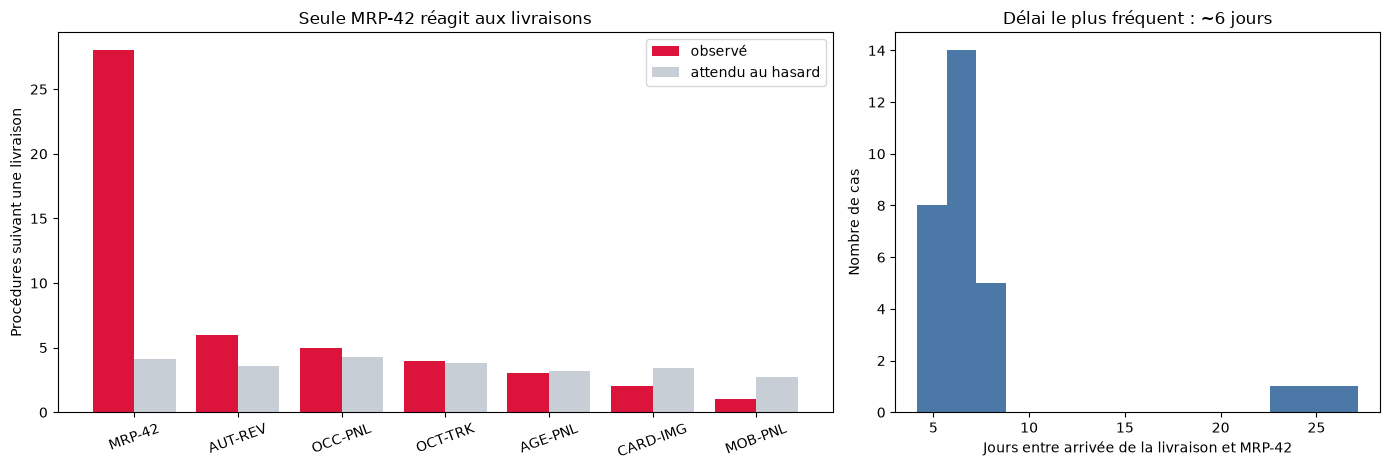

In [ ]:
#   Procédures réalisées ≤ 30 j après une livraison clinique : observé vs hasard (gauche) et délai pour MRP-42 (droite)
dfp = pd.DataFrame(lignes).sort_values("suivent_une_livraison", ascending=False); x = np.arange(len(dfp))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].bar(x - 0.2, dfp.suivent_une_livraison, 0.4, color="crimson", label="observé"); axes[0].bar(x + 0.2, dfp.attendu_hasard, 0.4, color="#c8ced6", label="attendu au hasard")
axes[0].set_xticks(x); axes[0].set_xticklabels(dfp.procedure, rotation=20); axes[0].set_ylabel("Procédures suivant une livraison"); axes[0].legend(); axes[0].set_title("Seule MRP-42 réagit aux livraisons")
axes[1].hist(lag[lag.delai_j.between(0, 30)].delai_j, bins=15, color="#4C78A8"); axes[1].set_xlabel("Jours entre arrivée de la livraison et MRP-42"); axes[1].set_ylabel("Nombre de cas"); axes[1].set_title("Délai le plus fréquent : ~6 jours")
plt.tight_layout(); plt.show()

En gris, c'est la probabilité qu'une procédure se produise par pur hasard dans les 30 jours suivant une livraison.

En rouge, c'est ce qui se passe dans la réalité.
On voit que pour presque toutes les procédures, les barres rouge et grise sont à peu près au même niveau (elles ne sont pas liées aux livraisons). En revanche, la procédure MRP-42 explose les compteurs : elle a lieu près de 30 fois après une livraison, contre seulement 4 fois attendues par hasard.

Cela prouve que le matériel clinique livré sous température contrôlée est bien utilisé spécifiquement pour réaliser ces fameuses "Administrations de résilience métabolique ciblée" (MRP-42), et que les équipes médicales ont besoin d'environ 6 jours pour préparer le produit reçu avant de l'injecter.

L'analyse révèle une association particulièrement forte entre les livraisons cliniques et une seule procédure : MRP-42 (« Targeted metabolic resilience administration »).
Sur les 49 réalisations de cette procédure dans les deux cliniques Asterion, 28 ont lieu dans les 30 jours suivant une livraison, contre environ 4 attendues au hasard (p < 0,01). Les six autres procédures ne présentent pas d'association significative avec les livraisons (p entre 0,13 et 0,94).
De plus, les 26 livraisons cliniques sont toutes suivies d'une procédure MRP-42 sur le même site, avec un délai médian de 6,5 jours (minimum : 4,2 jours).
Un autre élément important concerne les autorisations : les 49 procédures MRP-42 sont réalisées sous autorisation restreinte (30 restricted_specialist et 19 research_restricted) et concernent 27 patients. Aucune autre procédure ne présente ce niveau de restriction.
Ces résultats mettent donc en évidence un lien entre les approvisionnements de matériel à température dirigée (échantillons biologiques et consommables médicaux) et une procédure clinique spécifique soumise à des autorisations particulières. Cela permet d'établir un rapprochement entre les données logistiques et les activités médicales.

# LE SECRET DERRIÈRE LES LIVRAISONS : UN CIRCUIT BIOLOGIQUE SOUS HAUTE SURVEILLANCE

Au départ, tout ressemble à une activité logistique ordinaire : des entreprises de recherche, des transporteurs spécialisés, des entrepôts et des établissements médicaux. Pourtant, en croisant les données, une tout autre réalité commence à apparaître.

Une première organisation attire l'attention : **Horizon Field Research Cooperative**. Elle est à l'origine de 18 expéditions d'échantillons biologiques entre 2018 et 2025. Toutes suivent exactement le même circuit : Horizon expédie les échantillons à Meridian BioLogistics, par l'intermédiaire du transporteur Northstar Cold Chain Services. Les 18 envois sont conservés entre 2 et 8 °C. Plus troublant encore, 11 de ces 18 expéditions sont enregistrées comme des boucles : leur lieu d'origine et leur destination sont identiques. Une anomalie statistique majeure, pratiquement inexistante dans les autres livraisons.

Mais le véritable tournant de l'enquête arrive lorsque les expéditions sont rapprochées des autorisations d'accès aux sites environnementaux. **Les 18 accès demandés par Horizon sont tous suivis d'une expédition biologique dans les 48 heures**, avec un délai médian de seulement 15 heures. Parmi les 36 accès demandés par les autres organisations, aucun ne présente cette correspondance. Les 12 revues de sécurité enregistrées concernent également Horizon. Il ne s'agit donc pas simplement d'une entreprise qui expédie des échantillons : ses accès aux sites et ses mouvements logistiques présentent une synchronisation extrêmement inhabituelle.

En parallèle, les inventaires révèlent des quantités de matériel biologique qui ne sont plus correctement expliquées. Des déficits apparaissent notamment dans les établissements FCL-1019, FCL-1020 et FCL-1027. Au total, les écarts biologiques importants identifiés atteignent 175 unités. Les anomalies de traçabilité des ajustements rendent certains mouvements particulièrement difficiles à reconstituer.

L'enquête conduit ensuite à Meridian BioLogistics, qui ne semble pas seulement intervenir dans le circuit environnemental. Cette organisation expédie également du matériel biologique et des consommables médicaux vers les établissements du réseau Asterion. Et c'est là qu'apparaît une autre découverte : les 26 livraisons destinées aux programmes cliniques sont toutes suivies, sur le même site, d'une procédure médicale particulière appelée **MRP-42 – Targeted metabolic resilience administration**. Sur les 49 réalisations de cette procédure, 28 surviennent dans les 30 jours suivant une livraison, contre seulement 4,1 attendues selon les simulations aléatoires. Toutes sont réalisées sous autorisation restreinte et concernent 27 patients.

Les documents internes apportent une dernière pièce au puzzle : les désignations **CHAMELEO et Unwabu**. Ils décrivent un dispositif dans lequel les informations ordinaires sur les expéditions sont séparées des annexes sécurisées. Les employés des entrepôts ne disposent que des catégories et quantités déclarées, tandis que les itinéraires détaillés sont conservés par les équipes de sécurité et de conformité. La finalité réelle de ce dispositif reste inconnue.

Enfin, un témoignage attribué à Mara Venn évoque une possibilité encore plus inquiétante : des chauves-souris *Eonycteris spelaea* auraient été collectées, transportées dans des unités scellées, puis potentiellement utilisées à des fins de consommation. Le témoignage mentionne même des fiches de préparation portant le terme « consumption ». Si ces déclarations sont corroborées, elles pourraient donner une autre signification aux circuits biologiques découverts.

**Alors, que se passe-t-il réellement ?** Les données dessinent le scénario possible d'un système dans lequel des activités de recherche environnementale alimentent un circuit spécialisé de transport biologique, tandis qu'un autre flux approvisionne des programmes cliniques confidentiels. Entre les deux apparaissent des stocks incomplets, des autorisations de sécurité, des procédures médicales restreintes et des documents dont une partie échappe aux registres ordinaires.

Les données logistiques révèlent 18 expéditions environnementales organisées par Horizon Field Research Cooperative, transportées par Northstar Cold Chain Services et réceptionnées par Meridian BioLogistics.
Ces expéditions sont étroitement liées aux accès à des sites environnementaux, tandis que le témoignage de Mara Venn évoque la collecte de chauves-souris Eonycteris spelaea et leur transport dans des unités scellées.
Or, les chauves-souris possèdent des mécanismes de longévité et de protection cellulaire qui intéressent la recherche scientifique.
Cela soulève l'hypothèse que les échantillons transportés pourraient provenir de ces animaux et servir à des recherches sur la longévité ou la résilience métabolique.